# Etapa 10d · Comparativo dos dois caminhos: do zero ou pré-treinado?

| | |
|---|---|
| **Pergunta** | Com os mesmos professores e as mesmas regras, o que o encoder pré-treinado compra em qualidade, e quanto custa em tamanho e latência, em relação à rede feita do zero? |
| **Entrada** | As entregas das Etapas 2 a 9 (o caminho do zero, pelo catálogo da Etapa 9) e das Etapas 10a, 10b e 10c (o caminho do XLM-R): `decisao.json`, `resultados.csv`, `comparacoes.csv`, `eficiencia.csv` e as respostas de cada sistema em `dev` e no teste. E o que os comandos de `especialista/experimentos/etapa10d.py` gravaram em `data/execucoes/10d_comparativo_dos_caminhos/`: as regras, as respostas que nenhuma etapa tinha guardado, a latência medida na mesma sessão, a consulta das referências e as contas. |
| **Entrega** | `entregas/10d_comparativo_dos_caminhos/`: a tabela final estendida, as cadeias dos dois caminhos, as comparações pareadas, a fronteira, o preço de cada ponto, a latência lado a lado, o quadro de artigos, os limites, as regras e o manifesto. |
| **Pronto quando** | (1) as regras foram gravadas antes das contas, e as contas são as das regras; (2) a tabela tem as linhas da Etapa 9, idênticas, e as do XLM-R, com qualidade e intervalo em `dev` e no teste; (3) cada número de qualidade e cada diferença que uma etapa de origem gravou foi refeito das respostas, e o que não bate está relatado; (4) cada cadeia tem os degraus dos dois caminhos lado a lado; (5) a fronteira e o preço de cada ponto saem pelas regras; (6) a latência dos dois modelos finais foi medida na mesma sessão, com a máquina quieta, ou a falta disso está nos limites; (7) cada referência do quadro diz se foi conferida na fonte; (8) os limites dos dois caminhos estão juntos; (9) nada foi treinado, e a entrega tem manifesto e cópia do código. |

**O que esta etapa faz.** Nada é treinado. O projeto percorreu duas vezes o mesmo caminho (LLM professora, destilação, poda, reajuste, quantização): uma com uma rede pequena feita do zero, outra com um encoder pré-treinado. Aqui os dois caminhos são postos na mesma tabela e comparados ponto por ponto, com as mesmas respostas gravadas e a mesma régua.

**Artigos de apoio**

- Custo não é um número só, e cada medida precisa da sua condição: Dehghani et al., *The Efficiency Misnomer* ([arXiv 2110.12894](https://arxiv.org/abs/2110.12894)).
- Latência com uma consulta por vez, percentis e a máquina registrada: Reddi et al., *MLPerf Inference Benchmark* ([arXiv 1911.02549](https://arxiv.org/abs/1911.02549)).
- Intervalo e comparação pareada por bootstrap: Koehn ([EMNLP 2004](https://aclanthology.org/W04-3250/)); Berg-Kirkpatrick et al. ([EMNLP-CoNLL 2012](https://aclanthology.org/D12-1091/)).
- A rede do zero: Bunk et al., *DIET* ([arXiv 2004.09936](https://arxiv.org/abs/2004.09936)). O encoder pré-treinado com cabeça conjunta: Chen et al., *BERT for Joint Intent Classification and Slot Filling* ([arXiv 1902.10909](https://arxiv.org/abs/1902.10909)); Conneau et al., XLM-R ([arXiv 1911.02116](https://arxiv.org/abs/1911.02116)).

Os endereços acima foram consultados nesta etapa (seção 10, com o quadro de todos os passos).

**Roteiro**

1. O registro: quem entra, e de onde vem cada número
2. As regras, escritas antes das contas
3. A conta desta etapa é igual à das etapas de origem?
4. A tabela final, com os dois caminhos
5. As cadeias, lado a lado
6. Os dois caminhos no mesmo ponto
7. Cada aluno contra o seu professor, e de ponta a ponta
8. A fronteira e o preço de cada ponto
9. A latência dos dois modelos finais, na mesma sessão
10. Cada passo e o seu artigo
11. Rótulos humanos em cada ponto e limites
12. Entrega
13. Resposta

In [1]:
import importlib.metadata
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import qualidade
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa9, etapa10d

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

PASTA = entrega("10d_comparativo_dos_caminhos")
BASE = etapa10d.base_padrao()
TRES = etapa10d.TRES
API, GPU, CPU = etapa10d.API, etapa10d.GPU, etapa10d.CPU
ZERO, XLMR = etapa10d.ZERO, etapa10d.XLMR
CAMINHOS = etapa10d.caminhos_do_registro()

particoes, _ = massive.carregar_entrega()
N_TREINO, N_DEV, N_TESTE = (len(particoes[p]) for p in ("train", "dev", "test"))
NOME_DA_PARTICAO = {"dev": "dev", "test": "teste"}


def n(x):
    return f"{int(round(x)):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha, prefixo="", casas=1):
    """Uma diferença com o seu intervalo de 95%, em pontos percentuais: "−2,8 (−4,3 a −1,5)"."""
    d, a, b = (linha[prefixo + c] for c in (("diferenca", "dif_ic_min", "dif_ic_max") if prefixo else ("diferenca", "ic_min", "ic_max")))
    return f"{dif(d, casas)} ({dif(a, casas)} a {dif(b, casas)})"


def valor_com_intervalo(linha, metrica, prefixo=""):
    return f"{pts(linha[prefixo + metrica])} ({pts(linha[prefixo + metrica + '_ic_min'])} a {pts(linha[prefixo + metrica + '_ic_max'])})"


def posicao(minimo, maximo):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if minimo > 0 else "abaixo" if maximo < 0 else "sem diferença distinguível"


def metrica_na_frase(m):
    nome = qualidade.NOMES[m]
    return nome if nome.startswith("F1") else nome[0].lower() + nome[1:]


def ms(x):
    return "não medida" if pd.isna(x) else f"{n(x)} ms" if x >= 100 else f"{num(x, 2)} ms"


def tamanho(b):
    return "—" if pd.isna(b) else f"{num(b / 1e9, 1)} GB" if b >= 1e9 else f"{num(b / 1e6, 2 if b < 1e7 else 1)} MB"


def vezes(maior, menor):
    razao = maior / menor
    return n(razao) if razao >= 100 else num(razao, 1)


def em_markdown(tabela):
    linhas = ["| " + " | ".join(tabela.columns) + " |", "|" + "---|" * len(tabela.columns)]
    return "\n".join(linhas + ["| " + " | ".join(str(v) for v in linha) + " |" for linha in tabela.itertuples(index=False)])


def trio(linha, colunas=("diferenca", "ic_min", "ic_max")):
    return tuple(100 * linha[c] for c in colunas)


def lista(itens):
    """Uma enumeração numa frase. Se algum item já tem vírgula, os itens são separados por ponto e vírgula."""
    itens = list(itens)
    if any("," in item for item in itens):
        return "; ".join(itens)
    return itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]


def minusculo(texto):
    """A inicial em minúscula, para o meio de uma frase; siglas (INT8, ONNX) ficam como estão."""
    return texto if texto[:2].isupper() else texto[0].lower() + texto[1:]


def diferencas(dados, titulo, eixo_x):
    """`visual.diferencas_com_intervalo`, com o número das diferenças negativas à esquerda da barra."""
    fig, ax = visual.diferencas_com_intervalo(dados, titulo, eixo_x)
    for anotacao, (valor, minimo, maximo) in zip(ax.texts, dados.values()):
        if valor < 0:
            anotacao.xy = (minimo, anotacao.xy[1])
            anotacao.set_position((-7, 0))
            anotacao.set_ha("right")
    esquerda, direita = ax.get_xlim()
    ax.set_xlim(esquerda - 0.07 * (direita - esquerda), direita)
    return fig, ax

## 1. O registro: quem entra, e de onde vem cada número

A peça central da etapa é um **registro de sistemas** (`etapa10d.registro`). Cada sistema é uma ficha que diz em que arquivo está a qualidade, em que arquivos estão as respostas (em `dev` e no teste) e de que etapa vêm o tamanho e a latência. Nada no registro é número: ele só diz onde ler.

- **O caminho do zero** é o catálogo da Etapa 9 (`etapa9.catalogo`), sem mudança.
- **O caminho do XLM-R** é lido dos `decisao.json` das Etapas 10a, 10b e 10c: qual poda ficou, qual forma de 8 bits, qual temperatura, onde está cada modelo.
- Cada ficha leva quatro marcas: o **caminho**, o **modelo** (teto, piso, aluno A, B1 ou B2), o **ponto** da cadeia (sem compressão, destilado, podado, ONNX, INT8) e o **professor**. As comparações da seção 2 são geradas a partir dessas marcas.

**Feito para crescer.** Um sistema novo entra de dois jeitos, sem reescrever tabela: uma função nova em `etapa10d.FONTES`, que leia o `decisao.json` da etapa nova; ou um arquivo `sistemas.json` na entrega da etapa nova, que o registro lê sozinho. Com as marcas preenchidas, o sistema aparece na tabela, na fronteira e nas comparações que as regras geram.

Três grupos de respostas não estavam em nenhuma entrega, todos do caminho do zero. O comando `preparar` os produz na CPU, em segundos, carregando os modelos entregues pela Etapa 8, do mesmo jeito que a Etapa 9 fez para o teste:

```bash
uv run python -m especialista.experimentos.etapa10d preparar
```

In [2]:
fichas = etapa10d.registro()
assert not etapa10d.faltam(fichas), "Faltam respostas. Rode: uv run python -m especialista.experimentos.etapa10d preparar"
C = etapa10d.carregar_calculo()
T, CONF, CAD, PP, FRONT, PRECOS, LAT, CALC = (C[k] for k in ("tabela_final", "conferencia", "cadeias", "comparacoes", "fronteira", "precos", "latencia_ao_lado", "calculo"))
assert list(T.index) == list(fichas), "O cálculo gravado não é do registro de agora. Rode: uv run python -m especialista.experimentos.etapa10d calcular"
medidas = json.loads((BASE / "medidas.json").read_text(encoding="utf-8"))

FINAIS = etapa10d.finais(fichas)
FZ, FX = FINAIS[ZERO], FINAIS[XLMR]            # o modelo final de cada caminho
POUCOS, TODOS = int(T["rotulos_humanos"].min()), int(T["rotulos_humanos"].max())
PROFESSOR, ABERTO = T.loc["claude", "curto"], T.loc["qwen", "curto"]
FOLGA = CALC["folga_da_latencia"]
SEMENTES = len(etapa10d.SEMENTES)
PARES = list(dict.fromkeys(zip(PP["chave_b"], PP["chave_a"])))


def caminho_de(chave):
    c = T.loc[chave, "caminho"]
    return None if pd.isna(c) else c


def nome(chave):
    """O nome curto de um sistema, com o caminho na frente: "XLM-R · Aluno A, INT8"."""
    c = caminho_de(chave)
    return T.loc[chave, "curto"] if c is None else f"{CAMINHOS[c]['curto']} · {T.loc[chave, 'curto']}"


def comp(b, a, metrica="exact_match", particao="test"):
    """Uma comparação pareada B − A da lista fechada."""
    linhas = PP[(PP["chave_b"] == b) & (PP["chave_a"] == a) & (PP["metrica"] == metrica) & (PP["particao"] == particao)]
    assert len(linhas) == 1, (b, a, metrica, particao)
    return linhas.iloc[0]


def frase(b, a, particao="test", metricas=TRES):
    """Uma comparação em palavras: onde B fica em relação a A, métrica por métrica."""
    partes = [f"{posicao(l['ic_min'], l['ic_max'])} em {metrica_na_frase(m)} ({com_intervalo(l)})" for m in metricas for l in [comp(b, a, m, particao)]]
    return lista(partes)


def de_onde(chave, particao):
    caminhos = fichas[chave]["previsoes"][particao]
    if caminhos[0].is_relative_to(BASE):
        return "geradas nesta etapa (modelo da Etapa 8)" if fichas[chave]["gerar"]["como"] == "onnx" else "geradas nesta etapa (linha de base treinada de novo)"
    return str(caminhos[0].parent.relative_to(RAIZ)) + "/"


origem = pd.DataFrame([
    {"caminho": "os dois" if caminho_de(c) is None else CAMINHOS[caminho_de(c)]["curto"], "sistema": T.loc[c, "sistema"], "ponto": etapa10d.PONTOS[f["ponto"]], "sementes": f["sementes"],
     "qualidade lida de": T.loc[c, "qualidade_lida_de"], "respostas em dev": de_onde(c, "dev"), "respostas no teste": de_onde(c, "test"),
     "latência medida na": T.loc[c, "latencia_medida_na"] if pd.notna(T.loc[c, "latencia_medida_na"]) else "não medida"}
    for c, f in fichas.items()
])
display(origem.set_index(["caminho", "sistema"]))

por_caminho = T["caminho"].fillna("os dois").value_counts()
geradas = medidas["respostas_geradas"]
arquivos_gerados = sum(len(v) for g in geradas.values() for v in g["arquivos"].values())
display(Markdown(f"""
**Leitura.** São {len(fichas)} sistemas: {por_caminho[ZERO]} do caminho do zero, {por_caminho[XLMR]} do XLM-R e {por_caminho['os dois']} que os dois caminhos dividem (as duas LLMs professoras e as duas linhas de base).
As {len(etapa9.catalogo())} primeiras linhas são as da Etapa 9. As que esta etapa acrescenta ao caminho do zero são as do INT8 sem poda ({lista(T.loc[c, 'curto'] for c in fichas if fichas[c]['ponto'] == 'int8_sem_poda' and caminho_de(c) == ZERO)}), que a Etapa 8 entregou e a Etapa 9 não pôs na tabela: no XLM-R essa forma disputa a fronteira, e os dois caminhos precisam das mesmas linhas.
O modelo final de cada caminho, pelas decisões das Etapas 8 e 10c: **{T.loc[FZ, 'sistema']}** (do zero) e **{T.loc[FX, 'sistema']}** (XLM-R).
Respostas produzidas agora: {arquivos_gerados} arquivos de {len(geradas)} sistemas do caminho do zero (INT8 em `dev`, INT8 sem poda em `dev` e no teste, e a linha de base com {n(POUCOS)} rótulos em `dev`). Do XLM-R nada precisou ser refeito: a Etapa 10c guardou as respostas de todas as linhas.
"""))

ponto  \
caminho sistema                                                                                                   
os dois Linha de base com 299 rótulos                                                             Linha de base   
        Linha de base com 11.514 rótulos                                                          Linha de base   
        Claude Haiku 5.5 (professor fechado)                                                    Professor (LLM)   
        Qwen3-8B em 4 bits (professor aberto)                                                   Professor (LLM)   
Do zero Teto (DIET do zero com os 11.514 rótulos humanos)                                        Sem compressão   
        Piso (DIET do zero só com os 299 rótulos humanos)                                                  Piso   
        Aluno A (rótulos do Claude Haiku 5.5)                                                   Aluno destilado   
        Aluno B1 (rótulos do Qwen3-8B)                                                          Aluno destilado   
        Aluno B2 (logits do Qwen3-8B, T = 8)                                                    Aluno destilado   
        Aluno A, sem 90% das linhas da tabela de features, PyTorch, 32 bits                 Podado e reajustado   
        Aluno A, sem 90% das linhas da tabela de features, ONNX, 32 bits                          ONNX, 32 bits   
        Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica                      INT8   
        Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado   Pesos soltos, INT8   
        Aluno B2, sem 90% das linhas da tabela de features, PyTorch, 32 bits                Podado e reajustado   
        Aluno B2, sem 90% das linhas da tabela de features, ONNX, 32 bits                         ONNX, 32 bits   
        Aluno B2, sem 90% das linhas da tabela de features, INT8, quantização dinâmica                     INT8   
        Aluno B2, magnitude, 90% gradual, INT8, quantização dinâmica, arquivo compactado     Pesos soltos, INT8   
        Teto, sem 90% das linhas da tabela de features, PyTorch, 32 bits                    Podado e reajustado   
        Teto, sem 90% das linhas da tabela de features, ONNX, 32 bits                             ONNX, 32 bits   
        Teto, sem 90% das linhas da tabela de features, INT8, quantização dinâmica                         INT8   
        Teto, magnitude, 90% de uma vez, INT8, quantização dinâmica, arquivo compactado      Pesos soltos, INT8   
        Aluno A, sem poda, INT8, quantização dinâmica                                            INT8, sem poda   
        Aluno B2, sem poda, INT8, quantização dinâmica                                           INT8, sem poda   
        Teto, sem poda, INT8, quantização dinâmica                                               INT8, sem poda   
XLM-R   Teto (XLM-R base com os 11.514 rótulos humanos)                                          Sem compressão   
        Piso (XLM-R base só com os 299 rótulos humanos)                                                    Piso   
        Aluno A (rótulos do Claude Haiku 5.5)                                                   Aluno destilado   
        Aluno B1 (rótulos do Qwen3-8B)                                                          Aluno destilado   
        Aluno B2 (logits do Qwen3-8B, T = 2)                                                    Aluno destilado   
        Aluno A, vocabulário do treino, PyTorch, 32 bits                                    Podado e reajustado   
        Aluno A, vocabulário do treino, ONNX, 32 bits                                             ONNX, 32 bits   
        Aluno A, vocabulário do treino, INT8, quantização dinâmica                                         INT8   
        Aluno A, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado      Pesos soltos, INT8   
        Aluno A, sem poda, INT8, quantização dinâmica                            


**Leitura.** São 44 sistemas: 20 do caminho do zero, 20 do XLM-R e 4 que os dois caminhos dividem (as duas LLMs professoras e as duas linhas de base).
As 21 primeiras linhas são as da Etapa 9. As que esta etapa acrescenta ao caminho do zero são as do INT8 sem poda (Aluno A, INT8 sem poda; Aluno B2, INT8 sem poda; Teto, INT8 sem poda), que a Etapa 8 entregou e a Etapa 9 não pôs na tabela: no XLM-R essa forma disputa a fronteira, e os dois caminhos precisam das mesmas linhas.
O modelo final de cada caminho, pelas decisões das Etapas 8 e 10c: **Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica** (do zero) e **Aluno A, vocabulário do treino, INT8, quantização dinâmica** (XLM-R).
Respostas produzidas agora: 37 arquivos de 10 sistemas do caminho do zero (INT8 em `dev`, INT8 sem poda em `dev` e no teste, e a linha de base com 299 rótulos em `dev`). Do XLM-R nada precisou ser refeito: a Etapa 10c guardou as respostas de todas as linhas.


## 2. As regras, escritas antes das contas

As regras desta etapa estão em `regras.json`, gravado pelo comando abaixo **antes** de qualquer conta nova. O comando `calcular` não roda sem esse arquivo e guarda a impressão digital dele junto do que calculou.

```bash
uv run python -m especialista.experimentos.etapa10d regras
```

**O método é o do projeto.** Nenhuma decisão é tomada aqui: os modelos finais já foram escolhidos em `dev`, pelas regras das Etapas 6, 7, 8, 10a, 10b e 10c. Tudo é reportado em `dev` e no teste, contra os rótulos humanos; a leitura principal é a do teste. Um sistema treinado é a média das 3 sementes. Toda diferença é pareada, com bootstrap por enunciado, 2.000 reamostragens e intervalo de 95%; só vale quando o intervalo não contém zero. Não há correção para comparações múltiplas: as **primárias** são as do modelo final de um caminho contra o do outro, nas três métricas, no teste; as demais descrevem de onde a diferença vem.

**A lista de comparações é fechada e gerada por regra**, a partir das marcas do registro:

| Família | Regra |
|---|---|
| Entre caminhos | o mesmo modelo, no mesmo ponto da cadeia (sem compressão, piso, destilado, podado, INT8): XLM-R menos rede do zero. O ONNX de 32 bits fica de fora: nos dois caminhos ele dá as mesmas respostas do modelo podado |
| Finais | o modelo final do XLM-R menos o modelo final da rede do zero |
| Aluno e professor | cada aluno, como saiu da destilação e na forma final de 8 bits, menos a LLM que rotulou o treino dele, nos dois caminhos |
| De ponta a ponta | as dez comparações fixadas na Etapa 9, repetidas com as chaves de cada caminho |
| Poda nos 8 bits | em cada caminho, o modelo podado em INT8 menos o mesmo modelo em INT8 sem poda |
| Degraus das cadeias | em cada cadeia (cenário A, cenário B, teto; dois caminhos), cada degrau menos o anterior |

**A fronteira** usa a definição da Etapa 9 (`etapa9.nao_dominados`): um sistema é **dominado** quando existe outro com custo menor ou igual e exact match maior ou igual, e melhor em pelo menos um dos dois. Concorrem todos os sistemas do registro que usam só os poucos rótulos humanos, dos dois caminhos. Duas latências mais próximas que a maior variação da mediana entre as rodadas das medidas de origem contam como empate; o tamanho não tem folga; a qualidade é comparada pelo valor medido.

**O preço de cada ponto**, entre os dois modelos finais: (custo do final do XLM-R − custo do final do zero) ÷ (diferença de exact match, em pontos). O intervalo vem do intervalo de 95% da diferença pareada de exact match, e o preço só é definido quando esse intervalo está todo acima de zero.

**A latência na mesma sessão**: os dois modelos finais, semente 0, em INT8, ONNX de 32 bits e PyTorch de 32 bits, no protocolo das Etapas 8 e 10c. Os números de origem continuam sendo os da tabela; a medida nova vai ao lado e "confirma" a de origem quando a diferença relativa é menor que a folga da fronteira.

In [3]:
regras, arquivo_das_regras = etapa10d.carregar_regras()
versoes = sorted((json.loads(c.read_text(encoding="utf-8")) for c in BASE.glob("regras*.json")), key=lambda r: r["versao"])
mesmos_pares = all([(c["b"], c["a"], c["familias"]) for c in v["comparacoes"]] == [(c["b"], c["a"], c["familias"]) for c in versoes[0]["comparacoes"]] for v in versoes)
so_o_texto = all({k for k in v if v[k] != versoes[0][k]} <= {"versao", "gravado_em", "comparacoes"} for v in versoes)
regras_antes = bool(regras["gravado_em"] < CALC["calculado_em"] and CALC["regras"]["sha256"] == etapa10d.sha256(arquivo_das_regras) and CALC["regras"]["versao"] == regras["versao"])
lista_das_regras = [(c["b"], c["a"]) for c in regras["comparacoes"]]
contas_sao_as_das_regras = bool(PARES == lista_das_regras and list(dict.fromkeys(CAD["cadeia"])) == list(regras["cadeias"]) and not PP["exploratoria"].any())

familias = pd.Series([f for c in regras["comparacoes"] for f in c["familias"]]).value_counts()
NOME_DA_FAMILIA = {"entre_caminhos": "Entre caminhos", "finais": "Finais", "aluno_professor": "Aluno e professor", "ponta_a_ponta": "De ponta a ponta", "poda_nos_8_bits": "Poda nos 8 bits"}
degraus_por_particao = int(CAD[(CAD["particao"] == "test")]["anterior"].notna().sum())
display(pd.DataFrame({"comparações": familias.rename(index=NOME_DA_FAMILIA)}))
display(pd.DataFrame([{"comparação (B − A)": f"{nome(c['b'])} − {nome(c['a'])}", "famílias": "; ".join(NOME_DA_FAMILIA[f] for f in c["familias"]), "o que responde": c["pergunta"]} for c in regras["comparacoes"]]))

em_duas = sum(len(c["familias"]) > 1 for c in regras["comparacoes"])
display(Markdown(f"""
**Leitura.** A lista tem {len(regras['comparacoes'])} comparações ({em_duas} caem em duas famílias e são contadas uma vez) e {len(regras['cadeias'])} cadeias, com {degraus_por_particao} degraus. Cada uma é calculada em `dev` e no teste.
As regras foram gravadas em {versoes[0]['gravado_em'].replace('T', ' às ')}{f" (versão 1) e em {regras['gravado_em'].replace('T', ' às ')} (versão {regras['versao']})" if len(versoes) > 1 else ""}; as contas, em {CALC['calculado_em'].replace('T', ' às ')}.
{f"A versão {regras['versao']} só corrige o texto que descreve cada comparação: os pares e as famílias são os mesmos da versão 1 ({'conferido' if mesmos_pares and so_o_texto else '**NÃO CONFERE**'}), e as duas foram gravadas antes das contas." if len(versoes) > 1 else ""}
As contas gravadas são exatamente as da lista: {"sim" if contas_sao_as_das_regras else "**NÃO**"}; nenhuma comparação foi acrescentada depois.

**O que já era conhecido quando as regras foram escritas** (está no próprio `regras.json`): {"; ".join(regras['ja_era_conhecido_ao_escrever'][:3])}. As regras não foram escritas no escuro: quem as escreveu já tinha lido os resumos das etapas anteriores. O que elas garantem é que a lista não foi escolhida depois de ver as contas novas.
"""))
assert regras_antes and contas_sao_as_das_regras and mesmos_pares and so_o_texto

,comparações
De ponta a ponta,20
Entre caminhos,11
Aluno e professor,10
Poda nos 8 bits,6
Finais,1


,comparação (B − A),famílias,o que responde
0,XLM-R · Teto − Do zero · Teto,Entre caminhos,Teto: XLM-R menos a rede do zero
1,XLM-R · Piso − Do zero · Piso,Entre caminhos,Piso: XLM-R menos a rede do zero
2,XLM-R · Aluno A − Do zero · Aluno A,Entre caminhos,Aluno A: XLM-R menos a rede do zero
3,XLM-R · Aluno B1 − Do zero · Aluno B1,Entre caminhos,Aluno B1: XLM-R menos a rede do zero
4,XLM-R · Aluno B2 − Do zero · Aluno B2,Entre caminhos,Aluno B2: XLM-R menos a rede do zero
5,"XLM-R · Aluno A, podado − Do zero · Aluno A, podado",Entre caminhos,"Aluno A, podado: XLM-R menos a rede do zero"
6,"XLM-R · Aluno A, INT8 − Do zero · Aluno A, INT8",Entre caminhos; Finais,"Aluno A, INT8: XLM-R menos a rede do zero"
7,"XLM-R · Aluno B2, podado − Do zero · Aluno B2, podado",Entre caminhos,"Aluno B2, podado: XLM-R menos a rede do zero"
8,"XLM-R · Aluno B2, INT8 − Do zero · Aluno B2, INT8",Entre caminhos,"Aluno B2, INT8: XLM-R menos a rede do zero"
9,"XLM-R · Teto, podado − Do zero · Teto, podado",Entre caminhos,"Teto, podado: XLM-R menos a rede do zero"



**Leitura.** A lista tem 43 comparações (5 caem em duas famílias e são contadas uma vez) e 6 cadeias, com 22 degraus. Cada uma é calculada em `dev` e no teste.
As regras foram gravadas em 2026-11-18 às 20:54:00 (versão 1) e em 2026-11-18 às 20:54:25 (versão 2); as contas, em 2026-11-18 às 21:15:27.
A versão 2 só corrige o texto que descreve cada comparação: os pares e as famílias são os mesmos da versão 1 (conferido), e as duas foram gravadas antes das contas.
As contas gravadas são exatamente as da lista: sim; nenhuma comparação foi acrescentada depois.

**O que já era conhecido quando as regras foram escritas** (está no próprio `regras.json`): as comparações entre caminhos nos modelos sem poda (teto, piso, alunos A, B1 e B2) já estavam no RESUMO da Etapa 10a; os degraus de cada cadeia e as comparações de ponta a ponta do caminho do zero já estavam nas Etapas 6 a 10c; os valores de qualidade, tamanho e latência de cada sistema, um a um, já estavam nos RESUMOs. As regras não foram escritas no escuro: quem as escreveu já tinha lido os resumos das etapas anteriores. O que elas garantem é que a lista não foi escolhida depois de ver as contas novas.


## 3. A conta desta etapa é igual à das etapas de origem?

Antes de comparar, a conferência. Cada número que uma etapa de origem gravou é refeito aqui, a partir das respostas, e comparado com o gravado:

- **a qualidade de cada sistema** (as quatro métricas e os limites dos intervalos), em `dev` e no teste, contra o `resultados.csv` da etapa que o mediu; quando duas etapas gravaram o mesmo número (o modelo sem poda do XLM-R, na 10a e na 10c; o podado, na 10b e na 10c; o podado da rede do zero, na 7 e na 8), as duas são conferidas;
- **cada degrau de cada cadeia**, contra o `comparacoes.csv` da etapa que deu aquele passo;
- **as comparações entre caminhos nos modelos sem poda**, contra as que a Etapa 10a gravou, e **as de ponta a ponta do caminho do zero**, contra as da Etapa 9;
- **as linhas da tabela final da Etapa 9**, coluna por coluna, contra as mesmas linhas da tabela estendida.

A regra da etapa: se um número não bate, ele é **relatado**, não consertado.

In [4]:
CONF["situacao"] = np.where(~CONF["gravado"].astype(bool), "sem número gravado na origem", np.where(CONF["confere"] == True, "igual", "DIFERENTE"))   # noqa: E712
resumo_da_conferencia = CONF.groupby(["o_que", "particao", "situacao"]).size().unstack(fill_value=0).reset_index()
for coluna in ("igual", "DIFERENTE", "sem número gravado na origem"):
    if coluna not in resumo_da_conferencia.columns:
        resumo_da_conferencia[coluna] = 0
resumo_da_conferencia = resumo_da_conferencia.rename(columns={"o_que": "o que foi conferido", "particao": "partição"})[["o que foi conferido", "partição", "igual", "DIFERENTE", "sem número gravado na origem"]]
display(resumo_da_conferencia.set_index(["o que foi conferido", "partição"]))

conferidas = CONF[CONF["gravado"].astype(bool)]
diferentes = conferidas[conferidas["confere"] != True]   # noqa: E712
sem_origem = CONF[~CONF["gravado"].astype(bool)]
maior = float(conferidas["maior_diferenca"].max())
por_tipo = conferidas.groupby("o_que").size()
QUALIDADE, DEGRAU, COMPARACAO, LINHA_DA_9 = "qualidade de um sistema", "degrau de uma cadeia", "comparação entre sistemas", "linha da tabela final da Etapa 9"
if len(diferentes):
    display(diferentes)
if len(sem_origem):
    display(sem_origem[["o_que", "chave", "anterior", "particao", "gravado_em"]])
geradas_agora = conferidas[(conferidas["o_que"] == QUALIDADE) & (conferidas["respostas_geradas_agora"] == True)]   # noqa: E712
display(Markdown(f"""
**Leitura.** Foram conferidas **{n(len(conferidas))} linhas**: {n(por_tipo[QUALIDADE])} de qualidade ({len(fichas)} sistemas, em `dev` e no teste, contra cada etapa que gravou o número), {n(por_tipo[DEGRAU])} degraus de cadeia, {n(por_tipo[COMPARACAO])} comparações entre sistemas e {n(por_tipo[LINHA_DA_9])} linhas da tabela final da Etapa 9.
{"**Todas iguais**" if not len(diferentes) else f"**{len(diferentes)} DIFERENTES** (na tabela acima)"}: a maior diferença entre a conta desta etapa e um número gravado é de {maior:.1e} (em fração, não em pontos).
{f"Entre elas estão as {len(geradas_agora)} linhas dos sistemas cujas respostas foram produzidas agora: os modelos da Etapa 8, carregados de novo, dão em `dev` e no teste exatamente as métricas que a Etapa 8 gravou." if len(geradas_agora) else ""}
{f"Sem número na origem para conferir: {len(sem_origem)} linha(s), na tabela acima." if len(sem_origem) else "Nenhuma linha ficou sem número de origem para conferir."}
"""))

situacao                                   igual  DIFERENTE  \
o que foi conferido              partição                     
comparação entre sistemas        dev           5          0   
                                 test         15          0   
degrau de uma cadeia             dev          22          0   
                                 test         22          0   
linha da tabela final da Etapa 9 test         21          0   
qualidade de um sistema          dev          53          0   
                                 test         53          0   

situacao                                   sem número gravado na origem  
o que foi conferido              partição                                
comparação entre sistemas        dev                                  0  
                                 test                                 0  
degrau de uma cadeia             dev                                  0  
                                 test                                 0  
linha da tabela final da Etapa 9 test                                 0  
qualidade de um sistema          dev                                  0  
                                 test                                 0


**Leitura.** Foram conferidas **191 linhas**: 106 de qualidade (44 sistemas, em `dev` e no teste, contra cada etapa que gravou o número), 44 degraus de cadeia, 20 comparações entre sistemas e 21 linhas da tabela final da Etapa 9.
**Todas iguais**: a maior diferença entre a conta desta etapa e um número gravado é de 0.0e+00 (em fração, não em pontos).
Entre elas estão as 13 linhas dos sistemas cujas respostas foram produzidas agora: os modelos da Etapa 8, carregados de novo, dão em `dev` e no teste exatamente as métricas que a Etapa 8 gravou.
Nenhuma linha ficou sem número de origem para conferir.


## 4. A tabela final, com os dois caminhos

Uma linha por sistema, no teste. Qualidade em %, com intervalo de 95%; nos sistemas treinados, média das 3 sementes. Tamanho e latência dos modelos comprimidos são os da semente 0. As colunas são as da Etapa 9, mais a do caminho. A mesma tabela, com a qualidade em `dev` nas colunas `dev_...`, está em `tabela_final.csv`.

In [5]:
def onde_curto(chave):
    s = T.loc[chave]
    return "não medida" if pd.isna(s["latencia_p50_ms"]) else f"{s['condicao_da_latencia']}: {fichas[chave]['onde']} ({s['latencia_medida_na']})"


def linha_da_tabela(chave):
    s = T.loc[chave]
    oculto = not s["divulgado"]
    c = caminho_de(chave)
    return {
        "Caminho": "os dois" if c is None else CAMINHOS[c]["curto"],
        "Sistema": s["sistema"] + (" **(modelo final)**" if s["final"] else ""),
        "Rótulos humanos": f"{n(s['rotulos_humanos'])} ({s['rotulos_como']})",
        "Acurácia de intenção": valor_com_intervalo(s, "intent_acc"), "F1 de entidades": valor_com_intervalo(s, "slot_f1"), "Exact match": valor_com_intervalo(s, "exact_match"),
        "Parâmetros": "não divulgado" if oculto else n(s["parametros"]),
        "Tamanho em disco": "não divulgado" if oculto else "não medido" if pd.isna(s["bytes"]) else tamanho(s["bytes"]),
        "Com zip": tamanho(s["bytes_com_zip"]),
        "Latência p50": ms(s["latencia_p50_ms"]), "Onde a latência foi medida": onde_curto(chave),
        "Consultas por segundo": "—" if pd.isna(s["consultas_por_segundo"]) else num(s["consultas_por_segundo"], 1) if s["consultas_por_segundo"] < 10 else n(s["consultas_por_segundo"]),
        "US$ por 1.000 consultas": "—" if pd.isna(s["custo_por_mil_usd"]) else num(s["custo_por_mil_usd"], 3),
    }


mostra = pd.DataFrame([linha_da_tabela(chave) for chave in fichas])
display(Markdown(em_markdown(mostra)))

fz, fx, p = T.loc[FZ], T.loc[FX], T.loc["claude"]
eficiencia10c = pd.read_csv(ENTREGAS / "10c_encoder_quantizacao" / "eficiencia.csv")
maquina = {"cpu": eficiencia10c["cpu"].iloc[0], "gpu": pd.read_csv(ENTREGAS / "05b_professor_aberto" / "resultados.csv")["gpu"].iloc[0], "vnni": bool(eficiencia10c["tem_vnni"].iloc[0])}
tres = lambda s: f"{pts(s['intent_acc'])} / {pts(s['slot_f1'])} / {pts(s['exact_match'])}"
notas_da_tabela = [
    f"**Máquina.** CPU local: {maquina['cpu']}. GPU local: {maquina['gpu']}. A API foi chamada desta máquina.",
    f"**Rótulos humanos.** \"no prompt\": a LLM vê {n(POUCOS)} exemplos rotulados por humanos. \"pelo professor\": a rede nunca vê um rótulo humano de treino; aprende com os {n(TODOS)} pedidos rotulados pela LLM. Onde os rótulos humanos de `dev` entraram em decisões está na seção 11.",
    "**Latência.** As do caminho do zero são da Etapa 8 e as do XLM-R, da Etapa 10c: mesmo protocolo, sessões diferentes. A seção 9 mede os dois modelos finais na mesma sessão. Do piso e do aluno B1 do XLM-R a latência não foi medida (a rede é a mesma do aluno A sem poda).",
    "**Tamanho.** É o do sistema inteiro como é usado; no XLM-R inclui o tokenizador. Os sistemas de pesos soltos em INT8 são entregues compactados: o tamanho deles em disco é o da coluna \"com zip\".",
    "**INT8 sem poda.** O mesmo modelo quantizado sem passar pela poda. Não é o modelo final de nenhum caminho (a regra da poda escolheu o menor arquivo que não se distingue do modelo sem poda em `dev`); entra porque foi entregue e disputa a fronteira.",
]
display(Markdown("\n".join(f"- {nota}" for nota in notas_da_tabela) + f"""

**Leitura.** No teste, o modelo final do XLM-R faz {tres(fx)} (intenção / entidades / exact match) com {tamanho(fx['bytes'])} e {ms(fx['latencia_p50_ms'])} por consulta; o da rede do zero faz {tres(fz)} com {tamanho(fz['bytes'])} e {ms(fz['latencia_p50_ms'])}.
São {vezes(fx['bytes'], fz['bytes'])} vezes o tamanho e {vezes(fx['latencia_p50_ms'], fz['latencia_p50_ms'])} vezes a latência. As seções seguintes dizem quais diferenças de qualidade se distinguem de zero e de que ponto do caminho elas vêm.
"""))

| Caminho | Sistema | Rótulos humanos | Acurácia de intenção | F1 de entidades | Exact match | Parâmetros | Tamanho em disco | Com zip | Latência p50 | Onde a latência foi medida | Consultas por segundo | US$ por 1.000 consultas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| os dois | Linha de base com 299 rótulos | 299 (no treino) | 47,8 (46,0 a 49,6) | 35,6 (33,7 a 37,5) | 19,4 (18,1 a 20,8) | 552.636 | não medido | — | não medida | não medida | — | — |
| os dois | Linha de base com 11.514 rótulos | 11.514 (no treino) | 84,6 (83,3 a 85,8) | 47,8 (45,9 a 49,7) | 45,2 (43,5 a 47,0) | 3.940.300 | 33,0 MB | — | 0,82 ms | CPU local: scikit-learn, threads não registradas (Etapa 2) | 1.172 | — |
| os dois | Claude Haiku 5.5 (professor fechado) | 299 (no prompt) | 83,5 (82,1 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) | não divulgado | não divulgado | — | 854 ms | API pela rede: rede do usuário, Brasil, uma chamada por vez (Etapa 5a) | 1,1 | 0,114 |
| os dois | Qwen3-8B em 4 bits (professor aberto) | 299 (no prompt) | 77,6 (76,1 a 79,1) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) | 8.190.735.360 | 16,4 GB | — | 1.087 ms | GPU local: um pedido por vez (Etapa 5b) | 0,8 | — |
| Do zero | Teto (DIET do zero com os 11.514 rótulos humanos) | 11.514 (no treino) | 84,4 (83,2 a 85,6) | 73,6 (72,2 a 75,1) | 62,5 (60,8 a 64,1) | 4.895.834 | 19,9 MB | 18,2 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 882 | — |
| Do zero | Piso (DIET do zero só com os 299 rótulos humanos) | 299 (no treino) | 40,1 (38,6 a 41,5) | 40,8 (39,1 a 42,4) | 20,9 (19,6 a 22,2) | 2.154.586 | 8,73 MB | — | 1,12 ms | CPU local: 1 thread, PyTorch (Etapa 6) | 877 | — |
| Do zero | Aluno A (rótulos do Claude Haiku 5.5) | 299 (pelo professor) | 80,7 (79,4 a 82,0) | 64,8 (63,2 a 66,5) | 51,2 (49,6 a 52,9) | 4.895.834 | 19,9 MB | 18,2 MB | 1,11 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 876 | — |
| Do zero | Aluno B1 (rótulos do Qwen3-8B) | 299 (pelo professor) | 76,3 (74,9 a 77,7) | 57,1 (55,4 a 58,9) | 43,6 (41,9 a 45,2) | 4.895.834 | 19,9 MB | — | 1,13 ms | CPU local: 1 thread, PyTorch (Etapa 6) | 866 | — |
| Do zero | Aluno B2 (logits do Qwen3-8B, T = 8) | 299 (pelo professor) | 77,8 (76,3 a 79,3) | 58,0 (56,3 a 59,8) | 46,0 (44,2 a 47,6) | 4.895.834 | 19,9 MB | 18,2 MB | 1,11 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 876 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,8 (63,3 a 66,4) | 51,3 (49,6 a 52,9) | 1.992.538 | 8,06 MB | 7,39 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 881 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, ONNX, 32 bits | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,8 (63,3 a 66,4) | 51,3 (49,6 a 52,9) | 1.992.538 | 7,98 MB | — | 0,43 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.308 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica **(modelo final)** | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,9 (63,3 a 66,4) | 51,2 (49,5 a 52,9) | 1.992.538 | 2,11 MB | 1,70 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.615 | — |
| Do zero | Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 79,8 (78,5 a 81,1) | 64,3 (62,7 a 66,0) | 50,3 (48,6 a 52,0) | 4.895.834 | 5,26 MB | 0,92 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.520 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 299 (pelo professor) | 77,8 (76,4 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 8,06 MB | 7,40 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 880 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, ONNX, 32 bits | 299 (pelo professor) | 77,8 (76,4 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 7,98 MB | — | 0,42 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.313 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | 299 (pelo professor) | 77,8 (76,3 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 2,11 MB | 1,72 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.631 | — |
| Do zero | Aluno B2, magnitude, 90% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 77,5 (76,1 a 78,9) | 58,6 (56,9 a 60,4) | 46,1 (44,4 a 47,8) | 4.895.834 | 5,26 MB | 1,26 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.472 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 11.514 (no treino) | 83,4 (82,2 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,6 a 62,9) | 1.992.538 | 8,06 MB | 7,39 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 883 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, ONNX, 32 bits | 11.514 (no treino) | 83,4 (82,2 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,6 a 62,9) | 1.992.538 | 7,98 MB | — | 0,43 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.311 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | 11.514 (no treino) | 83,4 (82,1 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,7 a 62,9) | 1.992.538 | 2,11 MB | 1,73 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.670 | — |
| Do zero | Teto, magnitude, 90% de uma vez, INT8, quantização dinâmica, arquivo compactado | 11.514 (no treino) | 83,9 (82,6 a 85,1) | 73,4 (71,9 a 74,9) | 61,7 (60,0 a 63,3) | 4.895.834 | 5,26 MB | 1,31 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.535 | — |
| Do zero | Aluno A, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 80,7 (79,3 a 82,0) | 64,8 (63,2 a 66,5) | 51,3 (49,6 a 52,9) | 4.895.834 | 5,26 MB | 4,35 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.638 | — |
| Do zero | Aluno B2, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 77,9 (76,4 a 79,3) | 58,1 (56,4 a 59,9) | 45,9 (44,2 a 47,6) | 4.895.834 | 5,26 MB | 4,39 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.512 | — |
| Do zero | Teto, sem poda, INT8, quantização dinâmica | 11.514 (no treino) | 84,3 (83,1 a 85,5) | 73,7 (72,2 a 75,1) | 62,5 (60,8 a 64,1) | 4.895.834 | 5,26 MB | 4,40 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.554 | — |
| XLM-R | Teto (XLM-R base com os 11.514 rótulos humanos) | 11.514 (no treino) | 86,9 (85,8 a 88,0) | 75,5 (74,0 a 77,0) | 66,3 (64,7 a 67,9) | 277.584.555 | 1,1 GB | 832,3 MB | 37,06 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Piso (XLM-R base só com os 299 rótulos humanos) | 299 (no treino) | 54,7 (53,1 a 56,3) | 52,8 (51,1 a 54,5) | 32,6 (31,1 a 34,2) | 277.584.555 | 1,1 GB | — | não medida | não medida | — | — |
| XLM-R | Aluno A (rótulos do Claude Haiku 5.5) | 299 (pelo professor) | 82,6 (81,4 a 84,0) | 65,5 (64,0 a 67,2) | 53,8 (52,1 a 55,4) | 277.584.555 | 1,1 GB | 832,1 MB | 35,82 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 27 | — |
| XLM-R | Aluno B1 (rótulos do Qwen3-8B) | 299 (pelo professor) | 78,7 (77,2 a 80,1) | 58,5 (56,8 a 60,2) | 45,7 (44,0 a 47,4) | 277.584.555 | 1,1 GB | — | não medida | não medida | — | — |
| XLM-R | Aluno B2 (logits do Qwen3-8B, T = 2) | 299 (pelo professor) | 78,9 (77,5 a 80,3) | 58,8 (57,1 a 60,5) | 46,3 (44,6 a 48,0) | 277.584.555 | 1,1 GB | 832,3 MB | 37,58 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Aluno A, vocabulário do treino, PyTorch, 32 bits | 299 (pelo professor) | 82,9 (81,6 a 84,2) | 65,1 (63,5 a 66,8) | 53,7 (52,0 a 55,3) | 89.573.547 | 359,0 MB | 333,0 MB | 36,10 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 27 | — |
| XLM-R | Aluno A, vocabulário do treino, ONNX, 32 bits | 299 (pelo professor) | 82,9 (81,6 a 84,2) | 65,1 (63,5 a 66,8) | 53,7 (52,0 a 55,3) | 89.573.547 | 358,9 MB | — | 25,08 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 38 | — |
| XLM-R | Aluno A, vocabulário do treino, INT8, quantização dinâmica **(modelo final)** | 299 (pelo professor) | 82,4 (81,2 a 83,7) | 65,1 (63,5 a 66,7) | 53,5 (51,8 a 55,1) | 89.573.547 | 90,7 MB | 60,5 MB | 8,35 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Aluno A, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 82,0 (80,8 a 83,3) | 64,2 (62,6 a 65,8) | 52,9 (51,1 a 54,6) | 277.584.555 | 287,3 MB | 189,9 MB | 8,37 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Aluno A, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 82,8 (81,5 a 84,1) | 65,6 (64,0 a 67,2) | 54,5 (52,8 a 56,1) | 277.584.555 | 287,3 MB | 215,4 MB | 8,33 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 116 | — |
| XLM-R | Aluno B2, vocabulário do treino, PyTorch, 32 bits | 299 (pelo professor) | 78,4 (77,0 a 79,8) | 57,9 (56,2 a 59,6) | 45,2 (43,5 a 47,0) | 89.573.547 | 359,0 MB | 333,0 MB | 36,80 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Aluno B2, vocabulário do treino, ONNX, 32 bits | 299 (pelo professor) | 78,4 (77,0 a 79,8) | 57,9 (56,2 a 59,6) | 45,2 (43,5 a 47,0) | 89.573.547 | 358,9 MB | — | 24,33 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 39 | — |
| XLM-R | Aluno B2, vocabulário do treino, INT8, quantização dinâmica | 299 (pelo professor) | 78,2 (76,9 a 79,6) | 57,6 (56,0 a 59,4) | 45,2 (43,5 a 46,9) | 89.573.547 | 90,7 MB | 60,5 MB | 7,94 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 121 | — |
| XLM-R | Aluno B2, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 78,1 (76,7 a 79,5) | 58,4 (56,7 a 60,1) | 45,7 (44,0 a 47,3) | 277.584.555 | 287,3 MB | 189,8 MB | 8,01 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 121 | — |
| XLM-R | Aluno B2, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 79,0 (77,7 a 80,4) | 58,5 (56,9 a 60,2) | 46,6 (44,9 a 48,3) | 277.584.555 | 287,3 MB | 215,6 MB | 8,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 117 | — |
| XLM-R | Teto, vocabulário do treino, PyTorch, 32 bits | 11.514 (no treino) | 86,7 (85,5 a 87,7) | 74,9 (73,4 a 76,4) | 65,8 (64,2 a 67,4) | 89.573.547 | 359,0 MB | 333,0 MB | 37,54 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Teto, vocabulário do treino, ONNX, 32 bits | 11.514 (no treino) | 86,7 (85,5 a 87,7) | 74,9 (73,4 a 76,4) | 65,8 (64,2 a 67,4) | 89.573.547 | 358,9 MB | — | 25,35 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 37 | — |
| XLM-R | Teto, vocabulário do treino, INT8, quantização dinâmica | 11.514 (no treino) | 86,3 (85,2 a 87,4) | 74,6 (73,1 a 76,1) | 65,7 (64,1 a 67,2) | 89.573.547 | 90,7 MB | 60,5 MB | 8,50 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 113 | — |
| XLM-R | Teto, magnitude, 50% de uma vez, INT8, quantização dinâmica, arquivo compactado | 11.514 (no treino) | 86,6 (85,5 a 87,8) | 74,4 (72,9 a 75,9) | 65,6 (64,0 a 67,1) | 277.584.555 | 287,3 MB | 202,3 MB | 8,37 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Teto, sem poda, INT8, quantização dinâmica | 11.514 (no treino) | 86,8 (85,6 a 87,9) | 74,9 (73,4 a 76,4) | 66,1 (64,5 a 67,7) | 277.584.555 | 287,3 MB | 215,5 MB | 8,39 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |

- **Máquina.** CPU local: 13th Gen Intel(R) Core(TM) i7-13700K. GPU local: NVIDIA GeForce RTX 3080. A API foi chamada desta máquina.
- **Rótulos humanos.** "no prompt": a LLM vê 299 exemplos rotulados por humanos. "pelo professor": a rede nunca vê um rótulo humano de treino; aprende com os 11.514 pedidos rotulados pela LLM. Onde os rótulos humanos de `dev` entraram em decisões está na seção 11.
- **Latência.** As do caminho do zero são da Etapa 8 e as do XLM-R, da Etapa 10c: mesmo protocolo, sessões diferentes. A seção 9 mede os dois modelos finais na mesma sessão. Do piso e do aluno B1 do XLM-R a latência não foi medida (a rede é a mesma do aluno A sem poda).
- **Tamanho.** É o do sistema inteiro como é usado; no XLM-R inclui o tokenizador. Os sistemas de pesos soltos em INT8 são entregues compactados: o tamanho deles em disco é o da coluna "com zip".
- **INT8 sem poda.** O mesmo modelo quantizado sem passar pela poda. Não é o modelo final de nenhum caminho (a regra da poda escolheu o menor arquivo que não se distingue do modelo sem poda em `dev`); entra porque foi entregue e disputa a fronteira.

**Leitura.** No teste, o modelo final do XLM-R faz 82,4 / 65,1 / 53,5 (intenção / entidades / exact match) com 90,7 MB e 8,35 ms por consulta; o da rede do zero faz 80,2 / 64,9 / 51,2 com 2,11 MB e 0,26 ms.
São 42,9 vezes o tamanho e 32,0 vezes a latência. As seções seguintes dizem quais diferenças de qualidade se distinguem de zero e de que ponto do caminho elas vêm.


## 5. As cadeias, lado a lado

Cada cadeia é lida de cima para baixo, e em cada degrau muda uma coisa só. Os degraus são os mesmos nos dois caminhos; o que cada um faz, não:

| Degrau | Rede do zero | XLM-R |
|---|---|---|
| Professor (LLM) | o ponto de partida: a LLM resolvendo a tarefa | o mesmo professor, as mesmas respostas |
| Aluno destilado | a rede do zero aprende com os rótulos (e, no cenário B, os logits) da LLM (Etapa 6) | o XLM-R é ajustado com os mesmos rótulos e logits (Etapa 10a) |
| Podado e reajustado | saem 90% das linhas da tabela de features (Etapa 7) | a tabela de subtokens fica só com o vocabulário do treino (Etapa 10b) |
| ONNX, 32 bits | a rede sai do PyTorch e roda no ONNX Runtime (Etapa 8) | o mesmo (Etapa 10c) |
| INT8 | os pesos passam de 32 para 8 bits, quantização dinâmica (Etapa 8) | o mesmo (Etapa 10c) |

A coluna "diferença para o degrau anterior" é pareada: diz o que aquele passo, sozinho, fez com a qualidade.

### Cenário A: professor fechado

,Do zero: exact match,Do zero: diferença para o anterior,Do zero: tamanho,Do zero: latência p50,XLM-R: exact match,XLM-R: diferença para o anterior,XLM-R: tamanho,XLM-R: latência p50
Degrau,,,,,,,,
Professor (LLM),"54,0 (52,3 a 55,7)",—,não divulgado,854 ms,"54,0 (52,3 a 55,7)",—,não divulgado,854 ms
Aluno destilado,"51,2 (49,6 a 52,9)","−2,8 (−4,3 a −1,5)","19,9 MB","1,11 ms","53,8 (52,1 a 55,4)","−0,2 (−1,6 a +1,0)","1,1 GB","35,82 ms"
Podado e reajustado,"51,3 (49,6 a 52,9)","+0,04 (−0,76 a +0,89)","8,06 MB","1,10 ms","53,7 (52,0 a 55,3)","−0,09 (−0,63 a +0,44)","359,0 MB","36,10 ms"
"ONNX, 32 bits","51,3 (49,6 a 52,9)","+0,00 (+0,00 a +0,00)","7,98 MB","0,43 ms","53,7 (52,0 a 55,3)","+0,00 (+0,00 a +0,00)","358,9 MB","25,08 ms"
INT8,"51,2 (49,5 a 52,9)","−0,03 (−0,16 a +0,08)","2,11 MB","0,26 ms","53,5 (51,8 a 55,1)","−0,2 (−0,6 a +0,2)","90,7 MB","8,35 ms"


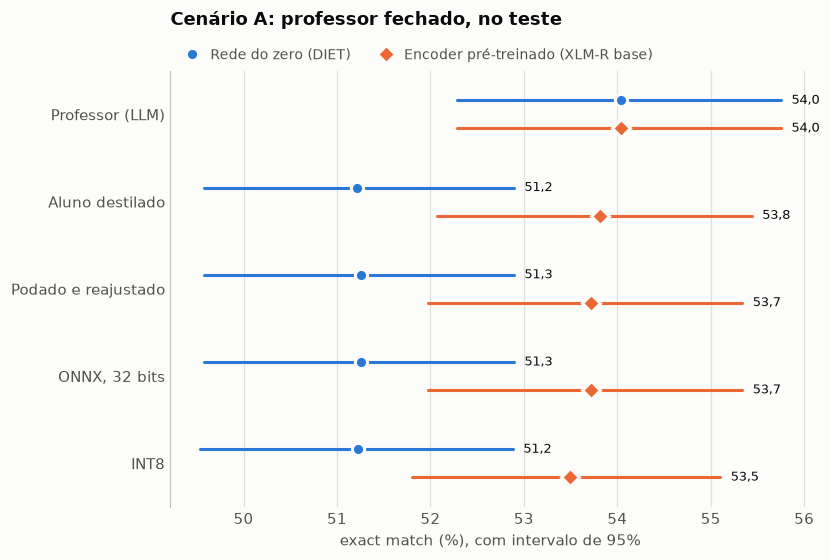

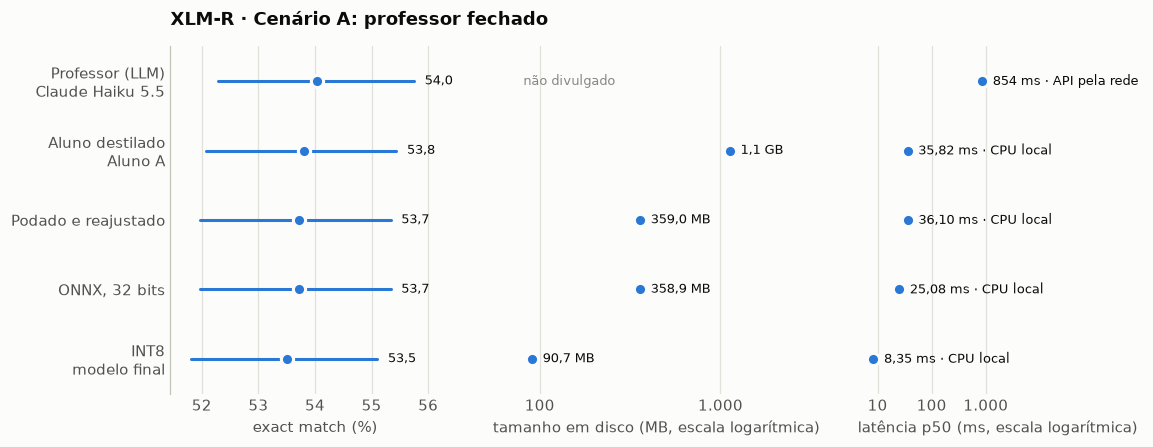

**Rede do zero (DIET)**

- **Destilação.** O aluno fica abaixo do professor em exact match: −2,8 (−4,3 a −1,5) no teste e −2,7 (−4,5 a −1,0) em `dev`. A consulta sai de 854 ms (API pela rede) para 1,11 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 19,9 MB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −9,8 (−11,0 a −8,7) em relação ao modelo sem poda; o reajuste muda +9,9 (+8,8 a +11,0) (Etapa 7). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: +0,04 (−0,76 a +0,89) no teste e −0,4 (−1,4 a +0,6) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,11 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,43 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,03 (−0,16 a +0,08) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,01 (−0,10 a +0,08) no teste, +0,00 (−0,08 a +0,08) em `dev`); F1 de entidades sem diferença distinguível (+0,06 (−0,03 a +0,16) no teste, −0,03 (−0,15 a +0,10) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,43 ms para 0,26 ms (1,6 vezes menos).

**Encoder pré-treinado (XLM-R base)**

- **Destilação.** O aluno fica sem diferença distinguível para o professor em exact match: −0,2 (−1,6 a +1,0) no teste e −0,4 (−2,0 a +1,4) em `dev`. A consulta sai de 854 ms (API pela rede) para 35,82 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 1,1 GB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,2 (−0,5 a +0,0) em relação ao modelo sem poda; o reajuste muda +0,1 (−0,3 a +0,6) (Etapa 10b). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: −0,09 (−0,63 a +0,44) no teste e −0,4 (−1,0 a +0,3) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (35,82 ms e 36,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 36,10 ms para 25,08 ms (1,4 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,22 (−0,64 a +0,21) (sem diferença distinguível); acurácia de intenção abaixo (−0,44 (−0,77 a −0,10) no teste, −0,41 (−0,79 a −0,03) em `dev`); F1 de entidades sem diferença distinguível (+0,03 (−0,36 a +0,44) no teste, +0,05 (−0,39 a +0,50) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 25,08 ms para 8,35 ms (3,0 vezes menos).

### Cenário B: professor aberto

,Do zero: exact match,Do zero: diferença para o anterior,Do zero: tamanho,Do zero: latência p50,XLM-R: exact match,XLM-R: diferença para o anterior,XLM-R: tamanho,XLM-R: latência p50
Degrau,,,,,,,,
Professor (LLM),"43,2 (41,5 a 45,0)",—,"16,4 GB",1.087 ms,"43,2 (41,5 a 45,0)",—,"16,4 GB",1.087 ms
Aluno destilado,"46,0 (44,2 a 47,6)","+2,7 (+1,2 a +4,3)","19,9 MB","1,11 ms","46,3 (44,6 a 48,0)","+3,0 (+1,7 a +4,3)","1,1 GB","37,58 ms"
Podado e reajustado,"46,2 (44,5 a 47,9)","+0,2 (−0,7 a +1,2)","8,06 MB","1,10 ms","45,2 (43,5 a 47,0)","−1,0 (−1,4 a −0,6)","359,0 MB","36,80 ms"
"ONNX, 32 bits","46,2 (44,5 a 47,9)","+0,00 (+0,00 a +0,00)","7,98 MB","0,42 ms","45,2 (43,5 a 47,0)","+0,00 (+0,00 a +0,00)","358,9 MB","24,33 ms"
INT8,"46,2 (44,5 a 47,9)","+0,01 (−0,15 a +0,16)","2,11 MB","0,26 ms","45,2 (43,5 a 46,9)","−0,04 (−0,50 a +0,39)","90,7 MB","7,94 ms"


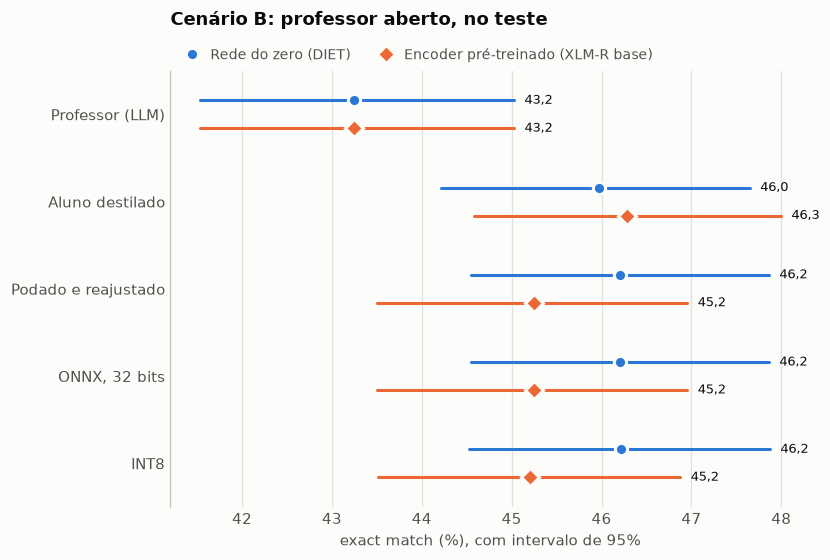

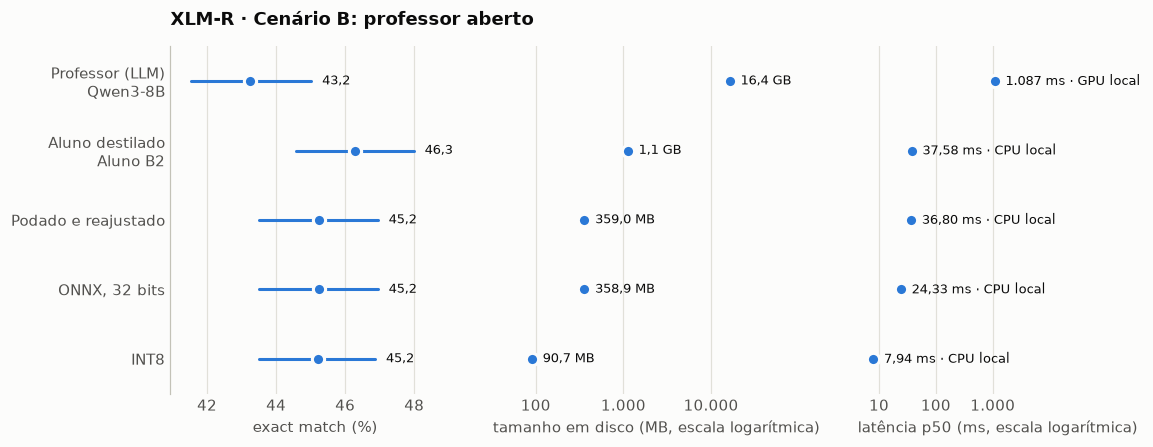

**Rede do zero (DIET)**

- **Destilação.** O aluno fica acima do professor em exact match: +2,7 (+1,2 a +4,3) no teste e +3,7 (+1,9 a +5,5) em `dev`. A consulta sai de 1.087 ms (GPU local) para 1,11 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 19,9 MB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −10,3 (−11,6 a −9,1) em relação ao modelo sem poda; o reajuste muda +10,5 (+9,5 a +11,6) (Etapa 7). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: +0,2 (−0,7 a +1,2) no teste e −0,03 (−1,13 a +1,05) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,11 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,42 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em +0,01 (−0,15 a +0,16) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,02 (−0,12 a +0,08) no teste, +0,08 (−0,05 a +0,21) em `dev`); F1 de entidades sem diferença distinguível (−0,05 (−0,20 a +0,09) no teste, −0,02 (−0,20 a +0,15) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,42 ms para 0,26 ms (1,6 vezes menos).

**Encoder pré-treinado (XLM-R base)**

- **Destilação.** O aluno fica acima do professor em exact match: +3,0 (+1,7 a +4,3) no teste e +4,1 (+2,5 a +5,7) em `dev`. A consulta sai de 1.087 ms (GPU local) para 37,58 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 1,1 GB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,1 (−0,4 a +0,2) em relação ao modelo sem poda; o reajuste muda −0,9 (−1,2 a −0,6) (Etapa 10b). Depois do reajuste, o modelo podado fica abaixo em relação ao modelo sem poda: −1,0 (−1,4 a −0,6) no teste e −0,4 (−0,9 a +0,0) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (37,58 ms e 36,80 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 36,80 ms para 24,33 ms (1,5 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,04 (−0,50 a +0,39) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,18 (−0,54 a +0,16) no teste, −0,30 (−0,71 a +0,13) em `dev`); F1 de entidades sem diferença distinguível (−0,22 (−0,68 a +0,23) no teste, −0,16 (−0,66 a +0,37) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 24,33 ms para 7,94 ms (3,1 vezes menos).

### Referência: teto (rótulos humanos)

,Do zero: exact match,Do zero: diferença para o anterior,Do zero: tamanho,Do zero: latência p50,XLM-R: exact match,XLM-R: diferença para o anterior,XLM-R: tamanho,XLM-R: latência p50
Degrau,,,,,,,,
Sem compressão,"62,5 (60,8 a 64,1)",—,"19,9 MB","1,10 ms","66,3 (64,7 a 67,9)",—,"1,1 GB","37,06 ms"
Podado e reajustado,"61,3 (59,6 a 62,9)","−1,2 (−2,1 a −0,3)","8,06 MB","1,10 ms","65,8 (64,2 a 67,4)","−0,4 (−0,9 a +0,1)","359,0 MB","37,54 ms"
"ONNX, 32 bits","61,3 (59,6 a 62,9)","+0,00 (+0,00 a +0,00)","7,98 MB","0,43 ms","65,8 (64,2 a 67,4)","+0,00 (+0,00 a +0,00)","358,9 MB","25,35 ms"
INT8,"61,3 (59,7 a 62,9)","−0,01 (−0,17 a +0,15)","2,11 MB","0,26 ms","65,7 (64,1 a 67,2)","−0,2 (−0,7 a +0,3)","90,7 MB","8,50 ms"


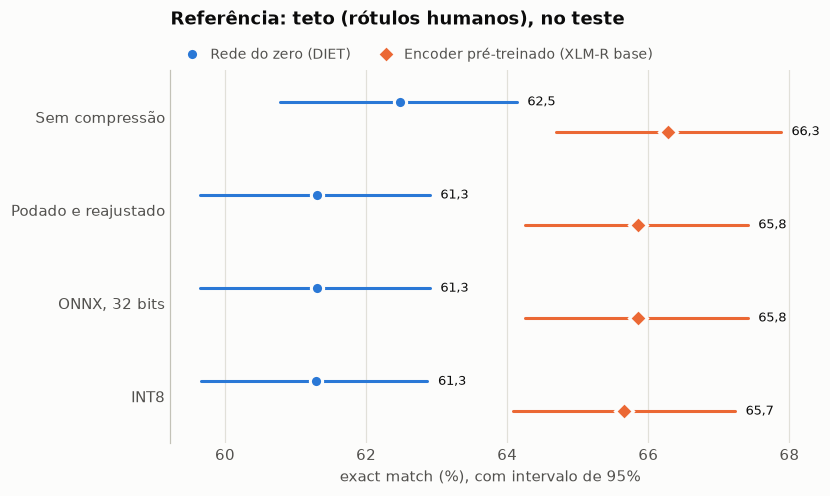

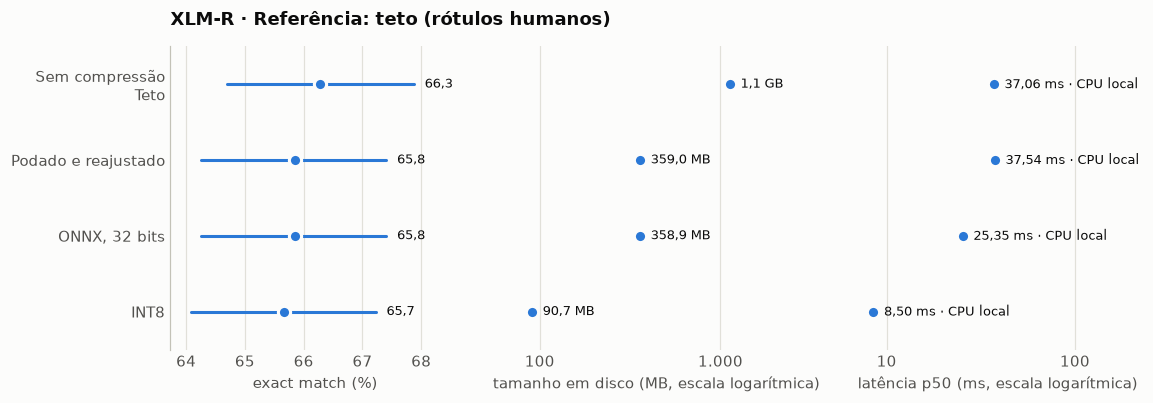

**Rede do zero (DIET)**

- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −14,1 (−15,3 a −12,7) em relação ao modelo sem poda; o reajuste muda +12,9 (+11,7 a +14,1) (Etapa 7). Depois do reajuste, o modelo podado fica abaixo em relação ao modelo sem poda: −1,2 (−2,1 a −0,3) no teste e −0,8 (−2,0 a +0,2) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,10 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,43 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,01 (−0,17 a +0,15) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,06 (−0,18 a +0,07) no teste, +0,08 (−0,03 a +0,20) em `dev`); F1 de entidades sem diferença distinguível (−0,05 (−0,17 a +0,09) no teste, −0,01 (−0,13 a +0,11) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,43 ms para 0,26 ms (1,6 vezes menos).

**Encoder pré-treinado (XLM-R base)**

- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,4 (−0,8 a −0,1) em relação ao modelo sem poda; o reajuste muda +0,0 (−0,3 a +0,4) (Etapa 10b). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: −0,4 (−0,9 a +0,1) no teste e −0,15 (−0,71 a +0,38) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (37,06 ms e 37,54 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 37,54 ms para 25,35 ms (1,5 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,19 (−0,71 a +0,33) (sem diferença distinguível); acurácia de intenção abaixo (−0,36 (−0,72 a −0,01) no teste, −0,46 (−0,95 a +0,00) em `dev`); F1 de entidades sem diferença distinguível (−0,31 (−0,80 a +0,12) no teste, −0,20 (−0,72 a +0,34) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 25,35 ms para 8,50 ms (3,0 vezes menos).

In [6]:
CENARIOS = {"A": "Cenário A: professor fechado", "B": "Cenário B: professor aberto", "teto": "Referência: teto (rótulos humanos)"}
ARQUIVO_DO_CENARIO = {"A": "cenario_a", "B": "cenario_b", "teto": "teto"}
D = etapa9.DEGRAUS
poda_gravada = {ZERO: pd.read_csv(ENTREGAS / "07_poda" / "comparacoes.csv"), XLMR: pd.read_csv(ENTREGAS / "10b_encoder_poda" / "comparacoes.csv")}
ETAPA_DA_PODA = {ZERO: "Etapa 7", XLMR: "Etapa 10b"}


def cadeia(caminho, cenario, particao="test"):
    return CAD[(CAD["cadeia"] == f"{caminho}/{cenario}") & (CAD["particao"] == particao)]


def casas_da(d, m):
    return 2 if abs(d[f"{m}_diferenca"]) < 0.0015 else 1


def tabela_da_cadeia(caminho, cenario, particao="test"):
    return pd.DataFrame([
        {
            "Degrau": d["degrau"], "Sistema": nome(d["chave"]), "Exact match": valor_com_intervalo(d, "exact_match"),
            **{f"{qualidade.NOMES[m]}: diferença para o degrau anterior": "—" if pd.isna(d["anterior"]) else com_intervalo(d, f"{m}_", casas_da(d, m)) for m in ("exact_match", "intent_acc", "slot_f1")},
            "Tamanho em disco": "não divulgado" if not T.loc[d["chave"], "divulgado"] else tamanho(d["bytes"]), "Latência p50": ms(d["latencia_p50_ms"]), "Onde": d["condicao_da_latencia"],
        }
        for _, d in cadeia(caminho, cenario, particao).iterrows()
    ])


def lado_a_lado(cenario, particao="test"):
    """Os dois caminhos na mesma tabela: em cada degrau, o exact match e a diferença para o degrau anterior de cada um."""
    z, x = cadeia(ZERO, cenario, particao).set_index("degrau"), cadeia(XLMR, cenario, particao).set_index("degrau")
    linhas = []
    for degrau in z.index:
        linha = {"Degrau": degrau}
        for rotulo, c in ((CAMINHOS[ZERO]["curto"], z), (CAMINHOS[XLMR]["curto"], x)):
            d = c.loc[degrau]
            linha.update({f"{rotulo}: exact match": valor_com_intervalo(d, "exact_match"), f"{rotulo}: diferença para o anterior": "—" if pd.isna(d["anterior"]) else com_intervalo(d, "exact_match_", casas_da(d, "exact_match")),
                          f"{rotulo}: tamanho": "não divulgado" if not T.loc[d["chave"], "divulgado"] else tamanho(d["bytes"]), f"{rotulo}: latência p50": ms(d["latencia_p50_ms"])})
        linhas.append(linha)
    return pd.DataFrame(linhas)


def figura_lado_a_lado(cenario):
    z, x = cadeia(ZERO, cenario), cadeia(XLMR, cenario)
    serie = lambda c: {d["degrau"]: trio(d, ("exact_match", "exact_match_ic_min", "exact_match_ic_max")) for _, d in c.iterrows()}
    return visual.pontos_com_intervalo({CAMINHOS[ZERO]["nome"]: serie(z), CAMINHOS[XLMR]["nome"]: serie(x)}, f"{CENARIOS[cenario]}, no teste", "exact match (%), com intervalo de 95%")


def figura_da_cadeia(caminho, cenario):
    """A cadeia de um caminho no formato da Etapa 9: exact match, tamanho e latência em cada degrau."""
    c = cadeia(caminho, cenario)
    com_nome = 2 if c["degrau"].iloc[0] == D["professor"] else 1
    degraus = [f"{d}\n{T.loc[k, 'curto']}" if i < com_nome else f"{d}\nmodelo final" if T.loc[k, "final"] else d for i, (d, k) in enumerate(zip(c["degrau"], c["chave"]))]
    megas = [None if pd.isna(b) else b / 1e6 for b in c["bytes"]]
    latencias = list(c["latencia_p50_ms"])
    return visual.degraus_em_paineis(
        degraus,
        [
            {"eixo_x": "exact match (%)", "valores": [trio(d, ("exact_match", "exact_match_ic_min", "exact_match_ic_max")) for _, d in c.iterrows()], "rotulos": [pts(v) for v in c["exact_match"]]},
            {"eixo_x": "tamanho em disco (MB, escala logarítmica)", "valores": megas, "rotulos": ["não divulgado" if v is None else tamanho(v * 1e6) for v in megas], "log": True},
            {"eixo_x": "latência p50 (ms, escala logarítmica)", "valores": latencias, "rotulos": [f"{ms(v)} · {onde}" for v, onde in zip(latencias, c["condicao_da_latencia"])], "log": True},
        ],
        f"{CAMINHOS[caminho]['curto']} · {CENARIOS[cenario]}",
    )


def leitura_da_cadeia(caminho, cenario):
    """A cadeia de um caminho em frases: o que cada passo fez com a qualidade, o tamanho e a latência."""
    c = cadeia(caminho, cenario).set_index("degrau")
    em_dev = cadeia(caminho, cenario, "dev").set_index("degrau")
    frases = []
    if D["professor"] in c.index:
        d = c.loc[D["destilado"]]
        frases.append(f"**Destilação.** O aluno fica {posicao(d['exact_match_dif_ic_min'], d['exact_match_dif_ic_max'])}{' do professor' if posicao(d['exact_match_dif_ic_min'], d['exact_match_dif_ic_max']) != 'sem diferença distinguível' else ' para o professor'} em exact match: "
                      f"{com_intervalo(d, 'exact_match_')} no teste e {com_intervalo(em_dev.loc[D['destilado']], 'exact_match_')} em `dev`. A consulta sai de {ms(c.loc[D['professor'], 'latencia_p50_ms'])} ({c.loc[D['professor'], 'condicao_da_latencia']}) "
                      f"para {ms(d['latencia_p50_ms'])} ({d['condicao_da_latencia']}, 1 thread), e o sistema passa a ser um arquivo de {tamanho(d['bytes'])}.")
    d, antes = c.loc[D["podado"]], c.iloc[c.index.get_loc(D["podado"]) - 1]
    filtro = {k: v for k, v in fichas[d["chave"]]["degrau_gravado"][1].items() if k in ("modelo", "variante")}
    da_poda = lambda comparacao: etapa9.linha_gravada(poda_gravada[caminho], **filtro, comparacao=comparacao, particao="test", metrica="exact_match")
    sem_reajuste, recupera = da_poda("antes − sem poda"), da_poda("depois − antes")
    frases.append(f"**Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica {com_intervalo(sem_reajuste)} em relação ao modelo sem poda; o reajuste muda {com_intervalo(recupera)} ({ETAPA_DA_PODA[caminho]}). "
                  f"Depois do reajuste, o modelo podado fica {posicao(d['exact_match_dif_ic_min'], d['exact_match_dif_ic_max'])} em relação ao modelo sem poda: {com_intervalo(d, 'exact_match_', casas_da(d, 'exact_match'))} no teste e {com_intervalo(em_dev.loc[D['podado']], 'exact_match_', casas_da(em_dev.loc[D['podado']], 'exact_match'))} em `dev`. "
                  f"O arquivo vai de {tamanho(antes['bytes'])} para {tamanho(d['bytes'])} ({vezes(antes['bytes'], d['bytes'])} vezes menos); "
                  f"a latência {'não muda' if abs(d['latencia_p50_ms'] / antes['latencia_p50_ms'] - 1) <= FOLGA else 'muda'} ({ms(antes['latencia_p50_ms'])} e {ms(d['latencia_p50_ms'])}).")
    o, i = c.loc[D["onnx"]], c.loc[D["int8"]]
    frases.append(f"**Exportação.** Sair do PyTorch não muda nenhuma resposta ({com_intervalo(o, 'exact_match_', 2)}) e leva a consulta de {ms(d['latencia_p50_ms'])} para {ms(o['latencia_p50_ms'])} ({vezes(d['latencia_p50_ms'], o['latencia_p50_ms'])} vezes menos).")
    outras = [f"{metrica_na_frase(m)} {posicao(i[f'{m}_dif_ic_min'], i[f'{m}_dif_ic_max'])} ({com_intervalo(i, f'{m}_', 2)} no teste, {com_intervalo(em_dev.loc[D['int8']], f'{m}_', 2)} em `dev`)" for m in ("intent_acc", "slot_f1")]
    frases.append(f"**8 bits.** Passar para INT8 muda o exact match em {com_intervalo(i, 'exact_match_', 2)} ({posicao(i['exact_match_dif_ic_min'], i['exact_match_dif_ic_max'])}); {'; '.join(outras)}. "
                  f"O arquivo vai de {tamanho(o['bytes'])} para {tamanho(i['bytes'])} ({vezes(o['bytes'], i['bytes'])} vezes menos) e a consulta, de {ms(o['latencia_p50_ms'])} para {ms(i['latencia_p50_ms'])} ({vezes(o['latencia_p50_ms'], i['latencia_p50_ms'])} vezes menos).")
    return frases


leituras_das_cadeias, FIGURAS_DAS_CADEIAS = {}, []
for cenario in CENARIOS:
    display(Markdown(f"### {CENARIOS[cenario]}"))
    display(lado_a_lado(cenario).set_index("Degrau"))
    fig, _ = figura_lado_a_lado(cenario)
    visual.salvar(fig, PASTA, f"cadeias_lado_a_lado_{ARQUIVO_DO_CENARIO[cenario]}")
    plt.show()
    fig, _ = figura_da_cadeia(XLMR, cenario)
    visual.salvar(fig, PASTA, f"cadeia_xlmr_{ARQUIVO_DO_CENARIO[cenario]}")
    plt.show()
    FIGURAS_DAS_CADEIAS += [f"cadeias_lado_a_lado_{ARQUIVO_DO_CENARIO[cenario]}", f"cadeia_xlmr_{ARQUIVO_DO_CENARIO[cenario]}"]
    for caminho in (ZERO, XLMR):
        leituras_das_cadeias[(caminho, cenario)] = leitura_da_cadeia(caminho, cenario)
        display(Markdown(f"**{CAMINHOS[caminho]['nome']}**\n\n" + "\n".join(f"- {f}" for f in leituras_das_cadeias[(caminho, cenario)])))

In [7]:
passos = CAD[CAD["anterior"].notna()]
NOME_DA_CADEIA = {"A": "cenário A", "B": "cenário B", "teto": "teto"}


def distinguiveis_da(caminho, particao):
    """Os (cenário, degrau, métrica) em que um degrau do caminho se distingue de zero."""
    c = passos[(passos["cadeia"].str.startswith(caminho + "/")) & (passos["particao"] == particao)]
    return [(d["cadeia"].split("/")[1], d["degrau"], m) for _, d in c.iterrows() for m in TRES if d[f"{m}_distinguivel"] == True]   # noqa: E712


def frase_dos_degraus(caminho, particao="test"):
    achados = distinguiveis_da(caminho, particao)
    linha = lambda cen, g: passos[(passos["cadeia"] == f"{caminho}/{cen}") & (passos["degrau"] == g) & (passos["particao"] == particao)].iloc[0]
    return "; ".join(f"{NOME_DA_CADEIA[cen]}, {minusculo(g)}, {metrica_na_frase(m)} ({com_intervalo(linha(cen, g), m + '_', casas_da(linha(cen, g), m))})" for cen, g, m in achados) or "nenhuma"


total_de_degraus = int((passos["particao"] == "test").sum() / len(CAMINHOS))
compressao_x = [(cen, g, m) for cen, g, m in distinguiveis_da(XLMR, "test") if g != D["destilado"]]
compressao_z = [(cen, g, m) for cen, g, m in distinguiveis_da(ZERO, "test") if g != D["destilado"] and cen != "teto"]
nas_duas = lambda caminho: sorted(set(distinguiveis_da(caminho, "test")) & set(distinguiveis_da(caminho, "dev")))
leitura_das_cadeias = [
    f"**{CAMINHOS[ZERO]['nome']}.** De {total_de_degraus} degraus × {len(TRES)} métricas, {len(distinguiveis_da(ZERO, 'test'))} diferenças se distinguem de zero no teste: {frase_dos_degraus(ZERO)}. "
    + ("Nos dois cenários, a única mudança de qualidade que se distingue de zero é a da destilação; nenhum degrau de compressão se distingue (é a leitura da Etapa 9)." if not compressao_z else "Há degraus de compressão que se distinguem nos cenários."),
    f"**{CAMINHOS[XLMR]['nome']}.** De {total_de_degraus} degraus × {len(TRES)} métricas, {len(distinguiveis_da(XLMR, 'test'))} se distinguem de zero no teste: {frase_dos_degraus(XLMR)}. "
    + (f"Aqui a compressão não é neutra em todos os degraus: {len(compressao_x)} das diferenças distinguíveis estão em degraus de compressão." if compressao_x else "Nenhum degrau de compressão se distingue."),
    f"**`dev` e teste.** As diferenças que se distinguem de zero nas duas partições ao mesmo tempo são {len(nas_duas(ZERO))} na rede do zero e {len(nas_duas(XLMR))} no XLM-R"
    + (f" (no XLM-R: {'; '.join(f'{NOME_DA_CADEIA[cen]}, {minusculo(g)}, {metrica_na_frase(m)}' for cen, g, m in nas_duas(XLMR))})" if nas_duas(XLMR) else "") + ". "
    f"São {2 * total_de_degraus * len(TRES)} intervalos por partição, sem correção: cerca de {num(0.05 * 2 * total_de_degraus * len(TRES), 1)} sairia do zero só por acaso.",
    "**O custo.** Nos dois caminhos a poda diminui o arquivo e não muda a latência, a exportação diminui a latência, e os 8 bits diminuem os dois. O que muda é a proporção: na rede do zero a exportação rende mais que os 8 bits; no XLM-R, o contrário (Etapa 10c).",
]
display(Markdown("**Leitura das seis cadeias.**\n\n" + "\n".join(f"- {l}" for l in leitura_das_cadeias)))

**Leitura das seis cadeias.**

- **Rede do zero (DIET).** De 11 degraus × 3 métricas, 7 diferenças se distinguem de zero no teste: cenário A, aluno destilado, acurácia de intenção (−2,7 (−3,9 a −1,7)); cenário A, aluno destilado, F1 de entidades (−1,2 (−2,5 a −0,0)); cenário A, aluno destilado, exact match (−2,8 (−4,3 a −1,5)); cenário B, aluno destilado, F1 de entidades (+2,3 (+0,8 a +3,9)); cenário B, aluno destilado, exact match (+2,7 (+1,2 a +4,3)); teto, podado e reajustado, acurácia de intenção (−1,0 (−1,8 a −0,2)); teto, podado e reajustado, exact match (−1,2 (−2,1 a −0,3)). Nos dois cenários, a única mudança de qualidade que se distingue de zero é a da destilação; nenhum degrau de compressão se distingue (é a leitura da Etapa 9).
- **Encoder pré-treinado (XLM-R base).** De 11 degraus × 3 métricas, 9 se distinguem de zero no teste: cenário A, INT8, acurácia de intenção (−0,4 (−0,8 a −0,1)); cenário B, aluno destilado, acurácia de intenção (+1,3 (+0,2 a +2,4)); cenário B, aluno destilado, F1 de entidades (+3,1 (+1,9 a +4,5)); cenário B, aluno destilado, exact match (+3,0 (+1,7 a +4,3)); cenário B, podado e reajustado, acurácia de intenção (−0,5 (−0,9 a −0,2)); cenário B, podado e reajustado, F1 de entidades (−0,9 (−1,4 a −0,5)); cenário B, podado e reajustado, exact match (−1,0 (−1,4 a −0,6)); teto, podado e reajustado, F1 de entidades (−0,6 (−1,1 a −0,2)); teto, INT8, acurácia de intenção (−0,4 (−0,7 a −0,0)). Aqui a compressão não é neutra em todos os degraus: 6 das diferenças distinguíveis estão em degraus de compressão.
- **`dev` e teste.** As diferenças que se distinguem de zero nas duas partições ao mesmo tempo são 5 na rede do zero e 5 no XLM-R (no XLM-R: cenário A, INT8, acurácia de intenção; cenário B, aluno destilado, exact match; cenário B, aluno destilado, acurácia de intenção; cenário B, aluno destilado, F1 de entidades; cenário B, podado e reajustado, acurácia de intenção). São 66 intervalos por partição, sem correção: cerca de 3,3 sairia do zero só por acaso.
- **O custo.** Nos dois caminhos a poda diminui o arquivo e não muda a latência, a exportação diminui a latência, e os 8 bits diminuem os dois. O que muda é a proporção: na rede do zero a exportação rende mais que os 8 bits; no XLM-R, o contrário (Etapa 10c).

## 6. Os dois caminhos no mesmo ponto

A pergunta da etapa, ponto por ponto: o mesmo modelo, no mesmo ponto da cadeia, XLM-R menos rede do zero. A última linha de cada aluno é a forma final de 8 bits; a do aluno A é a comparação entre os dois modelos finais.

Uma ressalva vale para todas as linhas: os dois caminhos não diferem só no pré-treino. Mudam juntos a arquitetura, o tamanho, a receita de treino, a cabeça de entidades (com CRF na rede do zero, sem no XLM-R) e, nos pontos podados, a própria poda. A comparação mede o pacote.

**Em teste** (diferença pareada, em pontos percentuais, intervalo de 95%)

,Acurácia de intenção,F1 de entidades,Exact match,Exact match: do zero → XLM-R
Ponto (XLM-R − rede do zero),,,,
Teto,"+2,5 (+1,7 a +3,4)","+1,9 (+0,8 a +2,9)","+3,8 (+2,7 a +5,0)","62,5 → 66,3"
"Teto, podado","+3,3 (+2,4 a +4,1)","+1,4 (+0,4 a +2,4)","+4,6 (+3,4 a +5,7)","61,3 → 65,8"
"Teto, INT8","+2,9 (+2,1 a +3,8)","+1,1 (+0,0 a +2,2)","+4,4 (+3,2 a +5,5)","61,3 → 65,7"
Piso,"+14,6 (+13,3 a +15,9)","+12,0 (+10,6 a +13,5)","+11,7 (+10,6 a +13,0)","20,9 → 32,6"
Aluno A,"+1,9 (+1,1 a +2,8)","+0,7 (−0,3 a +1,7)","+2,6 (+1,6 a +3,7)","51,2 → 53,8"
"Aluno A, podado","+2,7 (+1,8 a +3,5)","+0,3 (−0,7 a +1,2)","+2,5 (+1,4 a +3,5)","51,3 → 53,7"
"Aluno A, INT8 (os dois modelos finais)","+2,2 (+1,4 a +3,1)","+0,3 (−0,6 a +1,1)","+2,3 (+1,3 a +3,3)","51,2 → 53,5"
Aluno B1,"+2,4 (+1,5 a +3,4)","+1,4 (+0,3 a +2,4)","+2,1 (+1,0 a +3,1)","43,6 → 45,7"
Aluno B2,"+1,1 (+0,2 a +2,1)","+0,8 (−0,3 a +1,9)","+0,3 (−0,9 a +1,4)","46,0 → 46,3"


**Em `dev`** (diferença pareada, em pontos percentuais, intervalo de 95%)

,Acurácia de intenção,F1 de entidades,Exact match,Exact match: do zero → XLM-R
Ponto (XLM-R − rede do zero),,,,
Teto,"+3,0 (+1,9 a +4,1)","+1,5 (+0,2 a +2,7)","+4,2 (+2,8 a +5,6)","62,6 → 66,8"
"Teto, podado","+3,4 (+2,4 a +4,5)","+1,6 (+0,5 a +2,8)","+4,9 (+3,6 a +6,2)","61,8 → 66,7"
"Teto, INT8","+2,9 (+1,9 a +3,9)","+1,4 (+0,3 a +2,6)","+4,2 (+2,9 a +5,5)","61,8 → 66,0"
Piso,"+14,5 (+12,9 a +16,1)","+10,8 (+9,1 a +12,5)","+10,9 (+9,4 a +12,3)","22,1 → 33,0"
Aluno A,"+1,5 (+0,5 a +2,6)","+0,6 (−0,5 a +1,7)","+2,3 (+1,1 a +3,7)","52,0 → 54,4"
"Aluno A, podado","+1,8 (+0,9 a +2,7)","+0,8 (−0,1 a +1,9)","+2,4 (+1,2 a +3,6)","51,6 → 54,0"
"Aluno A, INT8 (os dois modelos finais)","+1,4 (+0,4 a +2,4)","+0,9 (−0,1 a +2,0)","+2,3 (+1,2 a +3,6)","51,7 → 54,0"
Aluno B1,"+1,8 (+0,7 a +3,0)","+1,6 (+0,3 a +2,8)","+1,6 (+0,2 a +2,9)","45,2 → 46,7"
Aluno B2,"+1,6 (+0,4 a +2,7)","+0,9 (−0,4 a +2,2)","+0,4 (−1,1 a +1,8)","46,9 → 47,3"


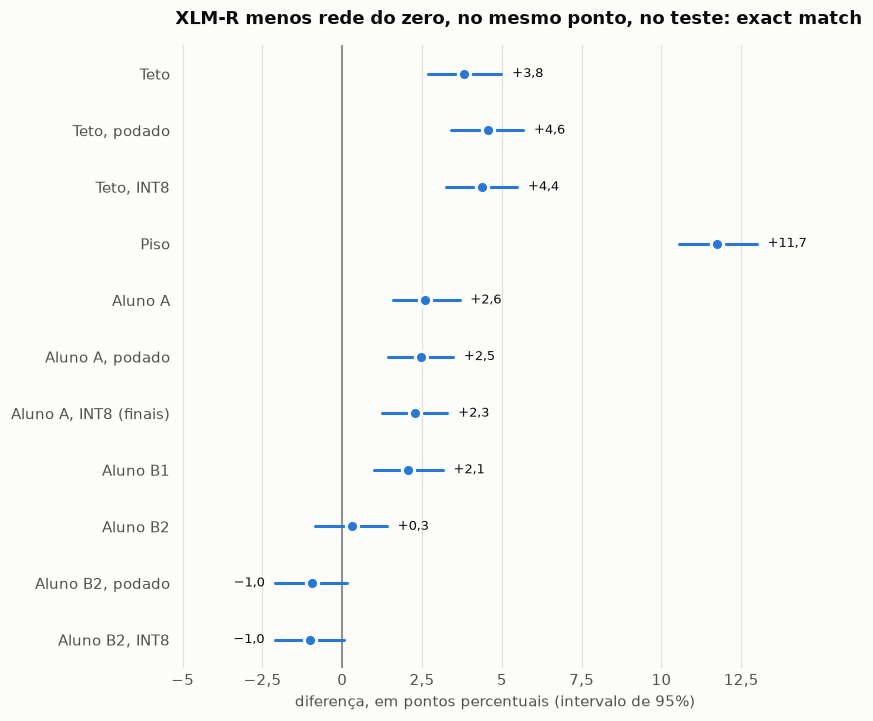

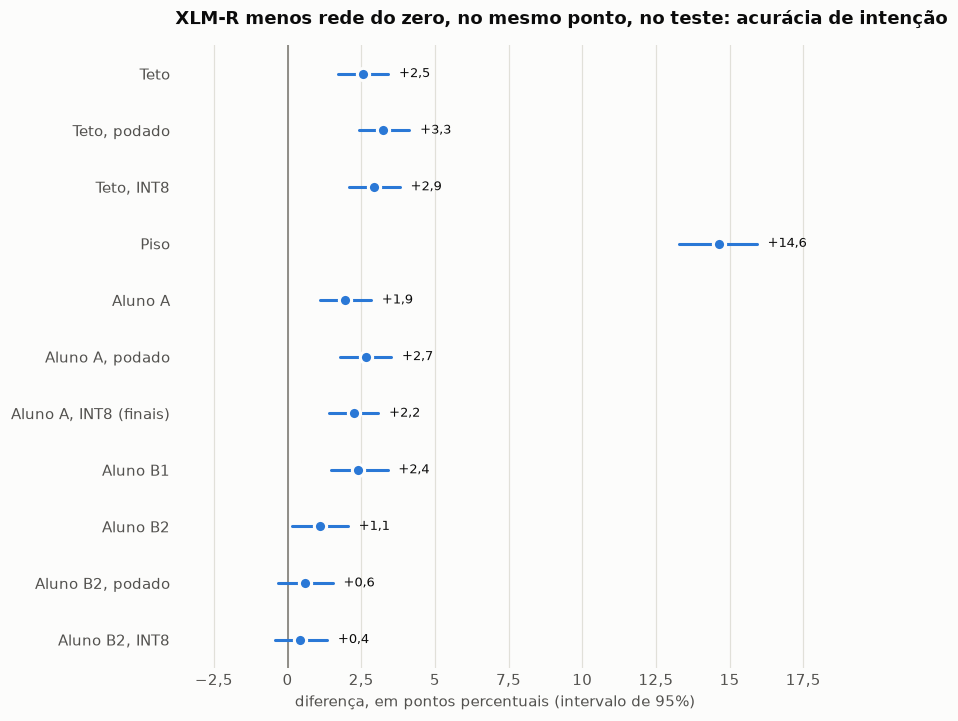

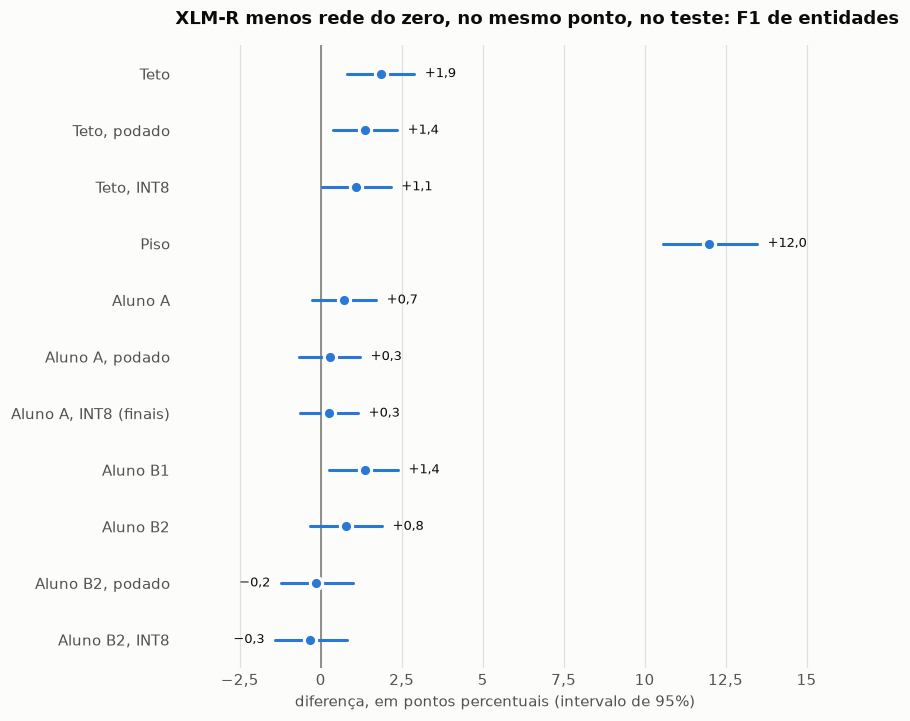

In [8]:
entre = [c for c in regras["comparacoes"] if "entre_caminhos" in c["familias"]]
ORDEM_DOS_MODELOS = ["teto", "piso", "aluno_a", "aluno_b1", "aluno_b2"]
entre = sorted(entre, key=lambda c: (ORDEM_DOS_MODELOS.index(T.loc[c["b"], "modelo"]), list(etapa10d.PONTOS).index(T.loc[c["b"], "ponto"])))
rotulo_do_ponto = lambda c: T.loc[c["a"], "curto"] + (" (os dois modelos finais)" if c["b"] == FX and c["a"] == FZ else "")


def tabela_entre_caminhos(particao):
    return pd.DataFrame([
        {"Ponto (XLM-R − rede do zero)": rotulo_do_ponto(c), **{qualidade.NOMES[m]: com_intervalo(comp(c["b"], c["a"], m, particao)) for m in TRES},
         "Exact match: do zero → XLM-R": f"{pts(comp(c['b'], c['a'], 'exact_match', particao)['valor_a'])} → {pts(comp(c['b'], c['a'], 'exact_match', particao)['valor_b'])}"}
        for c in entre
    ])


tabelas_entre = {p: tabela_entre_caminhos(p) for p in ("test", "dev")}
for p in ("test", "dev"):
    display(Markdown(f"**Em {'`dev`' if p == 'dev' else 'teste'}** (diferença pareada, em pontos percentuais, intervalo de 95%)"))
    display(tabelas_entre[p].set_index("Ponto (XLM-R − rede do zero)"))

FIGURAS_ENTRE = {"exact_match": "entre_caminhos_exact_match", "intent_acc": "entre_caminhos_intencao", "slot_f1": "entre_caminhos_entidades"}
for metrica, arquivo in FIGURAS_ENTRE.items():
    fig, ax = diferencas({rotulo_do_ponto(c).replace(" (os dois modelos finais)", " (finais)"): trio(comp(c["b"], c["a"], metrica)) for c in entre},
                         f"XLM-R menos rede do zero, no mesmo ponto, no teste: {metrica_na_frase(metrica)}", "diferença, em pontos percentuais (intervalo de 95%)")
    visual.salvar(fig, PASTA, arquivo)
    plt.show()

In [9]:
def conta(particao, metrica, sinal):
    linhas = [comp(c["b"], c["a"], metrica, particao) for c in entre]
    return sum((l["ic_min"] > 0) if sinal > 0 else (l["ic_max"] < 0) for l in linhas)


def discordam(lista_de_pares, metricas=TRES):
    """As comparações em que dev e teste não dizem o mesmo (acima, abaixo ou sem diferença distinguível)."""
    return [(b, a, m) for b, a in lista_de_pares for m in metricas if posicao(comp(b, a, m, "dev")["ic_min"], comp(b, a, m, "dev")["ic_max"]) != posicao(comp(b, a, m, "test")["ic_min"], comp(b, a, m, "test")["ic_max"])]


pares_entre = [(c["b"], c["a"]) for c in entre]
discordam_entre = discordam(pares_entre)
sem_distincao_em = [rotulo_do_ponto(c) for c in entre if not comp(c["b"], c["a"])["distinguivel"]]
do_aluno = lambda modelo: [c for c in entre if T.loc[c["b"], "modelo"] == modelo]
trajeto = lambda modelo: " → ".join(f"{dif(comp(c['b'], c['a'])['diferenca'])} ({minusculo(etapa10d.PONTOS[T.loc[c['b'], 'ponto']])})" for c in do_aluno(modelo))
leitura_entre = [
    f"**Os dois modelos finais.** No teste, o final do XLM-R fica {frase(FX, FZ)} em relação ao final da rede do zero. Em `dev`: {frase(FX, FZ, 'dev')}.",
    f"**Em todos os pontos.** Em exact match, no teste, o XLM-R fica acima da rede do zero em {conta('test', 'exact_match', +1)} dos {len(entre)} pontos e abaixo em {conta('test', 'exact_match', -1)}"
    + (f"; não se distingue em: {lista(sem_distincao_em)}" if sem_distincao_em else "") + f". Em acurácia de intenção, acima em {conta('test', 'intent_acc', +1)} e abaixo em {conta('test', 'intent_acc', -1)}; em F1 de entidades, acima em {conta('test', 'slot_f1', +1)} e abaixo em {conta('test', 'slot_f1', -1)}.",
    f"**Ao longo da cadeia** (exact match, teste). Aluno A: {trajeto('aluno_a')}. Aluno B2: {trajeto('aluno_b2')}. Teto: {trajeto('teto')}. "
    + " ".join(f"No {minusculo(etapa10d.NOME_DO_MODELO[m])}, a diferença se distingue de zero em {sum(bool(comp(c['b'], c['a'])['distinguivel']) for c in do_aluno(m))} dos {len(do_aluno(m))} pontos." for m in ("aluno_a", "aluno_b2", "teto"))
    + " Onde há vantagem do XLM-R, ela já está no modelo sem poda e chega até o INT8; onde não há no modelo sem poda (aluno B2), a compressão não cria.",
    f"**`dev` e teste.** Das {len(entre) * len(TRES)} comparações (ponto × métrica), `dev` e teste dizem o mesmo em {len(entre) * len(TRES) - len(discordam_entre)}"
    + (f"; discordam em: {'; '.join(f'{T.loc[a, chr(99) + chr(117) + chr(114) + chr(116) + chr(111)]}, {metrica_na_frase(m)} ({com_intervalo(comp(b, a, m, chr(100) + chr(101) + chr(118)))} em dev e {com_intervalo(comp(b, a, m))} no teste)' for b, a, m in discordam_entre)}" if discordam_entre else "") + ".",
    f"São {len(entre) * len(TRES)} intervalos por partição, sem correção: cerca de {num(0.05 * len(entre) * len(TRES), 1)} sairia do zero só por acaso. As primárias são as três do modelo final.",
]
display(Markdown("**Leitura.**\n\n" + "\n".join(f"- {l}" for l in leitura_entre)))

**Leitura.**

- **Os dois modelos finais.** No teste, o final do XLM-R fica acima em acurácia de intenção (+2,2 (+1,4 a +3,1)); sem diferença distinguível em F1 de entidades (+0,3 (−0,6 a +1,1)); acima em exact match (+2,3 (+1,3 a +3,3)) em relação ao final da rede do zero. Em `dev`: acima em acurácia de intenção (+1,4 (+0,4 a +2,4)); sem diferença distinguível em F1 de entidades (+0,9 (−0,1 a +2,0)); acima em exact match (+2,3 (+1,2 a +3,6)).
- **Em todos os pontos.** Em exact match, no teste, o XLM-R fica acima da rede do zero em 8 dos 11 pontos e abaixo em 0; não se distingue em: Aluno B2; Aluno B2, podado; Aluno B2, INT8. Em acurácia de intenção, acima em 9 e abaixo em 0; em F1 de entidades, acima em 5 e abaixo em 0.
- **Ao longo da cadeia** (exact match, teste). Aluno A: +2,6 (aluno destilado) → +2,5 (podado e reajustado) → +2,3 (INT8). Aluno B2: +0,3 (aluno destilado) → −1,0 (podado e reajustado) → −1,0 (INT8). Teto: +3,8 (sem compressão) → +4,6 (podado e reajustado) → +4,4 (INT8). No aluno A, a diferença se distingue de zero em 3 dos 3 pontos. No aluno B2, a diferença se distingue de zero em 0 dos 3 pontos. No teto, a diferença se distingue de zero em 3 dos 3 pontos. Onde há vantagem do XLM-R, ela já está no modelo sem poda e chega até o INT8; onde não há no modelo sem poda (aluno B2), a compressão não cria.
- **`dev` e teste.** Das 33 comparações (ponto × métrica), `dev` e teste dizem o mesmo em 33.
- São 33 intervalos por partição, sem correção: cerca de 1,7 sairia do zero só por acaso. As primárias são as três do modelo final.

## 7. Cada aluno contra o seu professor, e de ponta a ponta

Primeiro, cada aluno menos a LLM que rotulou o treino dele, nos dois caminhos: como saiu da destilação e na forma final de 8 bits. Depois, as dez comparações de ponta a ponta da Etapa 9, repetidas com os sistemas do XLM-R. Por fim, a poda vista dentro dos 8 bits: o modelo podado em INT8 menos o mesmo modelo em INT8 sem poda.

**Aluno menos professor, em teste**

,Acurácia de intenção,F1 de entidades,Exact match
Aluno − professor,,,
Do zero · Aluno A − Claude Haiku 5.5,"−2,7 (−3,9 a −1,7)","−1,2 (−2,5 a −0,0)","−2,8 (−4,3 a −1,5)"
Do zero · Aluno B1 − Qwen3-8B,"−1,3 (−2,5 a −0,1)","+1,4 (+0,1 a +2,9)","+0,4 (−1,0 a +1,7)"
Do zero · Aluno B2 − Qwen3-8B,"+0,2 (−1,0 a +1,3)","+2,3 (+0,8 a +3,9)","+2,7 (+1,2 a +4,3)"
"Do zero · Aluno A, INT8 − Claude Haiku 5.5","−3,3 (−4,4 a −2,2)","−1,2 (−2,4 a +0,0)","−2,8 (−4,3 a −1,5)"
"Do zero · Aluno B2, INT8 − Qwen3-8B","+0,2 (−1,0 a +1,3)","+2,3 (+0,8 a +3,7)","+3,0 (+1,5 a +4,4)"
XLM-R · Aluno A − Claude Haiku 5.5,"−0,8 (−1,8 a +0,2)","−0,5 (−1,7 a +0,7)","−0,2 (−1,6 a +1,0)"
XLM-R · Aluno B1 − Qwen3-8B,"+1,1 (−0,0 a +2,2)","+2,8 (+1,5 a +4,2)","+2,5 (+1,1 a +3,8)"
XLM-R · Aluno B2 − Qwen3-8B,"+1,3 (+0,2 a +2,4)","+3,1 (+1,9 a +4,5)","+3,0 (+1,7 a +4,3)"
"XLM-R · Aluno A, INT8 − Claude Haiku 5.5","−1,0 (−2,0 a −0,1)","−0,9 (−2,1 a +0,2)","−0,5 (−1,9 a +0,7)"


**Aluno menos professor, em `dev`**

,Acurácia de intenção,F1 de entidades,Exact match
Aluno − professor,,,
Do zero · Aluno A − Claude Haiku 5.5,"−2,5 (−3,8 a −1,3)","−1,5 (−3,0 a −0,1)","−2,7 (−4,5 a −1,0)"
Do zero · Aluno B1 − Qwen3-8B,"−0,2 (−1,7 a +1,2)","+2,0 (+0,4 a +3,6)","+2,0 (+0,3 a +3,7)"
Do zero · Aluno B2 − Qwen3-8B,"+0,9 (−0,6 a +2,3)","+2,5 (+0,9 a +4,2)","+3,7 (+1,9 a +5,5)"
"Do zero · Aluno A, INT8 − Claude Haiku 5.5","−2,7 (−3,9 a −1,4)","−1,6 (−3,1 a −0,2)","−3,0 (−4,8 a −1,3)"
"Do zero · Aluno B2, INT8 − Qwen3-8B","+1,4 (+0,0 a +2,8)","+2,6 (+0,9 a +4,3)","+3,8 (+2,0 a +5,6)"
XLM-R · Aluno A − Claude Haiku 5.5,"−1,0 (−2,2 a +0,1)","−0,9 (−2,3 a +0,4)","−0,4 (−2,0 a +1,4)"
XLM-R · Aluno B1 − Qwen3-8B,"+1,6 (+0,3 a +2,9)","+3,6 (+2,1 a +5,1)","+3,5 (+1,9 a +5,1)"
XLM-R · Aluno B2 − Qwen3-8B,"+2,4 (+1,1 a +3,7)","+3,4 (+1,9 a +4,9)","+4,1 (+2,5 a +5,7)"
"XLM-R · Aluno A, INT8 − Claude Haiku 5.5","−1,3 (−2,4 a −0,3)","−0,7 (−2,0 a +0,6)","−0,7 (−2,3 a +0,9)"


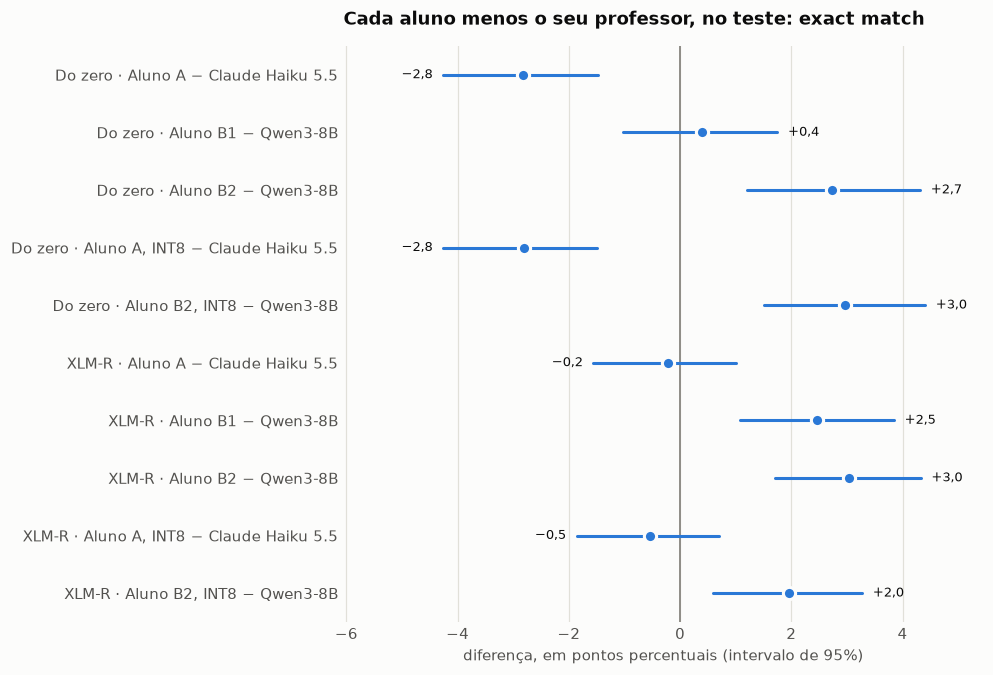

**De ponta a ponta, no teste**

,Do zero: exact match,XLM-R: exact match,Do zero: acurácia de intenção,XLM-R: acurácia de intenção,Do zero: F1 de entidades,XLM-R: F1 de entidades
"Comparação (B − A), em cada caminho",,,,,,
a. Final − professor fechado,"−2,8 (−4,3 a −1,5)","−0,5 (−1,9 a +0,7)","−3,3 (−4,4 a −2,2)","−1,0 (−2,0 a −0,1)","−1,2 (−2,4 a +0,0)","−0,9 (−2,1 a +0,2)"
b. Final − aluno A sem compressão,"+0,0 (−0,8 a +0,8)","−0,3 (−0,9 a +0,3)","−0,5 (−1,2 a +0,2)","−0,2 (−0,7 a +0,3)","+0,1 (−0,6 a +0,7)","−0,4 (−1,0 a +0,1)"
c. Final − teto do caminho,"−11,3 (−12,8 a −9,8)","−12,8 (−14,2 a −11,4)","−4,2 (−5,3 a −3,2)","−4,5 (−5,5 a −3,6)","−8,8 (−10,1 a −7,4)","−10,4 (−11,7 a −9,1)"
d. Teto comprimido − teto,"−1,2 (−2,2 a −0,3)","−0,6 (−1,3 a −0,0)","−1,0 (−1,8 a −0,3)","−0,6 (−1,1 a −0,2)","−0,2 (−0,9 a +0,6)","−0,9 (−1,5 a −0,4)"
e1. Final do cenário B − professor aberto,"+3,0 (+1,5 a +4,4)","+2,0 (+0,6 a +3,3)","+0,2 (−1,0 a +1,3)","+0,6 (−0,4 a +1,7)","+2,3 (+0,8 a +3,7)","+2,0 (+0,7 a +3,2)"
e2. Final do cenário B − aluno B2 sem compressão,"+0,2 (−0,7 a +1,2)","−1,1 (−1,6 a −0,5)","−0,0 (−0,8 a +0,8)","−0,7 (−1,1 a −0,2)","−0,0 (−1,0 a +0,9)","−1,2 (−1,7 a −0,6)"
f. Final do cenário A − final do cenário B,"+5,0 (+3,8 a +6,3)","+8,3 (+7,0 a +9,6)","+2,4 (+1,4 a +3,3)","+4,2 (+3,3 a +5,1)","+6,9 (+5,8 a +8,1)","+7,5 (+6,3 a +8,7)"
"g1. Final − linha de base, 299 rótulos","+31,8 (+29,9 a +33,5)","+34,1 (+32,1 a +35,8)","+32,4 (+30,6 a +34,2)","+34,6 (+32,7 a +36,5)","+29,3 (+27,4 a +31,2)","+29,6 (+27,6 a +31,5)"
"g2. Final − linha de base, 11.514 rótulos","+6,0 (+4,1 a +7,8)","+8,3 (+6,3 a +10,1)","−4,4 (−5,5 a −3,3)","−2,1 (−3,4 a −0,9)","+17,1 (+15,2 a +19,0)","+17,3 (+15,4 a +19,3)"


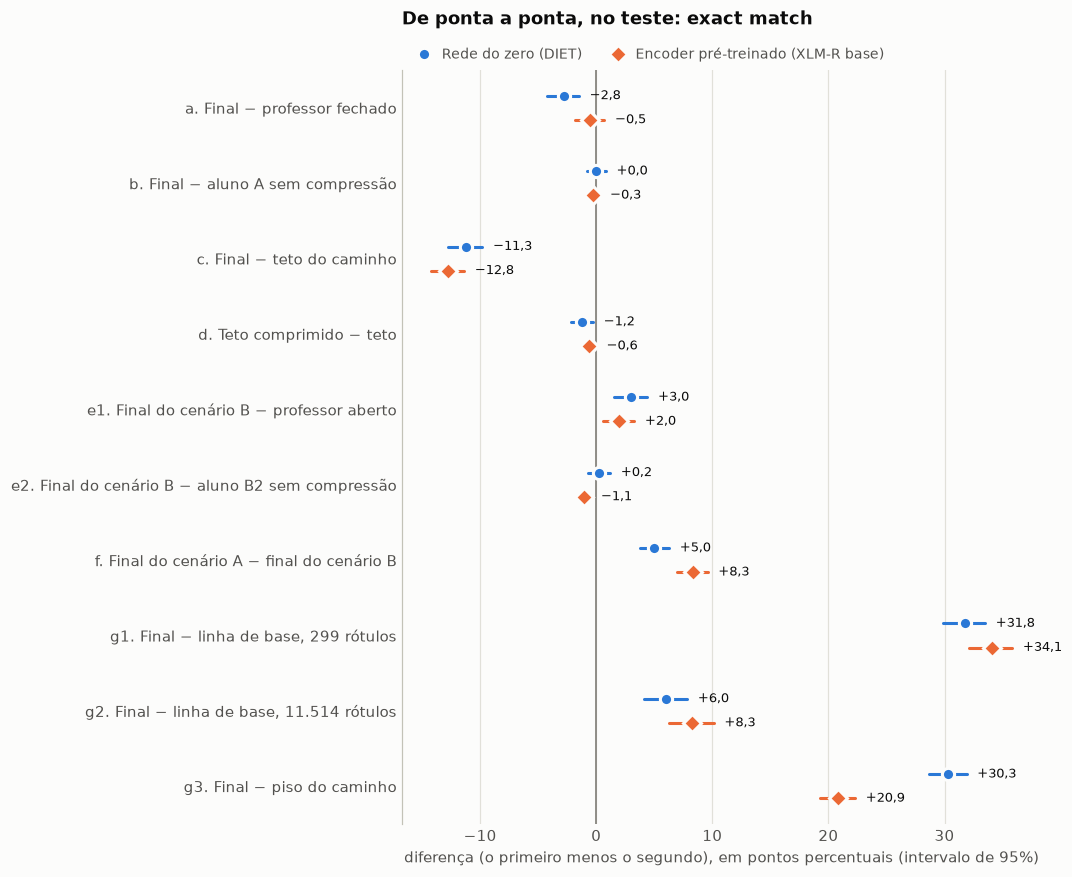

**A poda dentro dos 8 bits, no teste**

,Acurácia de intenção,F1 de entidades,Exact match
Podado em INT8 − sem poda em INT8,,,
"Do zero · Aluno A, INT8 − Do zero · Aluno A, INT8 sem poda","−0,5 (−1,2 a +0,2)","+0,1 (−0,6 a +0,7)","−0,1 (−0,9 a +0,8)"
"Do zero · Aluno B2, INT8 − Do zero · Aluno B2, INT8 sem poda","−0,1 (−0,9 a +0,8)","−0,1 (−1,1 a +0,8)","+0,3 (−0,7 a +1,3)"
"Do zero · Teto, INT8 − Do zero · Teto, INT8 sem poda","−1,0 (−1,7 a −0,2)","−0,2 (−0,9 a +0,6)","−1,2 (−2,1 a −0,3)"
"XLM-R · Aluno A, INT8 − XLM-R · Aluno A, INT8 sem poda","−0,4 (−0,8 a +0,1)","−0,5 (−0,9 a −0,0)","−1,0 (−1,6 a −0,5)"
"XLM-R · Aluno B2, INT8 − XLM-R · Aluno B2, INT8 sem poda","−0,8 (−1,1 a −0,4)","−0,9 (−1,3 a −0,5)","−1,4 (−1,9 a −1,0)"
"XLM-R · Teto, INT8 − XLM-R · Teto, INT8 sem poda","−0,4 (−0,8 a −0,1)","−0,3 (−0,8 a +0,1)","−0,5 (−0,9 a +0,0)"


In [10]:
contra_o_professor = [c for c in regras["comparacoes"] if "aluno_professor" in c["familias"]]


def tabela_de_pares(itens, particao, rotulo="Comparação (B − A)"):
    return pd.DataFrame([{rotulo: f"{nome(c['b'])} − {nome(c['a'])}", **{qualidade.NOMES[m]: com_intervalo(comp(c["b"], c["a"], m, particao)) for m in TRES}} for c in itens])


tabelas_professor = {p: tabela_de_pares(contra_o_professor, p, "Aluno − professor") for p in ("test", "dev")}
for p in ("test", "dev"):
    display(Markdown(f"**Aluno menos professor, em {'`dev`' if p == 'dev' else 'teste'}**"))
    display(tabelas_professor[p].set_index("Aluno − professor"))
fig, ax = diferencas({f"{nome(c['b'])} − {T.loc[c['a'], 'curto']}": trio(comp(c["b"], c["a"])) for c in contra_o_professor},
                     "Cada aluno menos o seu professor, no teste: exact match", "diferença, em pontos percentuais (intervalo de 95%)")
visual.salvar(fig, PASTA, "aluno_menos_professor_exact_match")
plt.show()

# De ponta a ponta: as dez letras da Etapa 9, nos dois caminhos
LETRAS = [letra for letra, *_ in etapa9.PONTA_A_PONTA]
par_da_letra = {caminho: {letra: (etapa10d.chave_no(caminho, b, fichas, CAMINHOS), etapa10d.chave_no(caminho, a, fichas, CAMINHOS)) for letra, b, a, _ in etapa9.PONTA_A_PONTA} for caminho in (ZERO, XLMR)}
ROTULO_DA_LETRA = {"a": "a. Final − professor fechado", "b": "b. Final − aluno A sem compressão", "c": "c. Final − teto do caminho", "d": "d. Teto comprimido − teto", "e1": "e1. Final do cenário B − professor aberto",
                   "e2": "e2. Final do cenário B − aluno B2 sem compressão", "f": "f. Final do cenário A − final do cenário B", "g1": f"g1. Final − linha de base, {n(POUCOS)} rótulos",
                   "g2": f"g2. Final − linha de base, {n(TODOS)} rótulos", "g3": "g3. Final − piso do caminho"}


def tabela_de_ponta_a_ponta(particao):
    return pd.DataFrame([
        {"Comparação (B − A), em cada caminho": ROTULO_DA_LETRA[letra],
         **{f"{CAMINHOS[c]['curto']}: {qualidade.NOMES[m].lower() if not qualidade.NOMES[m].startswith('F1') else qualidade.NOMES[m]}": com_intervalo(comp(*par_da_letra[c][letra], m, particao)) for m in ("exact_match", "intent_acc", "slot_f1") for c in (ZERO, XLMR)}}
        for letra in LETRAS
    ])


tabelas_pp = {p: tabela_de_ponta_a_ponta(p) for p in ("test", "dev")}
display(Markdown("**De ponta a ponta, no teste**"))
display(tabelas_pp["test"].set_index("Comparação (B − A), em cada caminho"))
fig, ax = visual.pontos_com_intervalo({CAMINHOS[c]["nome"]: {ROTULO_DA_LETRA[letra]: trio(comp(*par_da_letra[c][letra])) for letra in LETRAS} for c in (ZERO, XLMR)},
                                      "De ponta a ponta, no teste: exact match", "diferença (o primeiro menos o segundo), em pontos percentuais (intervalo de 95%)")
ax.axvline(0, color=visual.TINTA_SUAVE, linewidth=1.2, zorder=0.6)
for anotacao in ax.texts:   # diferenças: o sinal fica explícito
    valor = float(anotacao.get_text().replace(",", "."))
    anotacao.set_text(f"{valor:+.1f}".replace(".", ",").replace("-", "−"))
visual.salvar(fig, PASTA, "ponta_a_ponta_exact_match")
plt.show()

poda8 = [c for c in regras["comparacoes"] if "poda_nos_8_bits" in c["familias"]]
tabelas_poda8 = {p: tabela_de_pares(poda8, p, "Podado em INT8 − sem poda em INT8") for p in ("test", "dev")}
display(Markdown("**A poda dentro dos 8 bits, no teste**"))
display(tabelas_poda8["test"].set_index("Podado em INT8 − sem poda em INT8"))

In [11]:
pz, px = par_da_letra[ZERO], par_da_letra[XLMR]
em = lambda par, particao="test": comp(*par, "exact_match", particao)
passam = [(c["b"], m) for c in contra_o_professor for m in TRES if comp(c["b"], c["a"], m)["ic_min"] > 0]
abaixo = [(c["b"], m) for c in contra_o_professor for m in TRES if comp(c["b"], c["a"], m)["ic_max"] < 0]
todos_os_pares = [(c["b"], c["a"]) for c in regras["comparacoes"]]
total_de_intervalos = len(todos_os_pares) * len(TRES)
distinguiveis_no_teste = sum(bool(comp(b, a, m)["distinguivel"]) for b, a in todos_os_pares for m in TRES)
distinguiveis_em_dev = sum(bool(comp(b, a, m, "dev")["distinguivel"]) for b, a in todos_os_pares for m in TRES)
sem_poda_x, sem_poda_z = f"{fichas[FX]['de_partida']}/int8_sem_poda", f"{fichas[FZ]['de_partida']}/int8_sem_poda"
leituras_pp = [
    f"**a. Contra o professor fechado.** O final da rede do zero fica {frase(*pz['a'])} em relação ao {PROFESSOR}; o do XLM-R, {frase(*px['a'])}. Em `dev`, em exact match: {com_intervalo(em(pz['a'], 'dev'))} e {com_intervalo(em(px['a'], 'dev'))}.",
    f"**Quem passa o professor** (intervalo todo acima de zero, no teste): {lista(f'{nome(b)} em {metrica_na_frase(m)}' for b, m in passam) if passam else 'ninguém'}. "
    f"**Quem fica abaixo**: {lista(f'{nome(b)} em {metrica_na_frase(m)}' for b, m in abaixo) if abaixo else 'ninguém'}.",
    f"**b. O custo de toda a compressão.** Na rede do zero: {frase(*pz['b'])}. No XLM-R: {frase(*px['b'])}. "
    f"Em tamanho, a compressão leva a rede do zero de {tamanho(T.loc[pz['b'][1], 'bytes'])} para {tamanho(T.loc[FZ, 'bytes'])} ({vezes(T.loc[pz['b'][1], 'bytes'], T.loc[FZ, 'bytes'])} vezes) e o XLM-R de {tamanho(T.loc[px['b'][1], 'bytes'])} para {tamanho(T.loc[FX, 'bytes'])} ({vezes(T.loc[px['b'][1], 'bytes'], T.loc[FX, 'bytes'])} vezes); "
    f"em latência, de {ms(T.loc[pz['b'][1], 'latencia_p50_ms'])} para {ms(T.loc[FZ, 'latencia_p50_ms'])} ({vezes(T.loc[pz['b'][1], 'latencia_p50_ms'], T.loc[FZ, 'latencia_p50_ms'])} vezes) e de {ms(T.loc[px['b'][1], 'latencia_p50_ms'])} para {ms(T.loc[FX, 'latencia_p50_ms'])} ({vezes(T.loc[px['b'][1], 'latencia_p50_ms'], T.loc[FX, 'latencia_p50_ms'])} vezes).",
    f"**c. Contra o teto do próprio caminho.** Sem os {n(TODOS)} rótulos humanos de treino, o final da rede do zero fica {com_intervalo(em(pz['c']))} em exact match e o do XLM-R, {com_intervalo(em(px['c']))}. "
    + ("Pelos valores medidos, a distância para o teto não diminui com o encoder pré-treinado: o teto sobe tanto quanto o aluno, ou mais. " if em(px['c'])['diferenca'] <= em(pz['c'])['diferenca'] else "Pelos valores medidos, a distância para o teto é menor com o encoder pré-treinado. ")
    + "Se as duas distâncias diferem entre si não foi testado.",
    f"**d. A compressão sozinha, no teto.** Rede do zero: {com_intervalo(em(pz['d']))}; XLM-R: {com_intervalo(em(px['d']))} em exact match.",
    f"**e. O cenário B.** O final do cenário B fica {com_intervalo(em(pz['e1']))} em relação ao {ABERTO} na rede do zero e {com_intervalo(em(px['e1']))} no XLM-R; contra o aluno B2 sem compressão, {com_intervalo(em(pz['e2']))} e {com_intervalo(em(px['e2']))}.",
    f"**f. Um cenário contra o outro.** O final do cenário A menos o do cenário B: {com_intervalo(em(pz['f']))} na rede do zero e {com_intervalo(em(px['f']))} no XLM-R. "
    + (f"Pelos valores medidos, trocar de professor pesa mais que trocar de caminho: as duas distâncias entre cenários são maiores que a distância entre os dois modelos finais ({com_intervalo(comp(FX, FZ))})." if min(em(pz['f'])['diferenca'], em(px['f'])['diferenca']) > comp(FX, FZ)['diferenca']
       else f"A distância entre os dois modelos finais é {com_intervalo(comp(FX, FZ))}."),
    f"**g. Contra as referências.** Contra a linha de base com os mesmos {n(POUCOS)} rótulos: {com_intervalo(em(pz['g1']))} e {com_intervalo(em(px['g1']))}; contra a linha de base com os {n(TODOS)}: {com_intervalo(em(pz['g2']))} e {com_intervalo(em(px['g2']))}; contra o piso do próprio caminho: {com_intervalo(em(pz['g3']))} e {com_intervalo(em(px['g3']))} (o piso do XLM-R é mais alto: {pts(T.loc[px['g3'][1], 'exact_match'])}% contra {pts(T.loc[pz['g3'][1], 'exact_match'])}%).",
    f"**A poda dentro dos 8 bits.** O final do XLM-R menos o mesmo aluno em INT8 sem poda: {frase(FX, sem_poda_x)} no teste; em `dev`, {com_intervalo(comp(FX, sem_poda_x, 'exact_match', 'dev'))} em exact match. Na rede do zero: {com_intervalo(comp(FZ, sem_poda_z))} no teste e {com_intervalo(comp(FZ, sem_poda_z, 'exact_match', 'dev'))} em `dev`. "
    f"O INT8 sem poda do XLM-R tem {tamanho(T.loc[sem_poda_x, 'bytes'])}, contra {tamanho(T.loc[FX, 'bytes'])} do final.",
    f"**Quantas se distinguem.** A lista fechada tem {len(todos_os_pares)} comparações × {len(TRES)} métricas = {total_de_intervalos} intervalos por partição; {distinguiveis_no_teste} se distinguem de zero no teste e {distinguiveis_em_dev} em `dev`. "
    f"Sem correção para comparações múltiplas: cerca de {num(0.05 * total_de_intervalos, 0)} sairiam do zero só por acaso. `dev` e teste discordam em {len(discordam(todos_os_pares))} dos {total_de_intervalos}.",
]
display(Markdown("**Leitura.**\n\n" + "\n".join(f"- {l}" for l in leituras_pp)))

**Leitura.**

- **a. Contra o professor fechado.** O final da rede do zero fica abaixo em acurácia de intenção (−3,3 (−4,4 a −2,2)); sem diferença distinguível em F1 de entidades (−1,2 (−2,4 a +0,0)); abaixo em exact match (−2,8 (−4,3 a −1,5)) em relação ao Claude Haiku 5.5; o do XLM-R, abaixo em acurácia de intenção (−1,0 (−2,0 a −0,1)); sem diferença distinguível em F1 de entidades (−0,9 (−2,1 a +0,2)); sem diferença distinguível em exact match (−0,5 (−1,9 a +0,7)). Em `dev`, em exact match: −3,0 (−4,8 a −1,3) e −0,7 (−2,3 a +0,9).
- **Quem passa o professor** (intervalo todo acima de zero, no teste): Do zero · Aluno B1 em F1 de entidades; Do zero · Aluno B2 em F1 de entidades; Do zero · Aluno B2 em exact match; Do zero · Aluno B2, INT8 em F1 de entidades; Do zero · Aluno B2, INT8 em exact match; XLM-R · Aluno B1 em F1 de entidades; XLM-R · Aluno B1 em exact match; XLM-R · Aluno B2 em acurácia de intenção; XLM-R · Aluno B2 em F1 de entidades; XLM-R · Aluno B2 em exact match; XLM-R · Aluno B2, INT8 em F1 de entidades; XLM-R · Aluno B2, INT8 em exact match. **Quem fica abaixo**: Do zero · Aluno A em acurácia de intenção; Do zero · Aluno A em F1 de entidades; Do zero · Aluno A em exact match; Do zero · Aluno B1 em acurácia de intenção; Do zero · Aluno A, INT8 em acurácia de intenção; Do zero · Aluno A, INT8 em exact match; XLM-R · Aluno A, INT8 em acurácia de intenção.
- **b. O custo de toda a compressão.** Na rede do zero: sem diferença distinguível em acurácia de intenção (−0,5 (−1,2 a +0,2)); sem diferença distinguível em F1 de entidades (+0,1 (−0,6 a +0,7)); sem diferença distinguível em exact match (+0,0 (−0,8 a +0,8)). No XLM-R: sem diferença distinguível em acurácia de intenção (−0,2 (−0,7 a +0,3)); sem diferença distinguível em F1 de entidades (−0,4 (−1,0 a +0,1)); sem diferença distinguível em exact match (−0,3 (−0,9 a +0,3)). Em tamanho, a compressão leva a rede do zero de 19,9 MB para 2,11 MB (9,4 vezes) e o XLM-R de 1,1 GB para 90,7 MB (12,4 vezes); em latência, de 1,11 ms para 0,26 ms (4,2 vezes) e de 35,82 ms para 8,35 ms (4,3 vezes).
- **c. Contra o teto do próprio caminho.** Sem os 11.514 rótulos humanos de treino, o final da rede do zero fica −11,3 (−12,8 a −9,8) em exact match e o do XLM-R, −12,8 (−14,2 a −11,4). Pelos valores medidos, a distância para o teto não diminui com o encoder pré-treinado: o teto sobe tanto quanto o aluno, ou mais. Se as duas distâncias diferem entre si não foi testado.
- **d. A compressão sozinha, no teto.** Rede do zero: −1,2 (−2,2 a −0,3); XLM-R: −0,6 (−1,3 a −0,0) em exact match.
- **e. O cenário B.** O final do cenário B fica +3,0 (+1,5 a +4,4) em relação ao Qwen3-8B na rede do zero e +2,0 (+0,6 a +3,3) no XLM-R; contra o aluno B2 sem compressão, +0,2 (−0,7 a +1,2) e −1,1 (−1,6 a −0,5).
- **f. Um cenário contra o outro.** O final do cenário A menos o do cenário B: +5,0 (+3,8 a +6,3) na rede do zero e +8,3 (+7,0 a +9,6) no XLM-R. Pelos valores medidos, trocar de professor pesa mais que trocar de caminho: as duas distâncias entre cenários são maiores que a distância entre os dois modelos finais (+2,3 (+1,3 a +3,3)).
- **g. Contra as referências.** Contra a linha de base com os mesmos 299 rótulos: +31,8 (+29,9 a +33,5) e +34,1 (+32,1 a +35,8); contra a linha de base com os 11.514: +6,0 (+4,1 a +7,8) e +8,3 (+6,3 a +10,1); contra o piso do próprio caminho: +30,3 (+28,7 a +31,9) e +20,9 (+19,3 a +22,3) (o piso do XLM-R é mais alto: 32,6% contra 20,9%).
- **A poda dentro dos 8 bits.** O final do XLM-R menos o mesmo aluno em INT8 sem poda: sem diferença distinguível em acurácia de intenção (−0,4 (−0,8 a +0,1)); abaixo em F1 de entidades (−0,5 (−0,9 a −0,0)); abaixo em exact match (−1,0 (−1,6 a −0,5)) no teste; em `dev`, −0,5 (−1,1 a +0,1) em exact match. Na rede do zero: −0,1 (−0,9 a +0,8) no teste e −0,3 (−1,3 a +0,6) em `dev`. O INT8 sem poda do XLM-R tem 287,3 MB, contra 90,7 MB do final.
- **Quantas se distinguem.** A lista fechada tem 43 comparações × 3 métricas = 129 intervalos por partição; 87 se distinguem de zero no teste e 77 em `dev`. Sem correção para comparações múltiplas: cerca de 6 sairiam do zero só por acaso. `dev` e teste discordam em 20 dos 129.

## 8. A fronteira e o preço de cada ponto

Os sistemas num plano: custo no eixo horizontal, em **escala logarítmica**, e exact match no vertical. A **cor** diz o caminho. Uma **linha** liga as formas do mesmo aluno (sem compressão, exportado ou podado, INT8). A **linha tracejada** é a fronteira dos sistemas com os poucos rótulos humanos, dos dois caminhos juntos. Em cinza, as LLMs professoras, que os dois caminhos dividem. Círculo vazado: formas entregues que não estão na cadeia (INT8 sem poda; pesos soltos com zip).

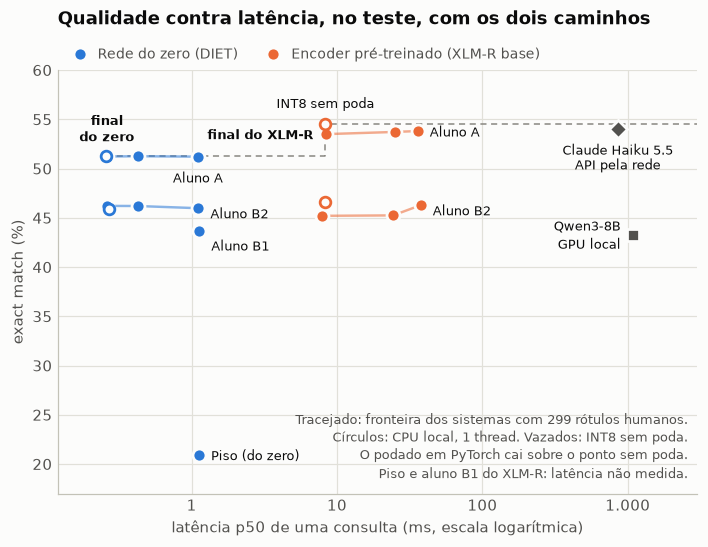

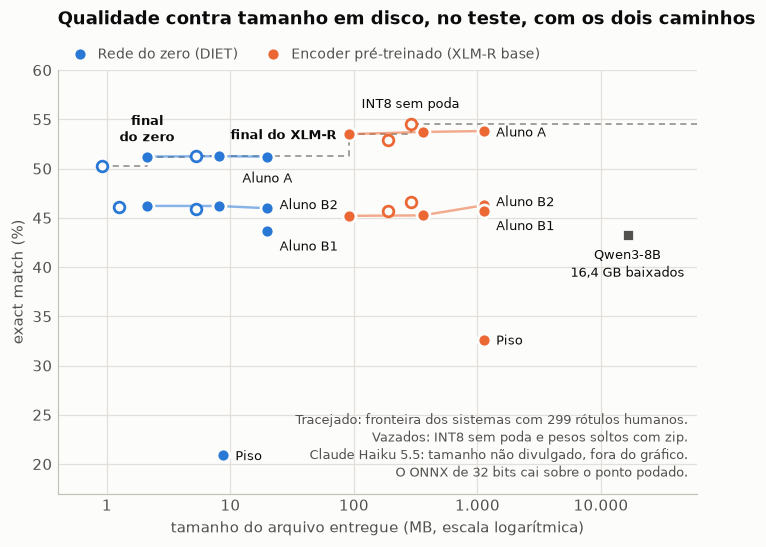

In [12]:
SERIES = [CAMINHOS[ZERO]["nome"], CAMINHOS[XLMR]["nome"]]
MARCADOR = {CPU: "o", GPU: "s", API: "D"}
serie = lambda chave: None if caminho_de(chave) is None else int(caminho_de(chave) == XLMR)
em_pontos = lambda chave: 100 * T.loc[chave, "exact_match"]
megas_de = etapa10d.megas_entregues(T)
ROTULO_DA_FRONTEIRA = f"fronteira dos sistemas com {n(POUCOS)} rótulos humanos"
ALUNOS = ("aluno_a", "aluno_b2")
ROTULO_DO_FINAL = {ZERO: "final\ndo zero", XLMR: "final do XLM-R"}
P = {ZERO: CAMINHOS[ZERO]["prefixo"], XLMR: CAMINHOS[XLMR]["prefixo"]}
front = lambda custo, usada="etapas de origem": FRONT[(FRONT["custo"] == custo) & (FRONT["latencia_usada"] == usada)].set_index("chave")
fronteira_lat = list(front("latencia")[front("latencia")["na_fronteira"]].sort_values("valor_do_custo").index)
fronteira_tam = list(front("tamanho")[front("tamanho")["na_fronteira"]].sort_values("valor_do_custo").index)


def ponto(chave, custo, rotulo=None, **extras):
    return {"x": custo(chave), "y": em_pontos(chave), "rotulo": rotulo, "serie": serie(chave), **extras}


# ---- qualidade contra latência
lat = lambda chave: T.loc[chave, "latencia_p50_ms"]
pontos = []
for c in (ZERO, XLMR):
    for a in ALUNOS:
        k = P[c] + a
        final = T.loc[f"{k}/int8", "final"]
        pontos += [ponto(k, lat, T.loc[k, "curto"], lado="baixo" if (c, a) == (ZERO, "aluno_a") else "direita", desvio=(0, 0) if a == "aluno_a" else (0, -3)), ponto(f"{k}/onnx", lat),
                   ponto(f"{k}/int8", lat, ROTULO_DO_FINAL[c] if final else None, lado="cima" if c == ZERO else "esquerda", forte=True),
                   ponto(f"{k}/int8_sem_poda", lat, "INT8 sem poda" if (c, a) == (XLMR, "aluno_a") else None, lado="cima", vazado=True)]
pontos += [
    ponto("aluno_b1", lat, T.loc["aluno_b1", "curto"], lado="direita", desvio=(0, -9)),
    ponto("piso", lat, f"{T.loc['piso', 'curto']} (do zero)", lado="direita"),
    ponto("claude", lat, f"{PROFESSOR}\n{API}", lado="baixo", marcador=MARCADOR[API]),
    ponto("qwen", lat, f"{ABERTO}\n{GPU}", lado="esquerda", marcador=MARCADOR[GPU]),
]
fig, ax = visual.fronteira(
    pontos, "Qualidade contra latência, no teste, com os dois caminhos", "latência p50 de uma consulta (ms, escala logarítmica)", "exact match (%)", series=SERIES,
    trilhas=[{"pontos": [(lat(k), em_pontos(k)) for k in (f"{P[c]}{a}/int8", f"{P[c]}{a}/onnx", P[c] + a)], "serie": int(c == XLMR)} for c in (ZERO, XLMR) for a in ALUNOS],
    escada=[(lat(k), em_pontos(k)) for k in fronteira_lat] + [(3000, em_pontos(fronteira_lat[-1]))],
    nota=f"Tracejado: {ROTULO_DA_FRONTEIRA}.\nCírculos: CPU local, 1 thread. Vazados: INT8 sem poda.\nO podado em PyTorch cai sobre o ponto sem poda.\nPiso e aluno B1 do XLM-R: latência não medida.",
)
ax.set_xlim(0.12, 3000)
ax.set_ylim(17, 60)
visual.salvar(fig, PASTA, "fronteira_latencia")
plt.show()

# ---- qualidade contra tamanho: o arquivo como é entregue
megas = lambda chave: megas_de.loc[chave]
pontos = []
for c in (ZERO, XLMR):
    for a in ALUNOS:
        k = P[c] + a
        final = T.loc[f"{k}/int8", "final"]
        pontos += [ponto(k, megas, T.loc[k, "curto"], lado="baixo" if (c, a) == (ZERO, "aluno_a") else "direita", desvio=(0, 0) if a == "aluno_a" else (0, 3)), ponto(f"{k}/podado", megas),
                   ponto(f"{k}/int8", megas, ROTULO_DO_FINAL[c] if final else None, lado="cima" if c == ZERO else "esquerda", forte=True),
                   ponto(f"{k}/int8_sem_poda", megas, "INT8 sem poda" if (c, a) == (XLMR, "aluno_a") else None, lado="cima", vazado=True), ponto(f"{k}/soltos", megas, vazado=True)]
    pontos += [ponto(P[c] + "aluno_b1", megas, T.loc[P[c] + "aluno_b1", "curto"], lado="direita", desvio=(0, -9)), ponto(P[c] + "piso", megas, T.loc[P[c] + "piso", "curto"], lado="direita")]
if pd.notna(T.loc["qwen", "bytes"]):
    pontos.append(ponto("qwen", megas, f"{ABERTO}\n{tamanho(T.loc['qwen', 'bytes'])} baixados", lado="baixo", marcador=MARCADOR[GPU]))
fig, ax = visual.fronteira(
    pontos, "Qualidade contra tamanho em disco, no teste, com os dois caminhos", "tamanho do arquivo entregue (MB, escala logarítmica)", "exact match (%)", series=SERIES,
    trilhas=[{"pontos": [(megas(k), em_pontos(k)) for k in (f"{P[c]}{a}/int8", f"{P[c]}{a}/podado", P[c] + a)], "serie": int(c == XLMR)} for c in (ZERO, XLMR) for a in ALUNOS],
    escada=[(megas(k), em_pontos(k)) for k in fronteira_tam] + [(60000, em_pontos(fronteira_tam[-1]))],
    nota=f"Tracejado: {ROTULO_DA_FRONTEIRA}.\nVazados: INT8 sem poda e pesos soltos com zip.\n{PROFESSOR}: tamanho não divulgado, fora do gráfico.\nO ONNX de 32 bits cai sobre o ponto podado.",
)
ax.set_xlim(0.4, 60000)
ax.set_ylim(17, 60)
visual.salvar(fig, PASTA, "fronteira_tamanho")
plt.show()

In [13]:
def quem_domina(custo, usada="etapas de origem"):
    """Para cada sistema fora da fronteira: quem o domina, pelos valores medidos."""
    f = front(custo, usada)
    return pd.DataFrame([
        {"Sistema": nome(c), ("Latência p50" if custo == "latencia" else "Tamanho entregue"): ms(l["valor_do_custo"]) if custo == "latencia" else tamanho(1e6 * l["valor_do_custo"]),
         "Exact match": pts(l["exact_match"]), "Na fronteira": "sim" if l["na_fronteira"] else "não",
         "Dominado por": "—" if l["na_fronteira"] else lista(nome(k) for k in l["dominado_por"].split("; "))}
        for c, l in f.sort_values("valor_do_custo").iterrows()
    ])


tabelas_da_fronteira = {custo: quem_domina(custo) for custo in ("latencia", "tamanho")}
for custo, titulo in (("latencia", "Qualidade contra latência"), ("tamanho", "Qualidade contra tamanho")):
    display(Markdown(f"**{titulo}: quem está na fronteira e quem domina quem**"))
    display(tabelas_da_fronteira[custo].set_index("Sistema"))

# O preço de cada ponto, entre os dois modelos finais
def linha_do_preco(l):
    preco = (f"{num(l['por_ponto_valor'], 1 if l['unidade'] == 'MB' else 2)} {l['unidade']} ({num(l['por_ponto_ic_min'], 1 if l['unidade'] == 'MB' else 2)} a {num(l['por_ponto_ic_max'], 1 if l['unidade'] == 'MB' else 2)})"
             if l["definido"] else "não definido: o ganho não se distingue de zero")
    fmt = (lambda v: tamanho(1e6 * v)) if l["unidade"] == "MB" else ms
    return {"Partição": NOME_DA_PARTICAO[l["particao"]], "Custo": "tamanho em disco" if l["custo"] == "tamanho" else f"latência p50 ({l['fonte_do_custo']})",
            "Final do XLM-R": fmt(l["do_final"]), "Final do zero": fmt(l["do_final_do_zero"]), "A mais": fmt(l["custo_a_mais"]), "Vezes": vezes(l["do_final"], l["do_final_do_zero"]),
            "Exact match a mais (pontos)": f"{dif(l['exact_match_a_mais'])} ({dif(l['exact_match_ic_min'])} a {dif(l['exact_match_ic_max'])})", "Preço de um ponto de exact match": preco}


tabela_dos_precos = pd.DataFrame([linha_do_preco(l) for _, l in PRECOS.sort_values("particao", ascending=False, kind="stable").iterrows()])
display(Markdown("**O preço de cada ponto de exact match, entre os dois modelos finais**"))
display(tabela_dos_precos)

**Qualidade contra latência: quem está na fronteira e quem domina quem**

,Latência p50,Exact match,Na fronteira,Dominado por
Sistema,,,,
"Do zero · Aluno A, INT8 sem poda","0,26 ms","51,3",sim,—
"Do zero · Aluno B2, INT8","0,26 ms","46,2",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno A, INT8","0,26 ms","51,2",não,"Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno A, pesos soltos, INT8 com zip","0,27 ms","50,3",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, INT8 sem poda","0,27 ms","45,9",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, pesos soltos, INT8 com zip","0,27 ms","46,1",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, ONNX 32 bits","0,42 ms","46,2",não,"Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno A, ONNX 32 bits","0,43 ms","51,3",não,"Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, podado","1,10 ms","46,2",não,"Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, ONNX 32 bits; Do zero · A..."


**Qualidade contra tamanho: quem está na fronteira e quem domina quem**

,Tamanho entregue,Exact match,Na fronteira,Dominado por
Sistema,,,,
"Do zero · Aluno A, pesos soltos, INT8 com zip","0,92 MB","50,3",sim,—
"Do zero · Aluno B2, pesos soltos, INT8 com zip","1,26 MB","46,1",não,"Do zero · Aluno A, pesos soltos, INT8 com zip"
"Do zero · Aluno B2, INT8","2,11 MB","46,2",não,"Do zero · Aluno A, pesos soltos, INT8 com zip"
"Do zero · Aluno A, INT8","2,11 MB","51,2",sim,—
"Do zero · Aluno A, INT8 sem poda","5,26 MB","51,3",sim,—
"Do zero · Aluno B2, INT8 sem poda","5,26 MB","45,9",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, ONNX 32 bits","7,98 MB","46,2",não,"Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno A, ONNX 32 bits","7,98 MB","51,3",não,"Do zero · Aluno A, INT8 sem poda"
"Do zero · Aluno B2, podado","8,06 MB","46,2",não,"Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda"


**O preço de cada ponto de exact match, entre os dois modelos finais**

,Partição,Custo,Final do XLM-R,Final do zero,A mais,Vezes,Exact match a mais (pontos),Preço de um ponto de exact match
0,teste,tamanho em disco,"90,7 MB","2,11 MB","88,6 MB","42,9","+2,3 (+1,3 a +3,3)","38,9 MB (26,9 a 70,5)"
1,teste,latência p50 (etapas de origem),"8,35 ms","0,26 ms","8,09 ms","32,0","+2,3 (+1,3 a +3,3)","3,56 ms (2,45 a 6,44)"
2,teste,latência p50 (mesma sessão),"8,00 ms","0,26 ms","7,74 ms","31,2","+2,3 (+1,3 a +3,3)","3,40 ms (2,35 a 6,17)"
3,dev,tamanho em disco,"90,7 MB","2,11 MB","88,6 MB","42,9","+2,3 (+1,2 a +3,6)","38,0 MB (24,4 a 76,1)"
4,dev,latência p50 (etapas de origem),"8,35 ms","0,26 ms","8,09 ms","32,0","+2,3 (+1,2 a +3,6)","3,47 ms (2,23 a 6,95)"
5,dev,latência p50 (mesma sessão),"8,00 ms","0,26 ms","7,74 ms","31,2","+2,3 (+1,2 a +3,6)","3,33 ms (2,14 a 6,65)"


In [14]:
preco = lambda custo, particao="test", fonte=None: PRECOS[(PRECOS["custo"] == custo) & (PRECOS["particao"] == particao) & ((PRECOS["fonte_do_custo"] == fonte) if fonte else True)].iloc[0]
texto_do_preco = lambda l, casas: f"{num(l['por_ponto_valor'], casas)} {l['unidade']} ({num(l['por_ponto_ic_min'], casas)} a {num(l['por_ponto_ic_max'], casas)})" if l["definido"] else "não definido (o ganho não se distingue de zero)"
p_mb, p_ms = preco("tamanho"), preco("latencia", fonte="etapas de origem")
p_mb_dev, p_ms_dev = preco("tamanho", "dev"), preco("latencia", "dev", "etapas de origem")
nomes_com_valor = lambda chaves: lista(f"{nome(c)} ({pts(T.loc[c, 'exact_match'])}%)" for c in chaves)
f_lat, f_tam = front("latencia"), front("tamanho")
dominadores = lambda f, chave: lista(nome(k) for k in f.loc[chave, "dominado_por"].split("; "))
situacao = lambda f, chave: "está na fronteira" if f.loc[chave, "na_fronteira"] else f"é dominado por {dominadores(f, chave)}"
medida_nova = len(LAT) > 0
f_lat_nova = front("latencia", "mesma sessão, nos sistemas medidos de novo") if medida_nova else None
fronteira_lat_nova = list(f_lat_nova[f_lat_nova["na_fronteira"]].sort_values("valor_do_custo").index) if medida_nova else None
de_outro_caminho = lambda f, chave: [k for k in f.loc[chave, "dominado_por"].split("; ") if k and caminho_de(k) not in (None, caminho_de(chave))]
ninguem_cruza = not any(de_outro_caminho(f, chave) for f in (f_lat, f_tam) for chave in (FZ, FX))
poda8_z, poda8_x = comp(FZ, sem_poda_z), comp(FX, sem_poda_x)

# Exploratória (acrescentada depois de ver a fronteira; não está nas regras): a mesma fronteira só com as linhas da Etapa 9 e as equivalentes do XLM-R, sem o INT8 sem poda
SEM_INT8_SEM_PODA = etapa10d.fronteiras(T[T["ponto"] != "int8_sem_poda"], FOLGA).assign(exploratoria=True)
da_cadeia = lambda custo: list(SEM_INT8_SEM_PODA[(SEM_INT8_SEM_PODA["custo"] == custo) & SEM_INT8_SEM_PODA["na_fronteira"]].sort_values("valor_do_custo")["chave"])

leitura_da_fronteira = [
    "**Quem domina quem, entre os caminhos.** " + ("Nenhum sistema de um caminho domina o modelo final do outro, nem em latência nem em tamanho: a rede do zero ocupa o lado barato das duas fronteiras e o XLM-R, o lado de mais qualidade. "
                                                  if ninguem_cruza else "Há sistema de um caminho que domina o modelo final do outro (tabelas acima). ")
    + ("Nenhum sistema do cenário B (alunos B1 e B2, em qualquer forma, nos dois caminhos) está em nenhuma das duas fronteiras. " if not any(f.loc[c, "na_fronteira"] for f in (f_lat, f_tam) for c in f.index if T.loc[c, "modelo"] in ("aluno_b1", "aluno_b2")) else "Há sistema do cenário B na fronteira. ")
    + f"Em latência, o {ABERTO} {'é dominado por ' + str(int(f_lat.loc['qwen', 'quantos_o_dominam'])) + ' sistemas, dos dois caminhos' if not f_lat.loc['qwen', 'na_fronteira'] else 'está na fronteira'}, e o {PROFESSOR} {situacao(f_lat, 'claude')}.",
    f"**Na latência, a poda não muda o custo.** Nos dois caminhos o modelo podado e o mesmo modelo sem poda respondem no mesmo tempo (seção 5), e a regra da fronteira trata latências a menos de {num(100 * FOLGA, 0)}% como empate. Entre dois empatados, fica na fronteira o de maior exact match medido. "
    f"Por isso o modelo final de cada caminho aparece dominado pelo seu próprio INT8 sem poda: na rede do zero por {num(abs(100 * poda8_z['diferenca']), 2)} ponto, que não se distingue de zero ({com_intervalo(poda8_z, casas=2)}); "
    f"no XLM-R por {num(abs(100 * poda8_x['diferenca']), 1)} ponto, que {'se distingue' if poda8_x['distinguivel'] else 'não se distingue'} no teste ({com_intervalo(poda8_x)}) e {'se distingue' if comp(FX, sem_poda_x, 'exact_match', 'dev')['distinguivel'] else 'não se distingue'} em `dev` ({com_intervalo(comp(FX, sem_poda_x, 'exact_match', 'dev'))}).",
    f"**Latência.** Entre os sistemas com {n(POUCOS)} rótulos humanos, dos dois caminhos, a fronteira tem: {nomes_com_valor(fronteira_lat)}. O final da rede do zero {situacao(f_lat, FZ)}; o final do XLM-R {situacao(f_lat, FX)}; "
    f"o {PROFESSOR} ({ms(lat('claude'))} pela API) {situacao(f_lat, 'claude')}. Latências a menos de {num(100 * FOLGA, 0)}% uma da outra contam como empate."
    + (f" Com as latências medidas na mesma sessão no lugar das de origem, a fronteira {'é a mesma' if fronteira_lat_nova == fronteira_lat else 'muda para: ' + nomes_com_valor(fronteira_lat_nova)}." if medida_nova else ""),
    f"**Tamanho.** A fronteira tem: {nomes_com_valor(fronteira_tam)}. O final da rede do zero {situacao(f_tam, FZ)}; o final do XLM-R {situacao(f_tam, FX)}.",
    f"**O INT8 sem poda do XLM-R.** Ele aparece na fronteira com {pts(T.loc[sem_poda_x, 'exact_match'])}% de exact match, {tamanho(T.loc[sem_poda_x, 'bytes'])} e {ms(lat(sem_poda_x))}. Não é o modelo final: a regra da Etapa 10b, escrita antes, escolhe o menor arquivo que não se distingue do modelo sem poda em `dev`. "
    f"Contra ele, o final fica {frase(FX, sem_poda_x)} no teste, e em `dev` {posicao(comp(FX, sem_poda_x, 'exact_match', 'dev')['ic_min'], comp(FX, sem_poda_x, 'exact_match', 'dev')['ic_max'])} em exact match ({com_intervalo(comp(FX, sem_poda_x, 'exact_match', 'dev'))}). "
    f"A fronteira ordena valores medidos; a diferença entre esses dois vizinhos é a que está nesta linha. O INT8 sem poda aparece acima do {PROFESSOR} pelo valor medido ({pts(T.loc[sem_poda_x, 'exact_match'])}% contra {pts(T.loc['claude', 'exact_match'])}%), mas essa comparação não está na lista fechada e não foi feita: não se pode dizer que ele passa o professor.",
    f"**Sem o INT8 sem poda (exploratória).** Esta conta foi acrescentada depois de ver a fronteira e não está nas regras. Só com as linhas da Etapa 9 e as equivalentes do XLM-R, a fronteira de latência seria: {nomes_com_valor(da_cadeia('latencia'))}; a de tamanho: {nomes_com_valor(da_cadeia('tamanho'))}. "
    f"O final da rede do zero {'estaria' if FZ in da_cadeia('latencia') else 'não estaria'} na de latência e o do XLM-R {'estaria' if FX in da_cadeia('latencia') else 'não estaria'}.",
    f"**O preço de cada ponto.** Entre os dois modelos finais, no teste, o XLM-R tem {dif(p_mb['exact_match_a_mais'])} ({dif(p_mb['exact_match_ic_min'])} a {dif(p_mb['exact_match_ic_max'])}) pontos de exact match a mais, {tamanho(1e6 * p_mb['custo_a_mais'])} a mais ({vezes(p_mb['do_final'], p_mb['do_final_do_zero'])} vezes) e {ms(p_ms['custo_a_mais'])} a mais por consulta ({vezes(p_ms['do_final'], p_ms['do_final_do_zero'])} vezes). "
    f"Cada ponto de exact match custa {texto_do_preco(p_mb, 1)} e {texto_do_preco(p_ms, 2)}. Em `dev`: {texto_do_preco(p_mb_dev, 1)} e {texto_do_preco(p_ms_dev, 2)}."
    + (f" Com a latência medida na mesma sessão: {texto_do_preco(preco('latencia', fonte='mesma sessão'), 2)} no teste." if medida_nova else ""),
    "**Como ler.** A fronteira usa os valores medidos, sem os intervalos: serve para ver a ordem de grandeza do custo. Dois vizinhos nela podem não se distinguir em qualidade; quem diz isso são as comparações pareadas. O intervalo do preço vem só da incerteza da qualidade: tamanho e latência são os de um modelo (semente 0).",
]
display(Markdown("**Leitura.**\n\n" + "\n".join(f"- {l}" for l in leitura_da_fronteira)))

**Leitura.**

- **Quem domina quem, entre os caminhos.** Nenhum sistema de um caminho domina o modelo final do outro, nem em latência nem em tamanho: a rede do zero ocupa o lado barato das duas fronteiras e o XLM-R, o lado de mais qualidade. Nenhum sistema do cenário B (alunos B1 e B2, em qualquer forma, nos dois caminhos) está em nenhuma das duas fronteiras. Em latência, o Qwen3-8B é dominado por 26 sistemas, dos dois caminhos, e o Claude Haiku 5.5 é dominado por XLM-R · Aluno A, INT8 sem poda.
- **Na latência, a poda não muda o custo.** Nos dois caminhos o modelo podado e o mesmo modelo sem poda respondem no mesmo tempo (seção 5), e a regra da fronteira trata latências a menos de 14% como empate. Entre dois empatados, fica na fronteira o de maior exact match medido. Por isso o modelo final de cada caminho aparece dominado pelo seu próprio INT8 sem poda: na rede do zero por 0,06 ponto, que não se distingue de zero (−0,06 (−0,85 a +0,78)); no XLM-R por 1,0 ponto, que se distingue no teste (−1,0 (−1,6 a −0,5)) e não se distingue em `dev` (−0,5 (−1,1 a +0,1)).
- **Latência.** Entre os sistemas com 299 rótulos humanos, dos dois caminhos, a fronteira tem: Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 sem poda (54,5%). O final da rede do zero é dominado por Do zero · Aluno A, INT8 sem poda; o final do XLM-R é dominado por XLM-R · Aluno A, INT8 sem poda; o Claude Haiku 5.5 (854 ms pela API) é dominado por XLM-R · Aluno A, INT8 sem poda. Latências a menos de 14% uma da outra contam como empate. Com as latências medidas na mesma sessão no lugar das de origem, a fronteira é a mesma.
- **Tamanho.** A fronteira tem: Do zero · Aluno A, pesos soltos, INT8 com zip (50,3%); Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, INT8 sem poda (54,5%). O final da rede do zero está na fronteira; o final do XLM-R está na fronteira.
- **O INT8 sem poda do XLM-R.** Ele aparece na fronteira com 54,5% de exact match, 287,3 MB e 8,33 ms. Não é o modelo final: a regra da Etapa 10b, escrita antes, escolhe o menor arquivo que não se distingue do modelo sem poda em `dev`. Contra ele, o final fica sem diferença distinguível em acurácia de intenção (−0,4 (−0,8 a +0,1)); abaixo em F1 de entidades (−0,5 (−0,9 a −0,0)); abaixo em exact match (−1,0 (−1,6 a −0,5)) no teste, e em `dev` sem diferença distinguível em exact match (−0,5 (−1,1 a +0,1)). A fronteira ordena valores medidos; a diferença entre esses dois vizinhos é a que está nesta linha. O INT8 sem poda aparece acima do Claude Haiku 5.5 pelo valor medido (54,5% contra 54,0%), mas essa comparação não está na lista fechada e não foi feita: não se pode dizer que ele passa o professor.
- **Sem o INT8 sem poda (exploratória).** Esta conta foi acrescentada depois de ver a fronteira e não está nas regras. Só com as linhas da Etapa 9 e as equivalentes do XLM-R, a fronteira de latência seria: Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, ONNX 32 bits (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, ONNX 32 bits (53,7%); XLM-R · Aluno A (53,8%); Claude Haiku 5.5 (54,0%); a de tamanho: Do zero · Aluno A, pesos soltos, INT8 com zip (50,3%); Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, ONNX 32 bits (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, ONNX 32 bits (53,7%); XLM-R · Aluno A (53,8%). O final da rede do zero estaria na de latência e o do XLM-R estaria.
- **O preço de cada ponto.** Entre os dois modelos finais, no teste, o XLM-R tem +2,3 (+1,3 a +3,3) pontos de exact match a mais, 88,6 MB a mais (42,9 vezes) e 8,09 ms a mais por consulta (32,0 vezes). Cada ponto de exact match custa 38,9 MB (26,9 a 70,5) e 3,56 ms (2,45 a 6,44). Em `dev`: 38,0 MB (24,4 a 76,1) e 3,47 ms (2,23 a 6,95). Com a latência medida na mesma sessão: 3,40 ms (2,35 a 6,17) no teste.
- **Como ler.** A fronteira usa os valores medidos, sem os intervalos: serve para ver a ordem de grandeza do custo. Dois vizinhos nela podem não se distinguir em qualidade; quem diz isso são as comparações pareadas. O intervalo do preço vem só da incerteza da qualidade: tamanho e latência são os de um modelo (semente 0).

## 9. A latência dos dois modelos finais, na mesma sessão

As latências dos dois caminhos vieram de sessões diferentes: as da rede do zero, da Etapa 8; as do XLM-R, da Etapa 10c. O protocolo é o mesmo nas duas, e é a mesma função (`eficiencia.medir_latencia`, chamada por `etapa8.medir_latencia` e por `etapa10c.medir_latencia`):

| | Etapa 8 (rede do zero) | Etapa 10c (XLM-R) | Esta etapa |
|---|---|---|---|
| Threads | 1 | 1 | 1 |
| Consultas | uma por vez, do texto à resposta | igual | igual |
| Pedidos | os de `dev`, sorteados com a semente da rodada | igual | igual |
| Aquecimento | 50 consultas por rodada | igual | igual |
| Rodadas | 5 de 1.024 consultas, sistemas alternados | igual | igual |
| Sistemas na mesma rodada | as formas de um modelo | as formas de um modelo | **os dois modelos finais**, em cada forma |
| Máquina quieta | outros processos até 0,25 núcleo | igual | igual |

O que as medidas de origem não têm é os dois caminhos **na mesma rodada**. O comando abaixo faz isso: os dois modelos finais (semente 0) em INT8, em ONNX de 32 bits e em PyTorch de 32 bits, alternados, com o medidor de "outros processos" das Etapas 8 e 10c. Cada medida vai para uma pasta com data e hora; nenhuma é sobrescrita.

```bash
uv run python -m especialista.experimentos.etapa10d latencia
```

O ONNX de 32 bits da rede do zero não está na entrega da Etapa 8 (ela entregou só as formas de 8 bits). Ele é exportado de novo, do modelo que a Etapa 7 entregou, com o código da Etapa 8. Antes de medir, cada sistema responde aos 200 primeiros pedidos de `dev` e as respostas são comparadas com as gravadas: é a garantia de que o que foi medido é o modelo da tabela.

,,p50 de origem,p50 na mesma sessão,Entre as rodadas (mesma sessão),Mesma sessão ÷ origem,Confirma a de origem,Reproduz as respostas gravadas
Sistema,Forma,,,,,,
"Do zero · Aluno A, INT8 (modelo final)",INT8,"0,26 ms (Etapa 8)","0,26 ms","0,24 a 0,27 ms","0,98",sim,sim
"XLM-R · Aluno A, INT8 (modelo final)",INT8,"8,35 ms (Etapa 10c)","8,00 ms","7,87 a 8,11 ms","0,96",sim,sim
"Do zero · Aluno A, ONNX 32 bits","ONNX, 32 bits","0,43 ms (Etapa 8)","0,42 ms","0,41 a 0,44 ms","0,99",sim,sim
"XLM-R · Aluno A, ONNX 32 bits","ONNX, 32 bits","25,08 ms (Etapa 10c)","24,35 ms","24,12 a 24,66 ms","0,97",sim,sim
"Do zero · Aluno A, podado","PyTorch, 32 bits","1,10 ms (Etapa 8)","1,11 ms","1,09 a 1,13 ms","1,01",sim,sim
"XLM-R · Aluno A, podado","PyTorch, 32 bits","36,10 ms (Etapa 10c)","35,11 ms","34,88 a 35,52 ms","0,97",sim,sim


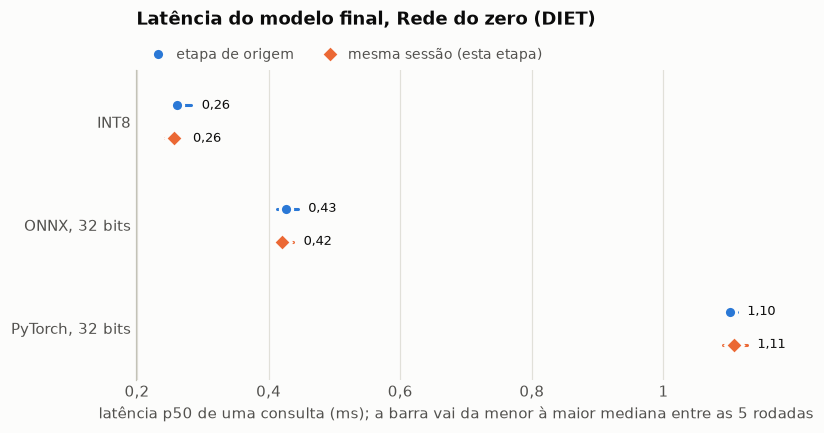

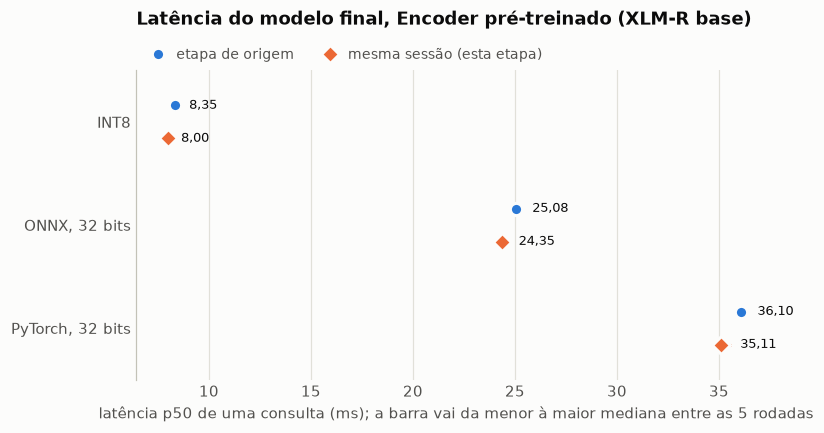

**Leitura.**

- **A medida.** Feita em 2026-11-18 às 21:01:55, com 5 rodadas de 1.024 consultas, 1 thread, os 6 sistemas alternados em cada rodada. Os outros processos ocuparam 0,068 núcleo de CPU no conjunto (o máximo numa rodada foi 0,105; o limite é 0,25): máquina quieta, sim. Os 6 sistemas reproduzem as respostas gravadas nos 200 primeiros pedidos de `dev`: sim.
- **Os dois modelos finais, em INT8.** Na mesma sessão: 0,26 ms (rede do zero) e 8,00 ms (XLM-R), 31,2 vezes. Nas etapas de origem: 0,26 ms e 8,35 ms, 32,0 vezes.
- **Em 32 bits.** ONNX: 0,42 ms e 24,35 ms (58,0 vezes; na origem, 58,9). PyTorch: 1,11 ms e 35,11 ms (31,7 vezes; na origem, 32,8).
- **Confirma a origem?** A regra: a diferença relativa entre a medida nova e a de origem é menor que a folga da fronteira (14%). Vale para os 6 sistemas: a maior diferença é de 4,2%. Os números da tabela final continuam sendo os de origem; estes ficam ao lado.

In [15]:
medidas_de_latencia = etapa10d.latencias_medidas()
if not medida_nova:
    tabela_da_latencia, FIGURAS_DA_LATENCIA, latencia_confirma, medida = pd.DataFrame(), [], None, None
    leitura_da_latencia = ["**A latência não foi medida na mesma sessão.** As latências dos dois caminhos vêm de sessões diferentes (Etapas 8 e 10c), com o mesmo protocolo. Fica como limite."]
else:
    medida = medidas_de_latencia[-1]
    assert str(medida["pasta"].relative_to(BASE)) == CALC["latencia_na_mesma_sessao"]
    NOME_DA_FORMA = {"int8": "INT8", "onnx": "ONNX, 32 bits", "pytorch": "PyTorch, 32 bits"}
    origem_das_rodadas = {ZERO: pd.read_csv(ENTREGAS / "08_quantizacao" / "eficiencia.csv"), XLMR: eficiencia10c}
    FORMA_NA_ORIGEM = {"int8": None, "onnx": "fp32", "pytorch": "pytorch"}

    def rodadas_de_origem(l):
        """A menor e a maior mediana entre as rodadas da medida de origem do mesmo sistema."""
        filtro = dict(fichas[l["chave"]]["resultado"][1])
        e = etapa9.linha_gravada(origem_das_rodadas[l["caminho"]], **filtro)
        return e["p50_min_das_rodadas"], e["p50_max_das_rodadas"]

    LAT["confirma"] = LAT["diferenca_relativa"].abs() <= FOLGA
    tabela_da_latencia = pd.DataFrame([
        {"Sistema": nome(l["chave"]) + (" (modelo final)" if T.loc[l["chave"], "final"] else ""), "Forma": NOME_DA_FORMA[l["forma"]],
         "p50 de origem": f"{ms(l['p50_de_origem_ms'])} ({l['medida_de_origem']})", "p50 na mesma sessão": ms(l["p50_mesma_sessao_ms"]),
         "Entre as rodadas (mesma sessão)": f"{num(l['p50_min_das_rodadas'], 2)} a {num(l['p50_max_das_rodadas'], 2)} ms", "Mesma sessão ÷ origem": num(1 + l["diferenca_relativa"], 2),
         "Confirma a de origem": "sim" if l["confirma"] else "não", "Reproduz as respostas gravadas": "sim" if l["reproduz_as_respostas"] else "NÃO"}
        for _, l in LAT.iterrows()
    ])
    display(tabela_da_latencia.set_index(["Sistema", "Forma"]))
    FIGURAS_DA_LATENCIA = []
    for caminho in (ZERO, XLMR):
        do_caminho = LAT[LAT["caminho"] == caminho]
        fig, ax = visual.pontos_com_intervalo(
            {"etapa de origem": {NOME_DA_FORMA[l["forma"]]: (l["p50_de_origem_ms"], *rodadas_de_origem(l)) for _, l in do_caminho.iterrows()},
             "mesma sessão (esta etapa)": {NOME_DA_FORMA[l["forma"]]: (l["p50_mesma_sessao_ms"], l["p50_min_das_rodadas"], l["p50_max_das_rodadas"]) for _, l in do_caminho.iterrows()}},
            f"Latência do modelo final, {CAMINHOS[caminho]['nome']}", "latência p50 de uma consulta (ms); a barra vai da menor à maior mediana entre as 5 rodadas")
        # o padrão escreve com 1 casa; a latência precisa de 2. Os textos estão na ordem em que foram desenhados: a primeira série inteira, depois a segunda
        for anotacao, valor in zip(ax.texts, [*do_caminho["p50_de_origem_ms"], *do_caminho["p50_mesma_sessao_ms"]], strict=True):
            anotacao.set_text(num(valor, 2))
        visual.salvar(fig, PASTA, f"latencia_na_mesma_sessao_{caminho}")
        plt.show()
        FIGURAS_DA_LATENCIA.append(f"latencia_na_mesma_sessao_{caminho}")

    na = lambda caminho, forma: LAT[(LAT["caminho"] == caminho) & (LAT["forma"] == forma)].iloc[0]
    latencia_confirma = bool(LAT["confirma"].all())
    razao = lambda forma, coluna: na(XLMR, forma)[coluna] / na(ZERO, forma)[coluna]
    leitura_da_latencia = [
        f"**A medida.** Feita em {medida['medido_em'].replace('T', ' às ')}, com {medida['rodadas']} rodadas de {n(medida['consultas_por_rodada'])} consultas, 1 thread, os {len(LAT)} sistemas alternados em cada rodada. "
        f"Os outros processos ocuparam {num(medida['nucleos_de_outros'], 3)} núcleo de CPU no conjunto (o máximo numa rodada foi {num(max(medida['nucleos_de_outros_por_rodada']), 3)}; o limite é {num(medida['limite_de_outros'], 2)}): máquina quieta, {'sim' if medida['maquina_quieta'] else '**NÃO**'}. "
        f"Os {len(LAT)} sistemas reproduzem as respostas gravadas nos 200 primeiros pedidos de `dev`: {'sim' if LAT['reproduz_as_respostas'].all() else '**NÃO**'}.",
        f"**Os dois modelos finais, em INT8.** Na mesma sessão: {ms(na(ZERO, 'int8')['p50_mesma_sessao_ms'])} (rede do zero) e {ms(na(XLMR, 'int8')['p50_mesma_sessao_ms'])} (XLM-R), {num(razao('int8', 'p50_mesma_sessao_ms'), 1)} vezes. "
        f"Nas etapas de origem: {ms(na(ZERO, 'int8')['p50_de_origem_ms'])} e {ms(na(XLMR, 'int8')['p50_de_origem_ms'])}, {num(razao('int8', 'p50_de_origem_ms'), 1)} vezes.",
        f"**Em 32 bits.** ONNX: {ms(na(ZERO, 'onnx')['p50_mesma_sessao_ms'])} e {ms(na(XLMR, 'onnx')['p50_mesma_sessao_ms'])} ({num(razao('onnx', 'p50_mesma_sessao_ms'), 1)} vezes; na origem, {num(razao('onnx', 'p50_de_origem_ms'), 1)}). "
        f"PyTorch: {ms(na(ZERO, 'pytorch')['p50_mesma_sessao_ms'])} e {ms(na(XLMR, 'pytorch')['p50_mesma_sessao_ms'])} ({num(razao('pytorch', 'p50_mesma_sessao_ms'), 1)} vezes; na origem, {num(razao('pytorch', 'p50_de_origem_ms'), 1)}).",
        f"**Confirma a origem?** A regra: a diferença relativa entre a medida nova e a de origem é menor que a folga da fronteira ({num(100 * FOLGA, 0)}%). "
        + ("Vale para os " + str(len(LAT)) + " sistemas: a maior diferença é de " + num(100 * LAT["diferenca_relativa"].abs().max(), 1) + "%." if latencia_confirma
           else "Não vale para: " + lista(f"{nome(l['chave'])}, {NOME_DA_FORMA[l['forma']]} ({dif(l['diferenca_relativa'])}%)" for _, l in LAT[~LAT["confirma"]].iterrows()) + ".")
        + " Os números da tabela final continuam sendo os de origem; estes ficam ao lado.",
    ]
display(Markdown("**Leitura.**\n\n" + "\n".join(f"- {l}" for l in leitura_da_latencia)))

## 10. Cada passo e o seu artigo

O quadro parte do da Etapa 9 e junta as referências que as Etapas 10a, 10b e 10c citam. Para cada passo do caminho: a técnica, o artigo, em que caminho foi usada e **se a referência foi conferida na fonte**.

A conferência foi feita nesta etapa, e é gratuita. O comando abaixo pergunta ao arXiv (API pública) o título, os autores e a data de cada identificador, busca os dois artigos da ACL Anthology na página de cada um, e grava a resposta inteira:

```bash
uv run python -m especialista.experimentos.etapa10d artigos
```

Há dois níveis, e o quadro diz qual vale para cada linha:

- **conferida**: o identificador existe na fonte, e o primeiro autor e o título que a fonte devolve são os que o projeto escreve;
- **resumo lido**: além disso, o resumo devolvido pelo arXiv foi lido nesta etapa. "sim" quer dizer que o resumo sustenta a técnica como o projeto a usa; "em parte", que o resumo confirma o assunto, mas o ponto exato que o projeto cita está no corpo do artigo.

**O corpo de nenhum artigo foi lido nesta etapa.** Os números publicados que o projeto cita (a linha do XLM-R base no MASSIVE, por exemplo) não foram conferidos de novo aqui.

In [16]:
quadro = etapa10d.quadro_de_artigos()
com_artigo = quadro[quadro["na_fonte"] != "sem artigo"]
conferidas_na_fonte = int((com_artigo["na_fonte"] == "conferida").sum())
lidas = com_artigo[com_artigo["resumo_lido"]]
da_etapa_9 = {a.get("arxiv") for a in etapa9.ARTIGOS if a.get("arxiv")} | {"W04-3250", "D12-1091"}
novas = com_artigo[~com_artigo["identificador"].isin(da_etapa_9)]
fonte_dos_artigos = sorted((BASE / "artigos").glob("arxiv_*.json"))[-1]
tabela_de_artigos = pd.DataFrame({
    "Passo": quadro["passo"], "Caminho": quadro["caminho"], "Técnica": quadro["tecnica"],
    "Artigo": [q + (f", *{t}*" if t else "") for q, t in zip(quadro["quem"], quadro["titulo_na_fonte"].where(quadro["titulo_na_fonte"] != "", quadro["titulo_no_projeto"]))],
    "Ano": ["—" if pd.isna(a) else int(a) for a in quadro["ano"]],
    "Onde": [f"[{o}]({e})" if e else "—" for o, e in zip(quadro["onde"], quadro["endereco"])],
    "Estava citado em": [c or "—" for c in quadro["citado_em"]],
    "Conferida na fonte": quadro["na_fonte"],
    "Resumo lido": ["—" if s == "sem artigo" else (r if lido else "não") for s, lido, r in zip(quadro["na_fonte"], quadro["resumo_lido"], quadro["o_resumo_sustenta"])],
})
display(Markdown(em_markdown(tabela_de_artigos)))
em_parte = lidas[lidas["o_resumo_sustenta"] == "em parte"]
display(Markdown("**O que o resumo diz, nas linhas marcadas \"em parte\"**\n\n" + "\n".join(f"- {l['quem']} ({l['onde']}): {l['o_que_o_resumo_diz']}." for _, l in em_parte.iterrows())))
sem_artigo = quadro[quadro["na_fonte"] == "sem artigo"]
leitura_dos_artigos = (
    f"O quadro tem {len(quadro)} linhas: {len(com_artigo)} referências ({com_artigo['identificador'].nunique()} artigos diferentes) e {len(sem_artigo)} passo sem artigo ({lista(sem_artigo['passo'])}: é um passo de engenharia, e nenhuma etapa cita artigo para ele). "
    f"Das {len(com_artigo)} referências, {len(com_artigo) - len(novas)} já estavam no quadro da Etapa 9 e {len(novas)} vêm das Etapas 8, 10a, 10b e 10c. "
    f"**Conferidas na fonte: {conferidas_na_fonte} de {len(com_artigo)}** (identificador, primeiro autor e título, na consulta de {quadro['consultado_em'].iloc[0].replace('T', ' às ')}). "
    f"**Com o resumo lido: {len(lidas)}**; em {int((lidas['o_resumo_sustenta'] == 'sim').sum())} o resumo sustenta a técnica como o projeto a usa, e em {len(em_parte)} sustenta em parte. "
    f"As {len(com_artigo) - len(lidas)} sem resumo lido são as da ACL Anthology, de que só o título, os autores e o ano foram conferidos. "
    "Antes desta etapa, o `PLANO.md` registrava como lidos só dois resumos e parte de um texto, e a Etapa 9 tinha conferido título e autores de três referências."
)
display(Markdown(f"**Leitura.** {leitura_dos_artigos}"))

| Passo | Caminho | Técnica | Artigo | Ano | Onde | Estava citado em | Conferida na fonte | Resumo lido |
|---|---|---|---|---|---|---|---|---|
| O caminho inteiro | os dois | Trocar a LLM por um modelo pequeno, feito para a tarefa | Belcak et al., *Small Language Models are the Future of Agentic AI* | 2025 | [arXiv 2506.02153](https://arxiv.org/abs/2506.02153) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | LLM professora, destilação, poda e quantização em sequência | Ni et al., *From Large to Super-Tiny: End-to-End Optimization for Cost-Efficient LLMs* | 2025 | [arXiv 2504.13471](https://arxiv.org/abs/2504.13471) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 6; notebook da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | A ordem: podar, quantizar e, por fim, codificar o arquivo | Han et al., *Deep Compression: Compressing Deep Neural Networks with Pruning, Trained Quantization and Huffman Coding* | 2015 | [arXiv 1510.00149](https://arxiv.org/abs/1510.00149) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7; notebook da Etapa 8; notebook da Etapa 9; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| O caminho inteiro | os dois | A ordem das técnicas de compressão importa | Harma et al., *Effective Interplay between Sparsity and Quantization: From Theory to Practice* | 2024 | [arXiv 2405.20935](https://arxiv.org/abs/2405.20935) | PLANO.md; RESUMO da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | Poda e quantização juntas podem interagir (discussão da ordem) | Nema et al., *Compression Technique Interactions in Small Language Models: A Factorial Ablation Study* | 2026 | [arXiv 2611.00464](https://arxiv.org/abs/2611.00464) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 9 | conferida | sim |
| Dados e régua | os dois | MASSIVE pt-PT; acurácia de intenção, F1 de entidades e exact match; a linha publicada do XLM-R base | FitzGerald et al., *MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages* | 2022 | [arXiv 2204.08582](https://arxiv.org/abs/2204.08582) | PLANO.md; RESUMO da Etapa 1; RESUMO da Etapa 9; RESUMO da Etapa 10a; notebook da Etapa 1; notebook da Etapa 2; notebook da Etapa 10a | conferida | em parte |
| Dados e régua | os dois | Intervalo de 95% e comparação pareada por bootstrap, por enunciado | Koehn, *Statistical Significance Tests for Machine Translation Evaluation* | 2004 | [ACL Anthology W04-3250](https://aclanthology.org/W04-3250/) | RESUMO da Etapa 9 | conferida | não |
| Dados e régua | os dois | Intervalo de 95% e comparação pareada por bootstrap, por enunciado | Berg-Kirkpatrick et al., *An Empirical Investigation of Statistical Significance in NLP* | 2012 | [ACL Anthology D12-1091](https://aclanthology.org/D12-1091/) | RESUMO da Etapa 9 | conferida | não |
| Dados e régua | os dois | Três sementes por modelo treinado; o resultado é a média | Reimers & Gurevych, *Reporting Score Distributions Makes a Difference: Performance Study of LSTM-networks for Sequence Tagging* | 2017 | [arXiv 1707.09861](https://arxiv.org/abs/1707.09861) | RESUMO da Etapa 9; notebook da Etapa 4; notebook da Etapa 4b; notebook da Etapa 6; notebook da Etapa 7; notebook da Etapa 10a | conferida | sim |
| Dados e régua | os dois | Latência: uma consulta por vez, percentis, máquina registrada | Reddi et al., *MLPerf Inference Benchmark* | 2019 | [arXiv 1911.02549](https://arxiv.org/abs/1911.02549) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 2; notebook da Etapa 5a; notebook da Etapa 7; notebook da Etapa 9 | conferida | em parte |
| Dados e régua | os dois | Custo reportado em várias medidas (parâmetros, bytes, tempo), com a condição de cada uma | Dehghani et al., *The Efficiency Misnomer* | 2021 | [arXiv 2110.12894](https://arxiv.org/abs/2110.12894) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 2; notebook da Etapa 7; notebook da Etapa 9; notebook da Etapa 10b | conferida | sim |
| Professores | os dois | LLM com poucos exemplos no prompt: intenção perto do supervisionado, entidades atrás | He & Garner, *Can ChatGPT Detect Intent? Evaluating Large Language Models for Spoken Language Understanding* | 2023 | [arXiv 2305.13512](https://arxiv.org/abs/2305.13512) | RESUMO da Etapa 5a; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b | conferida | sim |
| Destilação | os dois | Destilação caixa-preta: o aluno aprende só com os rótulos da LLM | Xu et al., *A Survey on Knowledge Distillation of Large Language Models* | 2024 | [arXiv 2402.13116](https://arxiv.org/abs/2402.13116) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b; notebook da Etapa 6 | conferida | em parte |
| Destilação | os dois | Destilação caixa-preta: o aluno aprende só com os rótulos da LLM | Di Palo et al., *Performance-Guided LLM Knowledge Distillation for Efficient Text Classification at Scale* | 2024 | [arXiv 2411.05045](https://arxiv.org/abs/2411.05045) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 6 | conferida | sim |
| Destilação | os dois | Destilação com logits e temperatura | Hinton et al., *Distilling the Knowledge in a Neural Network* | 2015 | [arXiv 1503.02531](https://arxiv.org/abs/1503.02531) | PLANO.md; RESUMO da Etapa 6; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b; notebook da Etapa 6; notebook da Etapa 10a | conferida | em parte |
| Destilação | os dois | Destilação de um Transformer para um aluno menor | Jiao et al., *TinyBERT: Distilling BERT for Natural Language Understanding* | 2019 | [arXiv 1909.10351](https://arxiv.org/abs/1909.10351) | PLANO.md; RESUMO da Etapa 9 | conferida | em parte |
| Arquitetura | do zero | Rede conjunta de intenção e entidades, do zero: features esparsas, Transformer de 2 camadas, CRF | Bunk et al., *DIET: Lightweight Language Understanding for Dialogue Systems* | 2020 | [arXiv 2004.09936](https://arxiv.org/abs/2004.09936) | PLANO.md; RESUMO da Etapa 3; RESUMO da Etapa 9; notebook da Etapa 3; notebook da Etapa 4 | conferida | sim |
| Arquitetura | XLM-R | Encoder pré-treinado com cabeça conjunta de intenção e entidades | Chen et al., *BERT for Joint Intent Classification and Slot Filling* | 2019 | [arXiv 1902.10909](https://arxiv.org/abs/1902.10909) | PLANO.md; RESUMO da Etapa 9; RESUMO da Etapa 10a; notebook da Etapa 10a; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| Arquitetura | XLM-R | O encoder multilíngue pré-treinado (XLM-R base) | Conneau et al., *Unsupervised Cross-lingual Representation Learning at Scale* | 2019 | [arXiv 1911.02116](https://arxiv.org/abs/1911.02116) | notebook da Etapa 10a; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| Arquitetura | XLM-R | A receita de ajuste fino de um encoder pré-treinado (taxas, lote, épocas) | Devlin et al., *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding* | 2018 | [arXiv 1810.04805](https://arxiv.org/abs/1810.04805) | notebook da Etapa 10a | conferida | em parte |
| Arquitetura | XLM-R | AdamW: o decaimento de pesos separado do gradiente | Loshchilov & Hutter, *Decoupled Weight Decay Regularization* | 2017 | [arXiv 1711.05101](https://arxiv.org/abs/1711.05101) | notebook da Etapa 10a | conferida | sim |
| Arquitetura | XLM-R | Ajuste fino com poucos exemplos: o que decide é o número de passos (o piso com 299 rótulos) | Mosbach et al., *On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines* | 2020 | [arXiv 2006.04884](https://arxiv.org/abs/2006.04884) | RESUMO da Etapa 10a; notebook da Etapa 10a | conferida | em parte |
| Poda de vocabulário | XLM-R | Cortar da tabela de subtokens o que o corpus da tarefa não usa, com o tokenizador junto | Yang, Cui & Chen, *TextPruner: A Model Pruning Toolkit for Pre-Trained Language Models* | 2022 | [arXiv 2203.15996](https://arxiv.org/abs/2203.15996) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda de vocabulário | XLM-R | Num modelo multilíngue a maior parte dos parâmetros está na tabela; ficar só com os idiomas que interessam | Abdaoui, Pradel & Sigel, *Load What You Need: Smaller Versions of Multilingual BERT* | 2020 | [arXiv 2010.05609](https://arxiv.org/abs/2010.05609) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda de vocabulário | do zero | Poda de peças inteiras (estruturada): as linhas da tabela de features | Xia et al., *Structured Pruning Learns Compact and Accurate Models* | 2022 | [arXiv 2204.00408](https://arxiv.org/abs/2204.00408) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7 | conferida | em parte |
| Corte de camadas | os dois | Tirar as camadas de cima de um encoder já treinado e ajustar (testado nos dois caminhos; não ficou em nenhum modelo final) | Sajjad et al., *On the Effect of Dropping Layers of Pre-trained Transformer Models* | 2020 | [arXiv 2004.03844](https://arxiv.org/abs/2004.03844) | RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Treinar, podar pelos pesos de menor valor absoluto e treinar de novo | Han et al., *Learning both Weights and Connections for Efficient Neural Networks* | 2015 | [arXiv 1506.02626](https://arxiv.org/abs/1506.02626) | PLANO.md; RESUMO da Etapa 7; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Poda gradual, com a esparsidade subindo durante o treino | Zhu & Gupta, *To prune, or not to prune: exploring the efficacy of pruning for model compression* | 2017 | [arXiv 1710.01878](https://arxiv.org/abs/1710.01878) | PLANO.md; RESUMO da Etapa 7; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | XLM-R | Poda por magnitude num BERT, matriz por matriz: de 30% a 40% sai sem perda | Gordon, Duh & Andrews, *Compressing BERT: Studying the Effects of Weight Pruning on Transfer Learning* | 2020 | [arXiv 2002.08307](https://arxiv.org/abs/2002.08307) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Como reportar poda: tamanho e velocidade, controle, sementes | Blalock et al., *What is the State of Neural Network Pruning?* | 2020 | [arXiv 2003.03033](https://arxiv.org/abs/2003.03033) | notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Reajuste | os dois | Fine-tuning de recuperação com a máscara travada, com o sinal do professor | Zafrir et al., *Prune Once for All: Sparse Pre-Trained Language Models* | 2021 | [arXiv 2111.05754](https://arxiv.org/abs/2111.05754) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Reajuste | os dois | Magnitude contra outros critérios num encoder pré-treinado; as tabelas de entrada fora da poda | Sanh, Wolf & Rush, *Movement Pruning: Adaptive Sparsity by Fine-Tuning* | 2020 | [arXiv 2005.07683](https://arxiv.org/abs/2005.07683) | PLANO.md; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | em parte |
| Quantização | os dois | Inteiros de 8 bits: escala e ponto zero | Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference* | 2017 | [arXiv 1712.05877](https://arxiv.org/abs/1712.05877) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 10c | conferida | sim |
| Quantização | os dois | Um Transformer em 8 bits: o que quantizar e o que deixar em 32 bits | Zafrir et al., *Q8BERT: Quantized 8Bit BERT* | 2019 | [arXiv 1910.06188](https://arxiv.org/abs/1910.06188) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 10c | conferida | em parte |
| Quantização | os dois | As formas de quantizar, lado a lado: dinâmica, estática, com treino | Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference* | 2021 | [arXiv 2103.13630](https://arxiv.org/abs/2103.13630) | notebook da Etapa 8; notebook da Etapa 10c | conferida | em parte |
| Quantização | os dois | Por que as ativações de um Transformer são difíceis de quantizar com faixa fixa (a estática que não passou) | Bondarenko et al., *Understanding and Overcoming the Challenges of Efficient Transformer Quantization* | 2021 | [arXiv 2109.12948](https://arxiv.org/abs/2109.12948) | notebook da Etapa 8; notebook da Etapa 10c | conferida | sim |
| Quantização | do zero | Quantização pós-treino, só dos pesos ou também das ativações, e quando o treino é necessário | Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper* | 2018 | [arXiv 1806.08342](https://arxiv.org/abs/1806.08342) | notebook da Etapa 8 | conferida | sim |
| Quantização | do zero | Um Transformer quantizado em 8 bits depois de treinado | Bhandare et al., *Efficient 8-Bit Quantization of Transformer Neural Machine Language Translation Model* | 2019 | [arXiv 1906.00532](https://arxiv.org/abs/1906.00532) | notebook da Etapa 8 | conferida | sim |
| Exportação | os dois | Levar a rede do PyTorch para o ONNX Runtime: passo de engenharia, sem artigo citado em nenhuma etapa | nenhum artigo | — | — | — | sem artigo | — |

**O que o resumo diz, nas linhas marcadas "em parte"**

- FitzGerald et al. (arXiv 2204.08582): o conjunto (51 idiomas, 60 intenções, 55 tipos de entidade) e as três métricas, com resultados do XLM-R e do mT5; os números da linha de pt-PT estão nas tabelas do artigo, não no resumo.
- Reddi et al. (arXiv 1911.02549): apresenta o benchmark de inferência; o cenário de uma consulta por vez (single-stream) está no corpo do artigo.
- Xu et al. (arXiv 2402.13116): levantamento da destilação de LLMs, incluindo das fechadas para modelos abertos; a divisão caixa-preta e caixa-branca está no corpo.
- Hinton et al. (arXiv 1503.02531): destilar um conjunto de modelos num modelo só; a temperatura está no corpo do artigo.
- Jiao et al. (arXiv 1909.10351): destilação de um Transformer para um aluno menor, camada a camada; este projeto usa só os logits de saída.
- Devlin et al. (arXiv 1810.04805): o BERT é ajustado com uma camada de saída a mais; taxas, lote e épocas do ajuste fino estão no corpo.
- Mosbach et al. (arXiv 2006.04884): a instabilidade do ajuste fino vem da otimização, não do tamanho pequeno do conjunto; a recomendação sobre o número de passos está no corpo.
- Xia et al. (arXiv 2204.00408): poda estruturada de camadas, cabeças e unidades com destilação; não trata de linhas de uma tabela de features, que é como este projeto a usa.
- Sanh, Wolf & Rush (arXiv 2005.07683): poda de movimento contra magnitude no ajuste fino, com vantagem em esparsidade alta; deixar as tabelas de entrada fora da poda está no corpo.
- Zafrir et al. (arXiv 1910.06188): BERT em 8 bits, 4 vezes menor, mas com treino ciente de quantização; este projeto quantiza depois do treino e usa do artigo só o recorte do que é quantizado, que está no corpo.
- Gholami et al. (arXiv 2103.13630): levantamento dos métodos de quantização; a comparação entre dinâmica, estática e com treino está no corpo.

**Leitura.** O quadro tem 39 linhas: 38 referências (38 artigos diferentes) e 1 passo sem artigo (Exportação: é um passo de engenharia, e nenhuma etapa cita artigo para ele). Das 38 referências, 25 já estavam no quadro da Etapa 9 e 13 vêm das Etapas 8, 10a, 10b e 10c. **Conferidas na fonte: 38 de 38** (identificador, primeiro autor e título, na consulta de 2026-11-18 às 20:55:13). **Com o resumo lido: 36**; em 25 o resumo sustenta a técnica como o projeto a usa, e em 11 sustenta em parte. As 2 sem resumo lido são as da ACL Anthology, de que só o título, os autores e o ano foram conferidos. Antes desta etapa, o `PLANO.md` registrava como lidos só dois resumos e parte de um texto, e a Etapa 9 tinha conferido título e autores de três referências.

## 11. Rótulos humanos em cada ponto e limites

O cenário do projeto promete **poucos rótulos humanos**: os que a LLM vê no prompt. A tabela diz, ponto por ponto dos dois caminhos, onde entrou rótulo humano, de treino ou de `dev`. Depois vêm os limites dos dois caminhos, juntos.

In [17]:
ler_json = lambda *partes: json.loads(ENTREGAS.joinpath(*partes).read_text(encoding="utf-8"))
decisao6, decisao7, decisao8 = ler_json("06_destilacao", "decisao.json"), ler_json("07_poda", "decisao.json"), ler_json("08_quantizacao", "decisao.json")
d10a, d10b, d10c = ler_json("10a_encoder", "decisao.json"), ler_json("10b_encoder_poda", "decisao.json"), ler_json("10c_encoder_quantizacao", "decisao.json")
T_ZERO, T_XLMR = decisao6["temperatura_do_b2"], d10a["temperatura_do_b2"]
busca10a = pd.read_csv(ENTREGAS / "10a_encoder" / "busca.csv")
calibracao = d10c["calibracao_da_estatica"]["pedidos"]
piloto10b = (ENTREGAS / "10b_encoder_poda" / "piloto.json").exists()

rotulos_no_caminho = pd.DataFrame([
    ("Etapas 5a e 5b · as duas LLMs", "os dois", f"{n(POUCOS)} no prompt", "na LLM fechada, nenhuma escolha; na aberta, a escolha entre candidatos e o formato da resposta"),
    ("Etapas 4 e 4b · teto e receita", "do zero", f"{n(TODOS)}: o teto treina com todos", "época de parada e escolha da receita, que os alunos herdam"),
    ("Etapa 6 · alunos", "do zero", "nenhum: rótulos e logits das LLMs", f"a temperatura do B2 (T = {T_ZERO}) e a regra de quem segue para a poda"),
    ("Etapa 7 · poda e reajuste", "do zero", "nenhum: o reajuste usa o sinal do professor", "a regra do que segue para a quantização"),
    ("Etapa 8 · quantização", "do zero", "nenhum: a calibração usa pedidos do treino, sem rótulo", "a regra da forma de 8 bits"),
    ("Etapa 10a · teto, receita e alunos", "XLM-R", f"{n(TODOS)} no teto; nenhum nos alunos", f"a busca da receita do teto ({len(busca10a)} configurações, 1 semente), que os alunos herdam; a época de parada do teto e do piso; a temperatura do B2 (T = {T_XLMR})"),
    ("Etapa 10b · poda e reajuste", "XLM-R", "nenhum nos alunos: o reajuste usa o sinal do professor", "a regra do que segue para a quantização" + ("; o orçamento do reajuste saiu de um piloto no teto, visto em dev" if piloto10b else "")),
    ("Etapa 10c · quantização", "XLM-R", f"nenhum: a calibração usa {n(calibracao)} pedidos do treino, sem rótulo", "a regra da forma de 8 bits (a mesma da Etapa 8)"),
    ("Etapas 9 e 10d · comparativos", "os dois", "nenhum", "nenhuma decisão"),
], columns=["Ponto do caminho", "Caminho", f"Rótulos humanos de treino (de {n(TODOS)})", f"Decisões tomadas com os rótulos humanos de dev ({n(N_DEV)} pedidos)"])
display(rotulos_no_caminho.set_index("Ponto do caminho"))

# Os números que os limites citam, lidos das contas desta etapa e das etapas de origem
int8_x = lambda particao: cadeia(XLMR, "A", particao).set_index("degrau").loc[D["int8"]]
int8_z = lambda particao: cadeia(ZERO, "A", particao).set_index("degrau").loc[D["int8"]]
podado_b2_x = lambda particao: cadeia(XLMR, "B", particao).set_index("degrau").loc[D["podado"]]
estatica = pd.read_csv(ENTREGAS / "10c_encoder_quantizacao" / "comparacoes.csv")
estatica = estatica[(estatica["forma"] == "estatica") & (estatica["particao"] == "dev") & (estatica["metrica"] == "slot_f1")]
ef10b = pd.read_csv(ENTREGAS / "10b_encoder_poda" / "eficiencia.csv")
com_esparsa = ef10b[ef10b["latencia_esparsa_p50_ms"].notna()]
corte = pd.read_csv(ENTREGAS / "10b_encoder_poda" / "corte_do_vocabulario.csv")
aberturas_do_teste = sorted(p.parent.name for p in ENTREGAS.glob("*/resultados.csv") if "test" in set(pd.read_csv(p).get("particao", [])))
variante_final_x, variante_final_z = d10c["final"]["variante"], decisao8["final"]["variante"]
nome_da_poda = lambda decisao, modelo, variante: next(f["nome"] for f in decisao["modelos"][modelo]["seguem"] if f["variante"] == variante)
custo10a = ler_json("10a_encoder", "custo.json")

limites = [
    f"**Rótulos humanos de `dev` nas decisões (a ressalva dos {n(POUCOS)} rótulos).** O cenário promete {n(POUCOS)} rótulos humanos. No treino isso vale nos dois caminhos: nenhum aluno viu um rótulo humano de treino. Mas os {n(N_DEV)} rótulos humanos de `dev` decidiram, nos dois caminhos, a temperatura do B2, qual poda fica e a forma de 8 bits; no XLM-R, também a receita de ajuste fino (buscada no teto) e o orçamento do reajuste. "
    f"Num uso real com só {n(POUCOS)} rótulos, essas escolhas teriam de sair de outro critério (a concordância com o professor, por exemplo); isso só foi conferido para a temperatura da rede do zero (Etapa 9).",
    "**Os dois caminhos não diferem só no pré-treino.** Mudam juntos a arquitetura (12 camadas contra 2), o tamanho, a receita de treino, a cabeça de entidades (sem CRF contra com CRF) e o que a poda alcança. Cada diferença \"XLM-R menos rede do zero\" mede o pacote, não uma peça.",
    f"**A poda principal não é a mesma técnica nos dois caminhos.** Na rede do zero, \"{nome_da_poda(decisao7, decisao8['final']['modelo'], variante_final_z)}\" (as linhas da tabela de features); no XLM-R, \"{nome_da_poda(d10b, d10c['final']['modelo'], variante_final_x)}\" (as linhas da tabela de subtokens). Cada uma saiu da regra da sua etapa, em `dev`. "
    f"O orçamento do reajuste também difere: {d10b['reajuste']['epocas']} épocas no XLM-R (o treino inteiro), e uma fração do treino na rede do zero (Etapa 7).",
    f"**A temperatura do B2 difere entre os caminhos.** T = {T_ZERO} na rede do zero e T = {T_XLMR} no XLM-R: cada etapa escolheu a sua em `dev`. No XLM-R a escolhida não se distingue das outras três (Etapa 10a). O B1 da rede do zero tem suavização de rótulos; o do XLM-R, não. E o piso não foi treinado do mesmo jeito nos dois caminhos (Etapa 10a).",
    f"**A quantização do XLM-R mexe na intenção do modelo final, e a regra só olhava entidades.** No degrau INT8 do modelo final do XLM-R, a acurácia de intenção muda {com_intervalo(int8_x('dev'), 'intent_acc_', 2)} em `dev` e {com_intervalo(int8_x('test'), 'intent_acc_', 2)} no teste: distinguível nas duas. "
    f"Na rede do zero, o mesmo degrau: {com_intervalo(int8_z('dev'), 'intent_acc_', 2)} e {com_intervalo(int8_z('test'), 'intent_acc_', 2)}. A regra das Etapas 8 e 10c decide pelo F1 de entidades e foi escrita antes dos resultados; não foi mudada.",
    f"**A quantização estática foi testada com uma calibração só.** {n(calibracao)} pedidos do treino e a faixa do menor ao maior valor visto. No XLM-R ela não passou em nenhum dos {len(estatica)} modelos (o F1 de entidades cai de {num(-100 * estatica['diferenca'].max(), 1)} a {num(-100 * estatica['diferenca'].min(), 1)} pontos em `dev`). Outras calibrações (percentis, entropia) e o treino ciente de quantização não foram testados: a regra não os pediu.",
    f"**A poda do B2 no XLM-R não teve grade própria.** O aluno B2 recebeu as variantes escolhidas para o aluno A (Etapa 10b). A principal passa em `dev` ({com_intervalo(podado_b2_x('dev'), 'exact_match_')}) e fica {posicao(podado_b2_x('test')['exact_match_dif_ic_min'], podado_b2_x('test')['exact_match_dif_ic_max'])} no teste ({com_intervalo(podado_b2_x('test'), 'exact_match_')}).",
    f"**`dev` e teste discordam em parte das escolhas.** A regra das podas aceita o que não fica distinguivelmente abaixo em `dev`; com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto pode passar. Aconteceu nos dois caminhos (Etapas 7, 9 e 10b). Nesta etapa, `dev` e teste discordam em {len(discordam(todos_os_pares))} dos {total_de_intervalos} intervalos da lista fechada.",
    f"**A execução esparsa só foi medida no aluno A.** No XLM-R, {len(com_esparsa)} variantes de pesos soltos do aluno A têm latência com a execução que só faz as contas dos pesos não nulos (Etapa 10b); nos outros modelos, não. Em nenhum dos dois caminhos os pesos soltos renderam latência no executor comum.",
    f"**O corte do vocabulário depende do texto do treino.** O modelo final do XLM-R só conhece os {n(d10c['final']['linhas_da_tabela'])} subtokens que o treino usa. Palavra nova é partida em peças menores ou vira `<unk>`: em `dev`, {num(100 * corte.set_index('forma').loc['treino', 'dev_pedidos_com_corte'], 1)}% dos pedidos têm algum subtoken trocado (Etapa 10b). Fora do domínio do MASSIVE isso não foi medido." if "dev_pedidos_com_corte" in corte.columns
    else f"**O corte do vocabulário depende do texto do treino.** O modelo final do XLM-R só conhece os {n(d10c['final']['linhas_da_tabela'])} subtokens que o treino usa. Palavra nova é partida em peças menores ou vira `<unk>` (Etapa 10b). Fora do domínio do MASSIVE isso não foi medido.",
    f"**A latência é de uma CPU, de uma semente e de pedidos curtos.** {maquina['cpu']}, {'com' if maquina['vnni'] else 'sem'} as instruções VNNI, 1 thread, semente 0, pedidos de poucas palavras. A mediana variou até {num(100 * FOLGA, 0)}% entre as rodadas das medidas de origem. Em outra CPU, sem VNNI, as respostas dos modelos em 8 bits podem mudar um pouco. Com mais threads, lotes ou textos longos, a razão entre os caminhos seria outra.",
    ("**As latências dos dois caminhos vêm de sessões diferentes.** " + (f"A medida na mesma sessão (seção 9) {'confirma' if latencia_confirma else 'não confirma todas'} as de origem pela regra da etapa, mas é uma medida só, de um dia." if medida_nova else "Não foi possível medir na mesma sessão nesta etapa.")),
    f"**O teste foi aberto mais de uma vez.** Ele aparece nos resultados de {len(aberturas_do_teste)} entregas, desde a Etapa 2. Nenhuma decisão saiu dele, mas são os mesmos {n(N_TESTE)} pedidos medindo tudo, e esta etapa soma {total_de_intervalos} intervalos de comparação por partição, mais os dos degraus, sem correção para comparações múltiplas.",
    "**Parte das comparações já era conhecida quando as regras foram escritas.** As dos modelos sem poda (Etapa 10a) e todas as do caminho do zero (Etapa 9). As regras garantem que a lista não foi escolhida depois das contas novas, não que quem as escreveu não conhecia nenhum número.",
    "**A fronteira usa os valores medidos**, sem os intervalos, e inclui o INT8 sem poda, que não é o modelo escolhido pela regra de nenhum caminho. Serve para ver a ordem de grandeza do custo, não para separar vizinhos.",
    "**O preço de cada ponto é uma razão entre dois modelos**, não uma curva: só há dois pontos, um por caminho. O intervalo vem só da incerteza da qualidade.",
    f"**O custo de treino não está na tabela.** A tabela mede o custo de usar. Treinar e reajustar o XLM-R pede placa de vídeo ({num(custo10a.get('horas_de_treino_na_etapa', float('nan')), 1)} horas de treino na Etapa 10a e mais as da 10b); a rede do zero treina em minutos. A memória em uso durante a consulta também não foi medida no XLM-R." if "horas_de_treino_na_etapa" in custo10a
    else "**O custo de treino não está na tabela.** A tabela mede o custo de usar. Treinar e reajustar o XLM-R pede horas de placa de vídeo (Etapas 10a e 10b); a rede do zero treina em minutos. A memória em uso durante a consulta também não foi medida no XLM-R.",
    "**Um conjunto, uma língua, uma rotulagem.** MASSIVE, recorte pt-PT; uma rotulagem do treino por professor; 3 sementes por modelo treinado. As LLMs podem conhecer o MASSIVE, que é público. O XLM-R foi pré-treinado em cem idiomas e aqui só vê pt-PT.",
    f"**As referências foram conferidas pelo identificador, pelo primeiro autor, pelo título e pelo resumo.** O corpo dos artigos não foi lido nesta etapa; em {len(em_parte)} referências o resumo sustenta só em parte o uso que o projeto faz (seção 10).",
    "**O que as etapas de origem já declararam continua valendo**: os limites de cada uma estão no seu `RESUMO.md` (o professor aberto é o que coube na placa; a temperatura do B2 da rede do zero está na borda da grade; a busca da receita do XLM-R tem 1 semente; o corte por matriz e a poda de movimento não testados; um degrau por tensor na quantização).",
]
display(Markdown("### Limites\n\n" + "\n".join(f"- {l}" for l in limites)))

,Caminho,Rótulos humanos de treino (de 11.514),Decisões tomadas com os rótulos humanos de dev (2.033 pedidos)
Ponto do caminho,,,
Etapas 5a e 5b · as duas LLMs,os dois,299 no prompt,"na LLM fechada, nenhuma escolha; na aberta, a escolha entre candidatos e o formato da resposta"
Etapas 4 e 4b · teto e receita,do zero,11.514: o teto treina com todos,"época de parada e escolha da receita, que os alunos herdam"
Etapa 6 · alunos,do zero,nenhum: rótulos e logits das LLMs,a temperatura do B2 (T = 8) e a regra de quem segue para a poda
Etapa 7 · poda e reajuste,do zero,nenhum: o reajuste usa o sinal do professor,a regra do que segue para a quantização
Etapa 8 · quantização,do zero,"nenhum: a calibração usa pedidos do treino, sem rótulo",a regra da forma de 8 bits
"Etapa 10a · teto, receita e alunos",XLM-R,11.514 no teto; nenhum nos alunos,"a busca da receita do teto (6 configurações, 1 semente), que os alunos herdam; a época de parada do teto e do piso; a temperatura do B2 (T = 2)"
Etapa 10b · poda e reajuste,XLM-R,nenhum nos alunos: o reajuste usa o sinal do professor,"a regra do que segue para a quantização; o orçamento do reajuste saiu de um piloto no teto, visto em dev"
Etapa 10c · quantização,XLM-R,"nenhum: a calibração usa 512 pedidos do treino, sem rótulo",a regra da forma de 8 bits (a mesma da Etapa 8)
Etapas 9 e 10d · comparativos,os dois,nenhum,nenhuma decisão


### Limites

- **Rótulos humanos de `dev` nas decisões (a ressalva dos 299 rótulos).** O cenário promete 299 rótulos humanos. No treino isso vale nos dois caminhos: nenhum aluno viu um rótulo humano de treino. Mas os 2.033 rótulos humanos de `dev` decidiram, nos dois caminhos, a temperatura do B2, qual poda fica e a forma de 8 bits; no XLM-R, também a receita de ajuste fino (buscada no teto) e o orçamento do reajuste. Num uso real com só 299 rótulos, essas escolhas teriam de sair de outro critério (a concordância com o professor, por exemplo); isso só foi conferido para a temperatura da rede do zero (Etapa 9).
- **Os dois caminhos não diferem só no pré-treino.** Mudam juntos a arquitetura (12 camadas contra 2), o tamanho, a receita de treino, a cabeça de entidades (sem CRF contra com CRF) e o que a poda alcança. Cada diferença "XLM-R menos rede do zero" mede o pacote, não uma peça.
- **A poda principal não é a mesma técnica nos dois caminhos.** Na rede do zero, "Sem 90% das linhas da tabela de features" (as linhas da tabela de features); no XLM-R, "Vocabulário do treino" (as linhas da tabela de subtokens). Cada uma saiu da regra da sua etapa, em `dev`. O orçamento do reajuste também difere: 10 épocas no XLM-R (o treino inteiro), e uma fração do treino na rede do zero (Etapa 7).
- **A temperatura do B2 difere entre os caminhos.** T = 8 na rede do zero e T = 2 no XLM-R: cada etapa escolheu a sua em `dev`. No XLM-R a escolhida não se distingue das outras três (Etapa 10a). O B1 da rede do zero tem suavização de rótulos; o do XLM-R, não. E o piso não foi treinado do mesmo jeito nos dois caminhos (Etapa 10a).
- **A quantização do XLM-R mexe na intenção do modelo final, e a regra só olhava entidades.** No degrau INT8 do modelo final do XLM-R, a acurácia de intenção muda −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste: distinguível nas duas. Na rede do zero, o mesmo degrau: +0,00 (−0,08 a +0,08) e −0,01 (−0,10 a +0,08). A regra das Etapas 8 e 10c decide pelo F1 de entidades e foi escrita antes dos resultados; não foi mudada.
- **A quantização estática foi testada com uma calibração só.** 512 pedidos do treino e a faixa do menor ao maior valor visto. No XLM-R ela não passou em nenhum dos 9 modelos (o F1 de entidades cai de 1,7 a 14,9 pontos em `dev`). Outras calibrações (percentis, entropia) e o treino ciente de quantização não foram testados: a regra não os pediu.
- **A poda do B2 no XLM-R não teve grade própria.** O aluno B2 recebeu as variantes escolhidas para o aluno A (Etapa 10b). A principal passa em `dev` (−0,4 (−0,9 a +0,0)) e fica abaixo no teste (−1,0 (−1,4 a −0,6)).
- **`dev` e teste discordam em parte das escolhas.** A regra das podas aceita o que não fica distinguivelmente abaixo em `dev`; com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto pode passar. Aconteceu nos dois caminhos (Etapas 7, 9 e 10b). Nesta etapa, `dev` e teste discordam em 20 dos 129 intervalos da lista fechada.
- **A execução esparsa só foi medida no aluno A.** No XLM-R, 5 variantes de pesos soltos do aluno A têm latência com a execução que só faz as contas dos pesos não nulos (Etapa 10b); nos outros modelos, não. Em nenhum dos dois caminhos os pesos soltos renderam latência no executor comum.
- **O corte do vocabulário depende do texto do treino.** O modelo final do XLM-R só conhece os 5.196 subtokens que o treino usa. Palavra nova é partida em peças menores ou vira `<unk>` (Etapa 10b). Fora do domínio do MASSIVE isso não foi medido.
- **A latência é de uma CPU, de uma semente e de pedidos curtos.** 13th Gen Intel(R) Core(TM) i7-13700K, com as instruções VNNI, 1 thread, semente 0, pedidos de poucas palavras. A mediana variou até 14% entre as rodadas das medidas de origem. Em outra CPU, sem VNNI, as respostas dos modelos em 8 bits podem mudar um pouco. Com mais threads, lotes ou textos longos, a razão entre os caminhos seria outra.
- **As latências dos dois caminhos vêm de sessões diferentes.** A medida na mesma sessão (seção 9) confirma as de origem pela regra da etapa, mas é uma medida só, de um dia.
- **O teste foi aberto mais de uma vez.** Ele aparece nos resultados de 11 entregas, desde a Etapa 2. Nenhuma decisão saiu dele, mas são os mesmos 2.974 pedidos medindo tudo, e esta etapa soma 129 intervalos de comparação por partição, mais os dos degraus, sem correção para comparações múltiplas.
- **Parte das comparações já era conhecida quando as regras foram escritas.** As dos modelos sem poda (Etapa 10a) e todas as do caminho do zero (Etapa 9). As regras garantem que a lista não foi escolhida depois das contas novas, não que quem as escreveu não conhecia nenhum número.
- **A fronteira usa os valores medidos**, sem os intervalos, e inclui o INT8 sem poda, que não é o modelo escolhido pela regra de nenhum caminho. Serve para ver a ordem de grandeza do custo, não para separar vizinhos.
- **O preço de cada ponto é uma razão entre dois modelos**, não uma curva: só há dois pontos, um por caminho. O intervalo vem só da incerteza da qualidade.
- **O custo de treino não está na tabela.** A tabela mede o custo de usar. Treinar e reajustar o XLM-R pede horas de placa de vídeo (Etapas 10a e 10b); a rede do zero treina em minutos. A memória em uso durante a consulta também não foi medida no XLM-R.
- **Um conjunto, uma língua, uma rotulagem.** MASSIVE, recorte pt-PT; uma rotulagem do treino por professor; 3 sementes por modelo treinado. As LLMs podem conhecer o MASSIVE, que é público. O XLM-R foi pré-treinado em cem idiomas e aqui só vê pt-PT.
- **As referências foram conferidas pelo identificador, pelo primeiro autor, pelo título e pelo resumo.** O corpo dos artigos não foi lido nesta etapa; em 11 referências o resumo sustenta só em parte o uso que o projeto faz (seção 10).
- **O que as etapas de origem já declararam continua valendo**: os limites de cada uma estão no seu `RESUMO.md` (o professor aberto é o que coube na placa; a temperatura do B2 da rede do zero está na borda da grade; a busca da receita do XLM-R tem 1 semente; o corte por matriz e a poda de movimento não testados; um degrau por tensor na quantização).

## 12. Entrega

In [18]:
# 1. As tabelas da etapa, como o cálculo as gravou, e as tabelas de leitura
for arquivo in ("tabela_final.csv", "cadeias.csv", "comparacoes.csv", "conferencia.csv", "fronteira.csv", "precos.csv", "latencia_ao_lado.csv", "calculo.json"):
    shutil.copy2(BASE / "resultados" / arquivo, PASTA / arquivo)
quadro.to_csv(PASTA / "artigos.csv", index=False)
origem.to_csv(PASTA / "registro.csv", index=False)
SEM_INT8_SEM_PODA.to_csv(PASTA / "fronteira_sem_int8_sem_poda_exploratoria.csv", index=False)

# 2. As regras (todas as versões), o que foi produzido agora, a consulta das referências e as medidas de latência
for caminho in sorted(BASE.glob("regras*.json")):
    shutil.copy2(caminho, PASTA / caminho.name)
shutil.copy2(BASE / "medidas.json", PASTA / "medidas_novas.json")
(PASTA / "artigos_na_fonte").mkdir(exist_ok=True)
shutil.copy2(fonte_dos_artigos, PASTA / "artigos_na_fonte" / fonte_dos_artigos.name)
(PASTA / "previsoes").mkdir(exist_ok=True)
for chave in geradas:
    for lista_de_arquivos in fichas[chave]["previsoes"].values():
        for caminho in lista_de_arquivos:
            if caminho.is_relative_to(BASE):
                shutil.copy2(caminho, PASTA / "previsoes" / caminho.name)
for m in medidas_de_latencia:
    destino = PASTA / "latencia" / m["pasta"].name
    destino.mkdir(parents=True, exist_ok=True)
    for arquivo in ("latencia.json", "latencia.npz"):
        shutil.copy2(m["pasta"] / arquivo, destino / arquivo)

# 3. O código usado, copiado (o projeto não é um repositório git)
CODIGO = ["src/especialista/experimentos/etapa10d.py", "src/especialista/experimentos/etapa9.py", "src/especialista/avaliacao/qualidade.py", "src/especialista/avaliacao/eficiencia.py",
          "src/especialista/visual.py", "notebooks/construtores/build_nb10d.py", "tests/test_etapa10d.py"]
(PASTA / "codigo").mkdir(exist_ok=True)
for arquivo in CODIGO:
    shutil.copy2(RAIZ / arquivo, PASTA / "codigo" / Path(arquivo).name)

FIGURAS = ["fronteira_latencia", "fronteira_tamanho", *FIGURAS_DAS_CADEIAS, *FIGURAS_ENTRE.values(), "aluno_menos_professor_exact_match", "ponta_a_ponta_exact_match", *FIGURAS_DA_LATENCIA]
print("Figuras:", ", ".join(f for f in FIGURAS if (PASTA / "figuras" / f"{f}.png").exists()))

Figuras: fronteira_latencia, fronteira_tamanho, cadeias_lado_a_lado_cenario_a, cadeia_xlmr_cenario_a, cadeias_lado_a_lado_cenario_b, cadeia_xlmr_cenario_b, cadeias_lado_a_lado_teto, cadeia_xlmr_teto, entre_caminhos_exact_match, entre_caminhos_intencao, entre_caminhos_entidades, aluno_menos_professor_exact_match, ponta_a_ponta_exact_match, latencia_na_mesma_sessao_zero, latencia_na_mesma_sessao_xlmr


In [19]:
# 4. A conclusão em dados: o que a etapa seguinte (ou o artigo) lê sem abrir o notebook
tres_de = lambda b, a, particao: {m: {k: float(comp(b, a, m, particao)[k]) for k in ("diferenca", "ic_min", "ic_max")} | {"distinguivel": bool(comp(b, a, m, particao)["distinguivel"])} for m in TRES}
custo_de = lambda chave: {"bytes": float(T.loc[chave, "bytes"]), "latencia_p50_ms": float(T.loc[chave, "latencia_p50_ms"]), "latencia_medida_na": T.loc[chave, "latencia_medida_na"], "parametros": int(T.loc[chave, "parametros"])}
conclusao = {
    "etapa": etapa10d.ETAPA, "gerado_em": pd.Timestamp.now().isoformat(timespec="seconds"), "pergunta": etapa10d.PERGUNTA,
    "finais": {caminho: {"chave": chave, "sistema": T.loc[chave, "sistema"], "no_teste": {m: float(T.loc[chave, m]) for m in TRES}, "em_dev": {m: float(T.loc[chave, f"dev_{m}"]) for m in TRES}, **custo_de(chave)} for caminho, chave in FINAIS.items()},
    "final_do_xlmr_menos_final_do_zero": {"test": tres_de(FX, FZ, "test"), "dev": tres_de(FX, FZ, "dev")},
    "custo_do_final_do_xlmr_em_vezes_o_do_zero": {"tamanho": float(T.loc[FX, "bytes"] / T.loc[FZ, "bytes"]), "latencia_de_origem": float(T.loc[FX, "latencia_p50_ms"] / T.loc[FZ, "latencia_p50_ms"]),
                                                   "latencia_na_mesma_sessao": float(razao("int8", "p50_mesma_sessao_ms")) if medida_nova else None},
    "preco_de_um_ponto_de_exact_match": [{k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in l.items()} for l in PRECOS.to_dict("records")],
    "fronteira": {"latencia": fronteira_lat, "tamanho": fronteira_tam, "latencia_com_a_medida_na_mesma_sessao": fronteira_lat_nova,
                  "dominados": {custo: {c: l["dominado_por"].split("; ") for c, l in front(custo).iterrows() if not l["na_fronteira"]} for custo in ("latencia", "tamanho")}, "folga_da_latencia": FOLGA},
    "latencia_na_mesma_sessao": None if not medida_nova else {"pasta": CALC["latencia_na_mesma_sessao"], "medido_em": medida["medido_em"], "maquina_quieta": medida["maquina_quieta"], "nucleos_de_outros": medida["nucleos_de_outros"],
                                                              "confirma_as_de_origem": latencia_confirma, "p50_ms": {f"{l['caminho']}/{l['forma']}": {"mesma_sessao": float(l["p50_mesma_sessao_ms"]), "origem": float(l["p50_de_origem_ms"])} for _, l in LAT.iterrows()}},
    "conferencia": {"linhas_conferidas": int(len(conferidas)), "diferentes": int(len(diferentes)), "sem_numero_na_origem": int(len(sem_origem)), "maior_diferenca": maior, "por_tipo": {k: int(v) for k, v in por_tipo.items()}},
    "comparacoes": {"na_lista_fechada": len(todos_os_pares), "intervalos_por_particao": total_de_intervalos, "distinguiveis_no_teste": int(distinguiveis_no_teste), "distinguiveis_em_dev": int(distinguiveis_em_dev),
                    "dev_e_teste_discordam": len(discordam(todos_os_pares)), "degraus_de_cadeia_por_particao": degraus_por_particao},
    "artigos": {"referencias": int(len(com_artigo)), "conferidas_na_fonte": conferidas_na_fonte, "com_resumo_lido": int(len(lidas)), "resumo_sustenta": int((lidas["o_resumo_sustenta"] == "sim").sum()),
                "resumo_sustenta_em_parte": int(len(em_parte)), "passos_sem_artigo": list(sem_artigo["passo"])},
    "regras": CALC["regras"], "sistemas_no_registro": len(fichas), "limites": len(limites),
    "como_acrescentar_um_sistema": "uma função nova em etapa10d.FONTES, ou um sistemas.json na entrega da etapa nova (formato em etapa10d.fichas_declaradas); depois: regras, preparar, calcular",
}
(PASTA / "conclusao.json").write_text(json.dumps(conclusao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# 5. O manifesto: de que arquivos a etapa leu, com que código, em que máquina
from especialista.experimentos import etapa8
ETAPAS_DE_ORIGEM = sorted({f["resultado"][0] for f in fichas.values()} | {fonte[0] for f in fichas.values() for fonte in f.get("outras_fontes", [])} | {"07_poda", "09_comparativo", "10b_encoder_poda", "01_dados"})
lidos_das_entregas = {}
for etapa in ETAPAS_DE_ORIGEM:
    for arquivo in ("decisao.json", "resultados.csv", "comparacoes.csv", "eficiencia.csv", "tabela_final.csv", "medidas_novas.json", "manifesto.json", "configuracao.json", "escolha.json"):
        if (ENTREGAS / etapa / arquivo).exists():
            lidos_das_entregas[f"entregas/{etapa}/{arquivo}"] = etapa10d.sha256(ENTREGAS / etapa / arquivo)
versao = lambda pacote: importlib.metadata.version(pacote)
manifesto = {
    "etapa": etapa10d.ETAPA, "gerado_em": pd.Timestamp.now().isoformat(timespec="seconds"),
    "o_que_e": "De que arquivos a Etapa 10d leu (com a impressão digital de cada um), as regras, o que ela produziu, o código usado (copiado em codigo/), as versões das bibliotecas e a máquina.",
    "nada_foi_treinado": True,
    "entradas": {"tabelas_e_decisoes": lidos_das_entregas, "respostas": CALC["respostas_lidas"]},
    "regras": [{"arquivo": c.name, "versao": json.loads(c.read_text(encoding="utf-8"))["versao"], "gravado_em": json.loads(c.read_text(encoding="utf-8"))["gravado_em"], "sha256": etapa10d.sha256(c)} for c in sorted(BASE.glob("regras*.json"))],
    "calculo": {"calculado_em": CALC["calculado_em"], "com_as_regras": CALC["regras"]},
    "produzido_nesta_etapa": {"respostas": medidas["respostas_geradas"], "latencia": [{"pasta": f"latencia/{m['pasta'].name}", "medido_em": m["medido_em"], "maquina_quieta": m["maquina_quieta"], "nucleos_de_outros": m["nucleos_de_outros"]} for m in medidas_de_latencia],
                              "consulta_das_referencias": f"artigos_na_fonte/{fonte_dos_artigos.name}"},
    "saidas": {str(c.relative_to(PASTA)): etapa10d.sha256(c) for c in sorted(PASTA.glob("*.csv")) + sorted(PASTA.glob("regras*.json")) + [PASTA / "conclusao.json", PASTA / "calculo.json"]},
    "codigo": {"pasta": "codigo/", "sha256": {arquivo: etapa10d.sha256(RAIZ / arquivo) for arquivo in CODIGO}},
    "versoes": {pacote: versao(pacote) for pacote in ("numpy", "pandas", "onnxruntime", "onnx", "torch", "tokenizers", "transformers", "scikit-learn", "matplotlib")},
    "maquina": etapa8.ambiente(),
    "cache": "data/execucoes/10d_comparativo_dos_caminhos",
}
(PASTA / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Arquivos gravados:", ", ".join(sorted(c.name for c in PASTA.iterdir() if c.is_file())))

Arquivos gravados: 10d_comparativo_dos_caminhos.html, RESUMO.md, artigos.csv, cadeias.csv, calculo.json, comparacoes.csv, conclusao.json, conferencia.csv, fronteira.csv, fronteira_sem_int8_sem_poda_exploratoria.csv, latencia_ao_lado.csv, manifesto.json, medidas_novas.json, precos.csv, registro.csv, regras.json, regras_v2.json, tabela_final.csv


### Critério de pronto

In [20]:
da_9 = pd.read_csv(ENTREGAS / "09_comparativo" / "tabela_final.csv")
linhas_da_9_iguais = bool(len(CONF[CONF["o_que"] == LINHA_DA_9]) == len(da_9) and (CONF.loc[CONF["o_que"] == LINHA_DA_9, "confere"] == True).all())   # noqa: E712
colunas_de_qualidade = [f"{prefixo}{m}{s}" for prefixo in ("", "dev_") for m in qualidade.METRICAS for s in ("", "_ic_min", "_ic_max")]
qualidade_completa = bool(T[colunas_de_qualidade].notna().all().all())
esperados_do_xlmr = [f"{P[XLMR]}{m}" for m in ("teto", "aluno_a", "aluno_b2")] + [f"{P[XLMR]}{m}/{p}" for m in ("teto", "aluno_a", "aluno_b2") for p in ("podado", "onnx", "int8")]
cadeias_completas = bool(CAD[["exact_match", "latencia_p50_ms"]].notna().all().all() and passos[[f"{m}_{c}" for m in qualidade.METRICAS for c in ("diferenca", "dif_ic_min", "dif_ic_max")]].notna().all().all()
                         and sorted(dict.fromkeys(CAD["cadeia"])) == sorted(f"{c}/{cen}" for c in (ZERO, XLMR) for cen in CENARIOS))
degraus_conferidos = CONF[(CONF["o_que"] == DEGRAU) & CONF["gravado"].astype(bool)]
preco_pela_regra = bool((PRECOS["definido"] == (PRECOS["exact_match_ic_min"] > 0)).all() and set(PRECOS["particao"]) == {"dev", "test"})
pronto = pd.Series({
    f"As regras foram gravadas antes das contas, e as contas são exatamente as das regras ({len(regras['comparacoes'])} comparações, {len(regras['cadeias'])} cadeias; nenhuma acrescentada depois)": bool(regras_antes and contas_sao_as_das_regras and mesmos_pares),
    f"A tabela tem as {len(da_9)} linhas da Etapa 9, idênticas, e as do XLM-R (teto, alunos, podados, ONNX de 32 bits e INT8), com qualidade e intervalo em dev e no teste ({len(T)} linhas)":
        bool(linhas_da_9_iguais and all(c in T.index for c in esperados_do_xlmr) and qualidade_completa),
    f"Cada número que uma etapa de origem gravou foi refeito das respostas ({n(len(conferidas))} linhas conferidas; {len(diferentes)} diferentes; {len(sem_origem)} sem número de origem), e o que não bate está relatado":
        bool(len(conferidas) > 0 and (len(diferentes) == 0 or "DIFERENTE" in set(CONF["situacao"]))),
    f"Cada cadeia tem os degraus dos dois caminhos, com qualidade, tamanho, latência e a diferença pareada para o anterior, em dev e no teste ({len(regras['cadeias'])} cadeias; {len(degraus_conferidos)} degraus conferidos com a origem)": cadeias_completas,
    "A fronteira (com quem domina quem) e o preço de cada ponto saem pelas regras, com a definição de dominado da Etapa 9": bool(len(fronteira_lat) > 0 and len(fronteira_tam) > 0 and preco_pela_regra),
    ("A latência dos dois modelos finais foi medida na mesma sessão, no protocolo das Etapas 8 e 10c, com a máquina quieta e reproduzindo as respostas gravadas" if medida_nova else "A latência não foi medida na mesma sessão, e isso está nos limites"):
        bool(medida_nova and medida["maquina_quieta"] and LAT["reproduz_as_respostas"].all() and medida["rodadas"] == 5 and medida["consultas_por_rodada"] == 1024 and medida["threads"] == 1) if medida_nova else True,
    f"Cada referência do quadro diz se foi conferida na fonte ({conferidas_na_fonte} de {len(com_artigo)} conferidas; {len(lidas)} com o resumo lido)": bool(set(quadro["na_fonte"]) <= {"conferida", "não confere", "não conferida", "sem artigo"} and len(com_artigo) >= len(da_etapa_9)),
    f"Os limites dos dois caminhos estão juntos ({len(limites)} limites)": bool(len(limites) >= 12),
    f"As figuras foram gravadas ({len(FIGURAS)})": all((PASTA / "figuras" / f"{f}.png").exists() for f in FIGURAS),
    "Nenhuma rede foi treinada; a entrega tem manifesto, conclusão em dados e cópia do código": bool((PASTA / "manifesto.json").exists() and (PASTA / "conclusao.json").exists() and all((PASTA / "codigo" / Path(a).name).exists() for a in CODIGO)),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
display(pronto)
assert (pronto["atendido"] == "sim").all()

,atendido
"As regras foram gravadas antes das contas, e as contas são exatamente as das regras (43 comparações, 6 cadeias; nenhuma acrescentada depois)",sim
"A tabela tem as 21 linhas da Etapa 9, idênticas, e as do XLM-R (teto, alunos, podados, ONNX de 32 bits e INT8), com qualidade e intervalo em dev e no teste (44 linhas)",sim
"Cada número que uma etapa de origem gravou foi refeito das respostas (191 linhas conferidas; 0 diferentes; 0 sem número de origem), e o que não bate está relatado",sim
"Cada cadeia tem os degraus dos dois caminhos, com qualidade, tamanho, latência e a diferença pareada para o anterior, em dev e no teste (6 cadeias; 44 degraus conferidos com a origem)",sim
"A fronteira (com quem domina quem) e o preço de cada ponto saem pelas regras, com a definição de dominado da Etapa 9",sim
"A latência dos dois modelos finais foi medida na mesma sessão, no protocolo das Etapas 8 e 10c, com a máquina quieta e reproduzindo as respostas gravadas",sim
Cada referência do quadro diz se foi conferida na fonte (38 de 38 conferidas; 36 com o resumo lido),sim
Os limites dos dois caminhos estão juntos (20 limites),sim
As figuras foram gravadas (15),sim
"Nenhuma rede foi treinada; a entrega tem manifesto, conclusão em dados e cópia do código",sim


## 13. Resposta

O resumo abaixo é gerado a partir dos números lidos e calculados neste notebook e gravado em `entregas/10d_comparativo_dos_caminhos/RESUMO.md`.

In [21]:
onde_nasce = comp(P[XLMR] + "aluno_a", "aluno_a")
resposta = (
    f"No teste, o modelo final do XLM-R ({T.loc[FX, 'sistema']}) faz {tres(fx)} (acurácia de intenção / F1 de entidades / exact match) e o da rede do zero ({T.loc[FZ, 'sistema']}), {tres(fz)}. "
    f"O XLM-R fica {frase(FX, FZ)}; em `dev`, {frase(FX, FZ, 'dev')}. "
    f"**O que ele custa:** {tamanho(fx['bytes'])} contra {tamanho(fz['bytes'])} ({vezes(fx['bytes'], fz['bytes'])} vezes o tamanho) e {ms(fx['latencia_p50_ms'])} contra {ms(fz['latencia_p50_ms'])} por consulta ({vezes(fx['latencia_p50_ms'], fz['latencia_p50_ms'])} vezes a latência, 1 thread de CPU"
    + (f"; medidos na mesma sessão, {ms(na(XLMR, 'int8')['p50_mesma_sessao_ms'])} contra {ms(na(ZERO, 'int8')['p50_mesma_sessao_ms'])}, {num(razao('int8', 'p50_mesma_sessao_ms'), 1)} vezes" if medida_nova else "") + "). "
    f"**O preço de cada ponto de exact match**, entre os dois modelos finais: {texto_do_preco(p_mb, 1)} e {texto_do_preco(p_ms, 2)} no teste; em `dev`, {texto_do_preco(p_mb_dev, 1)} e {texto_do_preco(p_ms_dev, 2)}. "
    f"**De onde a diferença vem:** ela já existe quando o aluno sai da destilação ({com_intervalo(onde_nasce)} de exact match no aluno A sem poda) e atravessa a compressão: {trajeto('aluno_a')}. "
    f"Contra o professor ({PROFESSOR}), o final do XLM-R fica {frase(*px['a'])}; o da rede do zero, {frase(*pz['a'])}. "
    f"**Na fronteira** de qualidade contra latência, entre os sistemas com {n(POUCOS)} rótulos humanos, ficam: {nomes_com_valor(fronteira_lat)}; na de tamanho: {nomes_com_valor(fronteira_tam)}. "
    f"O final da rede do zero {situacao(f_lat, FZ)} (latência) e {situacao(f_tam, FZ)} (tamanho); o final do XLM-R {situacao(f_lat, FX)} (latência) e {situacao(f_tam, FX)} (tamanho). "
    f"Na latência a poda não muda o custo, e o final de cada caminho empata com o seu próprio INT8 sem poda: a diferença de exact match entre os dois é {com_intervalo(poda8_z, casas=2)} na rede do zero e {com_intervalo(poda8_x)} no XLM-R (em `dev`, {com_intervalo(comp(FX, sem_poda_x, 'exact_match', 'dev'))}). "
    + (f"**Nenhum caminho domina o outro**: nenhum sistema de um caminho domina o modelo final do outro. A rede do zero é o ponto barato, o XLM-R é o ponto de mais qualidade, e a escolha depende de quanto valem {dif(p_mb['exact_match_a_mais'])} pontos de exact match diante de {vezes(fx['bytes'], fz['bytes'])} vezes o arquivo e {vezes(fx['latencia_p50_ms'], fz['latencia_p50_ms'])} vezes a latência."
       if ninguem_cruza else "Há sistema de um caminho que domina o modelo final do outro: ver a seção da fronteira.")
)

colunas_do_resumo = ["Caminho", "Sistema", "Rótulos humanos", "Acurácia de intenção", "F1 de entidades", "Exact match", "Parâmetros", "Tamanho em disco", "Com zip", "Latência p50", "Onde a latência foi medida", "Consultas por segundo", "US$ por 1.000 consultas"]
tabela_pronto = "\n".join(f"| {criterio} | {atendido} |" for criterio, atendido in pronto["atendido"].items())
secoes_das_cadeias = "\n\n".join(
    f"### {CENARIOS[cen]}\n\n{em_markdown(lado_a_lado(cen))}\n\n![{CENARIOS[cen]}, lado a lado](figuras/cadeias_lado_a_lado_{ARQUIVO_DO_CENARIO[cen]}.png)\n\n"
    f"**{CAMINHOS[XLMR]['nome']}, degrau a degrau**\n\n{em_markdown(tabela_da_cadeia(XLMR, cen))}\n\n![{CAMINHOS[XLMR]['curto']} · {CENARIOS[cen]}](figuras/cadeia_xlmr_{ARQUIVO_DO_CENARIO[cen]}.png)\n\n"
    + "\n".join(f"- {f}" for f in leituras_das_cadeias[(XLMR, cen)])
    + f"\n\n**{CAMINHOS[ZERO]['nome']}, degrau a degrau** (os números são os da Etapa 9)\n\n{em_markdown(tabela_da_cadeia(ZERO, cen))}\n\n" + "\n".join(f"- {f}" for f in leituras_das_cadeias[(ZERO, cen)])
    for cen in CENARIOS
)
figuras_da_latencia = "\n\n".join(f"![Latência na mesma sessão, {CAMINHOS[c]['curto']}](figuras/latencia_na_mesma_sessao_{c}.png)" for c in (ZERO, XLMR)) if medida_nova else ""
pasta_da_latencia = f"`latencia/{medida['pasta'].name}/`" if medida_nova else "(não houve)"

resumo = f"""# Etapa 10d · Comparativo dos dois caminhos: resumo da entrega

**Pergunta.** {etapa10d.PERGUNTA}

**Resposta.** {resposta}

Nenhuma rede foi treinada nesta etapa. A linha de base com 299 rótulos, que não é rede neural, foi treinada de novo para gerar as respostas que a Etapa 5a não gravou, e os modelos em INT8 da rede do zero responderam de novo os pedidos; em todos os casos os números batem com os das etapas de origem. As regras foram gravadas antes das contas ({versoes[0]['gravado_em'].replace('T', ' às ')}; contas em {CALC['calculado_em'].replace('T', ' às ')}). Todos os números de qualidade vêm das respostas gravadas pelas Etapas 2 a 10c e foram refeitos: {n(len(conferidas))} linhas conferidas contra o que as etapas de origem gravaram, {"todas iguais" if not len(diferentes) else f"{len(diferentes)} diferentes (relatadas abaixo)"} (maior diferença: {maior:.1e}).

## As regras, escritas antes

- **Método:** nenhuma decisão nesta etapa; `dev` e teste, contra os rótulos humanos, com a leitura principal no teste; média de {SEMENTES} sementes; diferenças pareadas, bootstrap por enunciado, {n(etapa10d.REAMOSTRAS)} reamostragens, intervalo de 95%. Uma diferença só vale quando o intervalo não contém zero.
- **Lista fechada:** {len(regras['comparacoes'])} comparações, geradas por regra a partir das marcas do registro ({lista(f"{NOME_DA_FAMILIA[f].lower()}: {q}" for f, q in familias.items())}; {em_duas} caem em duas famílias), e {len(regras['cadeias'])} cadeias, com {degraus_por_particao} degraus. Primárias: o final de um caminho contra o do outro, nas três métricas, no teste.
- **Dominado** (a definição da Etapa 9): existe outro sistema com custo menor ou igual e exact match maior ou igual, e melhor em pelo menos um dos dois. Concorrem os sistemas com {n(POUCOS)} rótulos humanos, dos dois caminhos. Latências a menos de {num(100 * FOLGA, 0)}% uma da outra são empate.
- **Preço de cada ponto:** custo a mais ÷ pontos de exact match a mais, entre os dois modelos finais; o intervalo vem do intervalo da diferença de exact match e só existe quando ele está todo acima de zero.
- `regras.json` traz o texto inteiro{f", e `regras_v{regras['versao']}.json`, a versão em uso (só corrige o texto que descreve cada comparação; os pares são os mesmos)" if len(versoes) > 1 else ""}. O que já era conhecido ao escrever está declarado no arquivo e nos limites.

## A conferência

{em_markdown(resumo_da_conferencia)}

- {n(por_tipo[QUALIDADE])} linhas de qualidade ({len(fichas)} sistemas, `dev` e teste, contra cada etapa que gravou o número), {n(por_tipo[DEGRAU])} degraus de cadeia, {n(por_tipo[COMPARACAO])} comparações entre sistemas (as da Etapa 10a entre caminhos e as de ponta a ponta da Etapa 9) e as {n(por_tipo[LINHA_DA_9])} linhas da tabela final da Etapa 9, coluna por coluna.
- {"Nenhum número de etapa anterior deixou de fechar com as respostas gravadas." if not len(diferentes) else "**Há números que não fecham:** " + "; ".join(f"{l['chave']} ({l['particao']}, {l['gravado_em']})" for _, l in diferentes.iterrows())}

## A tabela final (teste, {n(N_TESTE)} pedidos)

Qualidade em % (intervalo de 95%); nos sistemas treinados, média de {SEMENTES} sementes. Tamanho e latência dos modelos comprimidos são os da semente 0. A mesma tabela com a qualidade em `dev` está em `tabela_final.csv` (colunas `dev_...`).

{em_markdown(mostra[colunas_do_resumo])}

{chr(10).join(f"- {nota}" for nota in notas_da_tabela)}

## As cadeias, lado a lado

Em cada cadeia, de cima para baixo, muda uma coisa por degrau. As diferenças são pareadas, em pontos percentuais (intervalo de 95%), de cada degrau para o anterior, no teste.

{secoes_das_cadeias}

**Nas seis cadeias.**

{chr(10).join(f"- {l}" for l in leitura_das_cadeias)}

## Os dois caminhos no mesmo ponto

XLM-R menos rede do zero, o mesmo modelo no mesmo ponto da cadeia. Diferença pareada, em pontos percentuais (intervalo de 95%).

**No teste**

{em_markdown(tabelas_entre['test'])}

**Em dev**

{em_markdown(tabelas_entre['dev'])}

![Entre caminhos, exact match](figuras/entre_caminhos_exact_match.png)

![Entre caminhos, intenção](figuras/entre_caminhos_intencao.png)

![Entre caminhos, entidades](figuras/entre_caminhos_entidades.png)

{chr(10).join(f"- {l}" for l in leitura_entre)}

## Cada aluno contra o seu professor

**No teste**

{em_markdown(tabelas_professor['test'])}

**Em dev**

{em_markdown(tabelas_professor['dev'])}

![Aluno menos professor](figuras/aluno_menos_professor_exact_match.png)

## De ponta a ponta, nos dois caminhos

As dez comparações da Etapa 9, B − A, com os sistemas de cada caminho.

**No teste**

{em_markdown(tabelas_pp['test'])}

**Em dev**

{em_markdown(tabelas_pp['dev'])}

![De ponta a ponta](figuras/ponta_a_ponta_exact_match.png)

**A poda dentro dos 8 bits** (podado em INT8 menos sem poda em INT8), no teste e em dev:

{em_markdown(tabelas_poda8['test'])}

{em_markdown(tabelas_poda8['dev'])}

{chr(10).join(f"- {l}" for l in leituras_pp)}

## A fronteira e o preço de cada ponto

![Qualidade contra latência](figuras/fronteira_latencia.png)

{em_markdown(tabelas_da_fronteira['latencia'])}

![Qualidade contra tamanho](figuras/fronteira_tamanho.png)

{em_markdown(tabelas_da_fronteira['tamanho'])}

**O preço de cada ponto de exact match, entre os dois modelos finais**

{em_markdown(tabela_dos_precos)}

{chr(10).join(f"- {l}" for l in leitura_da_fronteira)}

## A latência na mesma sessão

{em_markdown(tabela_da_latencia) if medida_nova else ""}

{figuras_da_latencia}

{chr(10).join(f"- {l}" for l in leitura_da_latencia)}
- O protocolo das Etapas 8 e 10c é o mesmo (1 thread, uma consulta por vez, do texto à resposta, pedidos de `dev`, 50 consultas de aquecimento, 5 rodadas de 1.024 consultas, sistemas alternados, a mesma função). O que as medidas de origem não tinham era os dois caminhos na mesma rodada.

## Cada passo e o seu artigo

{em_markdown(tabela_de_artigos)}

- {leitura_dos_artigos}
- O que o resumo diz, nas linhas marcadas "em parte": {" ".join(f"{l['quem']} ({l['onde']}): {l['o_que_o_resumo_diz']}." for _, l in em_parte.iterrows())}
- **O corpo de nenhum artigo foi lido nesta etapa**, e os números publicados que o projeto cita não foram conferidos de novo aqui. A resposta inteira da fonte está em `artigos_na_fonte/`.

## Rótulos humanos em cada ponto dos dois caminhos

{em_markdown(rotulos_no_caminho)}

## Limites

{chr(10).join(f"- {l}" for l in limites)}

## Como acrescentar um sistema depois

O comparativo é montado a partir de um registro (`etapa10d.registro`), não de tabelas escritas à mão. Para uma etapa nova (a Etapa 11, por exemplo) entrar:

1. ou uma função nova em `etapa10d.FONTES`, que leia o `decisao.json` da etapa e devolva as fichas; ou um arquivo `sistemas.json` na entrega da etapa (formato em `etapa10d.fichas_declaradas`);
2. cada ficha diz onde ler a qualidade e as respostas (`dev` e teste) e leva as marcas `caminho`, `modelo`, `ponto` e `professor`;
3. `regras` grava uma versão nova das regras (a anterior não é tocada), `preparar` e `calcular` refazem as contas, e este notebook é executado de novo.

Com as marcas preenchidas, o sistema entra sozinho na tabela, na fronteira e nas comparações (entre caminhos, contra o professor, de ponta a ponta).

## O que mudou fora desta etapa

Nenhuma entrega e nenhum cache de outra etapa foi alterado. Dois arquivos de código que outras etapas também usam mudaram, sem mudar o resultado delas:

- `visual.py`: `visual.fronteira` passou a aceitar um ponto de referência em cinza (`serie=None`), para as LLMs que os dois caminhos dividem. Com `serie` 0 ou 1, como a Etapa 9 usa, o desenho é o mesmo.
- `etapa9.py`: `artigos_fora_das_fontes` passou a ler só os resumos das etapas anteriores à Etapa 9. Antes lia os de todas as entregas, e o resumo desta etapa, que cita Reimers & Gurevych (arXiv 1707.09861), fazia a conferência do quadro de artigos da Etapa 9 falhar (um teste e o critério de pronto do notebook 9). Com a mudança, a função devolve o mesmo que devolvia quando a Etapa 9 foi entregue.

## Critério de pronto

| Critério | Atendido |
|---|---|
{tabela_pronto}

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `tabela_final.csv` | Uma linha por sistema: as colunas da Etapa 9 (qualidade no teste com intervalo, rótulos humanos, parâmetros, tamanho, latência e a condição da medida, consultas por segundo, custo), as marcas do registro e a qualidade em `dev` |
| `cadeias.csv` | Cada degrau de cada cadeia, dos dois caminhos, em `dev` e no teste, com a diferença pareada para o degrau anterior |
| `comparacoes.csv` | As {len(regras['comparacoes'])} comparações da lista fechada, B − A, em `dev` e no teste, em todas as métricas |
| `conferencia.csv` | Cada número refeito aqui contra o que a etapa de origem gravou |
| `fronteira.csv` | Para cada sistema com {n(POUCOS)} rótulos: se está na fronteira (latência e tamanho) e quem o domina; com a latência de origem e com a medida na mesma sessão |
| `fronteira_sem_int8_sem_poda_exploratoria.csv` | A mesma conta sem as linhas do INT8 sem poda. **Exploratória**: acrescentada depois de ver a fronteira, fora das regras |
| `precos.csv` | O preço de cada ponto de exact match entre os dois modelos finais |
| `latencia_ao_lado.csv`, `latencia/` | A latência medida na mesma sessão ao lado da de origem; em {pasta_da_latencia}, os tempos de cada rodada e o resumo |
| `artigos.csv`, `artigos_na_fonte/` | O quadro de artigos e a resposta inteira do arXiv e da ACL Anthology |
| `regras.json`{", `regras_v" + str(regras['versao']) + ".json`" if len(versoes) > 1 else ""} | As regras, como foram gravadas antes das contas |
| `conclusao.json` | A resposta da etapa em dados |
| `manifesto.json`, `calculo.json` | De que arquivos a etapa leu (com impressão digital), as versões, a máquina e o código usado |
| `registro.csv` | De onde vem cada coisa de cada sistema |
| `medidas_novas.json`, `previsoes/` | As respostas produzidas nesta etapa, por não estarem em nenhuma entrega |
| `codigo/` | Cópia do código da etapa |
| `figuras/` | Os gráficos deste notebook |
| `10d_comparativo_dos_caminhos.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 10d · Comparativo dos dois caminhos: resumo da entrega

**Pergunta.** Com os mesmos professores e as mesmas regras, o que o encoder pré-treinado compra em qualidade, e quanto custa em tamanho e latência, em relação à rede feita do zero?

**Resposta.** No teste, o modelo final do XLM-R (Aluno A, vocabulário do treino, INT8, quantização dinâmica) faz 82,4 / 65,1 / 53,5 (acurácia de intenção / F1 de entidades / exact match) e o da rede do zero (Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica), 80,2 / 64,9 / 51,2. O XLM-R fica acima em acurácia de intenção (+2,2 (+1,4 a +3,1)); sem diferença distinguível em F1 de entidades (+0,3 (−0,6 a +1,1)); acima em exact match (+2,3 (+1,3 a +3,3)); em `dev`, acima em acurácia de intenção (+1,4 (+0,4 a +2,4)); sem diferença distinguível em F1 de entidades (+0,9 (−0,1 a +2,0)); acima em exact match (+2,3 (+1,2 a +3,6)). **O que ele custa:** 90,7 MB contra 2,11 MB (42,9 vezes o tamanho) e 8,35 ms contra 0,26 ms por consulta (32,0 vezes a latência, 1 thread de CPU; medidos na mesma sessão, 8,00 ms contra 0,26 ms, 31,2 vezes). **O preço de cada ponto de exact match**, entre os dois modelos finais: 38,9 MB (26,9 a 70,5) e 3,56 ms (2,45 a 6,44) no teste; em `dev`, 38,0 MB (24,4 a 76,1) e 3,47 ms (2,23 a 6,95). **De onde a diferença vem:** ela já existe quando o aluno sai da destilação (+2,6 (+1,6 a +3,7) de exact match no aluno A sem poda) e atravessa a compressão: +2,6 (aluno destilado) → +2,5 (podado e reajustado) → +2,3 (INT8). Contra o professor (Claude Haiku 5.5), o final do XLM-R fica abaixo em acurácia de intenção (−1,0 (−2,0 a −0,1)); sem diferença distinguível em F1 de entidades (−0,9 (−2,1 a +0,2)); sem diferença distinguível em exact match (−0,5 (−1,9 a +0,7)); o da rede do zero, abaixo em acurácia de intenção (−3,3 (−4,4 a −2,2)); sem diferença distinguível em F1 de entidades (−1,2 (−2,4 a +0,0)); abaixo em exact match (−2,8 (−4,3 a −1,5)). **Na fronteira** de qualidade contra latência, entre os sistemas com 299 rótulos humanos, ficam: Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 sem poda (54,5%); na de tamanho: Do zero · Aluno A, pesos soltos, INT8 com zip (50,3%); Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, INT8 sem poda (54,5%). O final da rede do zero é dominado por Do zero · Aluno A, INT8 sem poda (latência) e está na fronteira (tamanho); o final do XLM-R é dominado por XLM-R · Aluno A, INT8 sem poda (latência) e está na fronteira (tamanho). Na latência a poda não muda o custo, e o final de cada caminho empata com o seu próprio INT8 sem poda: a diferença de exact match entre os dois é −0,06 (−0,85 a +0,78) na rede do zero e −1,0 (−1,6 a −0,5) no XLM-R (em `dev`, −0,5 (−1,1 a +0,1)). **Nenhum caminho domina o outro**: nenhum sistema de um caminho domina o modelo final do outro. A rede do zero é o ponto barato, o XLM-R é o ponto de mais qualidade, e a escolha depende de quanto valem +2,3 pontos de exact match diante de 42,9 vezes o arquivo e 32,0 vezes a latência.

Nenhuma rede foi treinada nesta etapa. A linha de base com 299 rótulos, que não é rede neural, foi treinada de novo para gerar as respostas que a Etapa 5a não gravou, e os modelos em INT8 da rede do zero responderam de novo os pedidos; em todos os casos os números batem com os das etapas de origem. As regras foram gravadas antes das contas (2026-11-18 às 20:54:00; contas em 2026-11-18 às 21:15:27). Todos os números de qualidade vêm das respostas gravadas pelas Etapas 2 a 10c e foram refeitos: 191 linhas conferidas contra o que as etapas de origem gravaram, todas iguais (maior diferença: 0.0e+00).

## As regras, escritas antes

- **Método:** nenhuma decisão nesta etapa; `dev` e teste, contra os rótulos humanos, com a leitura principal no teste; média de 3 sementes; diferenças pareadas, bootstrap por enunciado, 2.000 reamostragens, intervalo de 95%. Uma diferença só vale quando o intervalo não contém zero.
- **Lista fechada:** 43 comparações, geradas por regra a partir das marcas do registro (de ponta a ponta: 20, entre caminhos: 11, aluno e professor: 10, poda nos 8 bits: 6 e finais: 1; 5 caem em duas famílias), e 6 cadeias, com 22 degraus. Primárias: o final de um caminho contra o do outro, nas três métricas, no teste.
- **Dominado** (a definição da Etapa 9): existe outro sistema com custo menor ou igual e exact match maior ou igual, e melhor em pelo menos um dos dois. Concorrem os sistemas com 299 rótulos humanos, dos dois caminhos. Latências a menos de 14% uma da outra são empate.
- **Preço de cada ponto:** custo a mais ÷ pontos de exact match a mais, entre os dois modelos finais; o intervalo vem do intervalo da diferença de exact match e só existe quando ele está todo acima de zero.
- `regras.json` traz o texto inteiro, e `regras_v2.json`, a versão em uso (só corrige o texto que descreve cada comparação; os pares são os mesmos). O que já era conhecido ao escrever está declarado no arquivo e nos limites.

## A conferência

| o que foi conferido | partição | igual | DIFERENTE | sem número gravado na origem |
|---|---|---|---|---|
| comparação entre sistemas | dev | 5 | 0 | 0 |
| comparação entre sistemas | test | 15 | 0 | 0 |
| degrau de uma cadeia | dev | 22 | 0 | 0 |
| degrau de uma cadeia | test | 22 | 0 | 0 |
| linha da tabela final da Etapa 9 | test | 21 | 0 | 0 |
| qualidade de um sistema | dev | 53 | 0 | 0 |
| qualidade de um sistema | test | 53 | 0 | 0 |

- 106 linhas de qualidade (44 sistemas, `dev` e teste, contra cada etapa que gravou o número), 44 degraus de cadeia, 20 comparações entre sistemas (as da Etapa 10a entre caminhos e as de ponta a ponta da Etapa 9) e as 21 linhas da tabela final da Etapa 9, coluna por coluna.
- Nenhum número de etapa anterior deixou de fechar com as respostas gravadas.

## A tabela final (teste, 2.974 pedidos)

Qualidade em % (intervalo de 95%); nos sistemas treinados, média de 3 sementes. Tamanho e latência dos modelos comprimidos são os da semente 0. A mesma tabela com a qualidade em `dev` está em `tabela_final.csv` (colunas `dev_...`).

| Caminho | Sistema | Rótulos humanos | Acurácia de intenção | F1 de entidades | Exact match | Parâmetros | Tamanho em disco | Com zip | Latência p50 | Onde a latência foi medida | Consultas por segundo | US$ por 1.000 consultas |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| os dois | Linha de base com 299 rótulos | 299 (no treino) | 47,8 (46,0 a 49,6) | 35,6 (33,7 a 37,5) | 19,4 (18,1 a 20,8) | 552.636 | não medido | — | não medida | não medida | — | — |
| os dois | Linha de base com 11.514 rótulos | 11.514 (no treino) | 84,6 (83,3 a 85,8) | 47,8 (45,9 a 49,7) | 45,2 (43,5 a 47,0) | 3.940.300 | 33,0 MB | — | 0,82 ms | CPU local: scikit-learn, threads não registradas (Etapa 2) | 1.172 | — |
| os dois | Claude Haiku 5.5 (professor fechado) | 299 (no prompt) | 83,5 (82,1 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) | não divulgado | não divulgado | — | 854 ms | API pela rede: rede do usuário, Brasil, uma chamada por vez (Etapa 5a) | 1,1 | 0,114 |
| os dois | Qwen3-8B em 4 bits (professor aberto) | 299 (no prompt) | 77,6 (76,1 a 79,1) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) | 8.190.735.360 | 16,4 GB | — | 1.087 ms | GPU local: um pedido por vez (Etapa 5b) | 0,8 | — |
| Do zero | Teto (DIET do zero com os 11.514 rótulos humanos) | 11.514 (no treino) | 84,4 (83,2 a 85,6) | 73,6 (72,2 a 75,1) | 62,5 (60,8 a 64,1) | 4.895.834 | 19,9 MB | 18,2 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 882 | — |
| Do zero | Piso (DIET do zero só com os 299 rótulos humanos) | 299 (no treino) | 40,1 (38,6 a 41,5) | 40,8 (39,1 a 42,4) | 20,9 (19,6 a 22,2) | 2.154.586 | 8,73 MB | — | 1,12 ms | CPU local: 1 thread, PyTorch (Etapa 6) | 877 | — |
| Do zero | Aluno A (rótulos do Claude Haiku 5.5) | 299 (pelo professor) | 80,7 (79,4 a 82,0) | 64,8 (63,2 a 66,5) | 51,2 (49,6 a 52,9) | 4.895.834 | 19,9 MB | 18,2 MB | 1,11 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 876 | — |
| Do zero | Aluno B1 (rótulos do Qwen3-8B) | 299 (pelo professor) | 76,3 (74,9 a 77,7) | 57,1 (55,4 a 58,9) | 43,6 (41,9 a 45,2) | 4.895.834 | 19,9 MB | — | 1,13 ms | CPU local: 1 thread, PyTorch (Etapa 6) | 866 | — |
| Do zero | Aluno B2 (logits do Qwen3-8B, T = 8) | 299 (pelo professor) | 77,8 (76,3 a 79,3) | 58,0 (56,3 a 59,8) | 46,0 (44,2 a 47,6) | 4.895.834 | 19,9 MB | 18,2 MB | 1,11 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 876 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,8 (63,3 a 66,4) | 51,3 (49,6 a 52,9) | 1.992.538 | 8,06 MB | 7,39 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 881 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, ONNX, 32 bits | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,8 (63,3 a 66,4) | 51,3 (49,6 a 52,9) | 1.992.538 | 7,98 MB | — | 0,43 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.308 | — |
| Do zero | Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica **(modelo final)** | 299 (pelo professor) | 80,2 (78,9 a 81,5) | 64,9 (63,3 a 66,4) | 51,2 (49,5 a 52,9) | 1.992.538 | 2,11 MB | 1,70 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.615 | — |
| Do zero | Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 79,8 (78,5 a 81,1) | 64,3 (62,7 a 66,0) | 50,3 (48,6 a 52,0) | 4.895.834 | 5,26 MB | 0,92 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.520 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 299 (pelo professor) | 77,8 (76,4 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 8,06 MB | 7,40 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 880 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, ONNX, 32 bits | 299 (pelo professor) | 77,8 (76,4 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 7,98 MB | — | 0,42 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.313 | — |
| Do zero | Aluno B2, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | 299 (pelo professor) | 77,8 (76,3 a 79,2) | 58,0 (56,2 a 59,8) | 46,2 (44,5 a 47,9) | 1.992.538 | 2,11 MB | 1,72 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.631 | — |
| Do zero | Aluno B2, magnitude, 90% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 77,5 (76,1 a 78,9) | 58,6 (56,9 a 60,4) | 46,1 (44,4 a 47,8) | 4.895.834 | 5,26 MB | 1,26 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.472 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, PyTorch, 32 bits | 11.514 (no treino) | 83,4 (82,2 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,6 a 62,9) | 1.992.538 | 8,06 MB | 7,39 MB | 1,10 ms | CPU local: 1 thread, PyTorch (Etapa 8) | 883 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, ONNX, 32 bits | 11.514 (no treino) | 83,4 (82,2 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,6 a 62,9) | 1.992.538 | 7,98 MB | — | 0,43 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 2.311 | — |
| Do zero | Teto, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | 11.514 (no treino) | 83,4 (82,1 a 84,6) | 73,5 (72,0 a 74,9) | 61,3 (59,7 a 62,9) | 1.992.538 | 2,11 MB | 1,73 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.670 | — |
| Do zero | Teto, magnitude, 90% de uma vez, INT8, quantização dinâmica, arquivo compactado | 11.514 (no treino) | 83,9 (82,6 a 85,1) | 73,4 (71,9 a 74,9) | 61,7 (60,0 a 63,3) | 4.895.834 | 5,26 MB | 1,31 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.535 | — |
| Do zero | Aluno A, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 80,7 (79,3 a 82,0) | 64,8 (63,2 a 66,5) | 51,3 (49,6 a 52,9) | 4.895.834 | 5,26 MB | 4,35 MB | 0,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.638 | — |
| Do zero | Aluno B2, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 77,9 (76,4 a 79,3) | 58,1 (56,4 a 59,9) | 45,9 (44,2 a 47,6) | 4.895.834 | 5,26 MB | 4,39 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.512 | — |
| Do zero | Teto, sem poda, INT8, quantização dinâmica | 11.514 (no treino) | 84,3 (83,1 a 85,5) | 73,7 (72,2 a 75,1) | 62,5 (60,8 a 64,1) | 4.895.834 | 5,26 MB | 4,40 MB | 0,27 ms | CPU local: 1 thread, ONNX Runtime (Etapa 8) | 3.554 | — |
| XLM-R | Teto (XLM-R base com os 11.514 rótulos humanos) | 11.514 (no treino) | 86,9 (85,8 a 88,0) | 75,5 (74,0 a 77,0) | 66,3 (64,7 a 67,9) | 277.584.555 | 1,1 GB | 832,3 MB | 37,06 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Piso (XLM-R base só com os 299 rótulos humanos) | 299 (no treino) | 54,7 (53,1 a 56,3) | 52,8 (51,1 a 54,5) | 32,6 (31,1 a 34,2) | 277.584.555 | 1,1 GB | — | não medida | não medida | — | — |
| XLM-R | Aluno A (rótulos do Claude Haiku 5.5) | 299 (pelo professor) | 82,6 (81,4 a 84,0) | 65,5 (64,0 a 67,2) | 53,8 (52,1 a 55,4) | 277.584.555 | 1,1 GB | 832,1 MB | 35,82 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 27 | — |
| XLM-R | Aluno B1 (rótulos do Qwen3-8B) | 299 (pelo professor) | 78,7 (77,2 a 80,1) | 58,5 (56,8 a 60,2) | 45,7 (44,0 a 47,4) | 277.584.555 | 1,1 GB | — | não medida | não medida | — | — |
| XLM-R | Aluno B2 (logits do Qwen3-8B, T = 2) | 299 (pelo professor) | 78,9 (77,5 a 80,3) | 58,8 (57,1 a 60,5) | 46,3 (44,6 a 48,0) | 277.584.555 | 1,1 GB | 832,3 MB | 37,58 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Aluno A, vocabulário do treino, PyTorch, 32 bits | 299 (pelo professor) | 82,9 (81,6 a 84,2) | 65,1 (63,5 a 66,8) | 53,7 (52,0 a 55,3) | 89.573.547 | 359,0 MB | 333,0 MB | 36,10 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 27 | — |
| XLM-R | Aluno A, vocabulário do treino, ONNX, 32 bits | 299 (pelo professor) | 82,9 (81,6 a 84,2) | 65,1 (63,5 a 66,8) | 53,7 (52,0 a 55,3) | 89.573.547 | 358,9 MB | — | 25,08 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 38 | — |
| XLM-R | Aluno A, vocabulário do treino, INT8, quantização dinâmica **(modelo final)** | 299 (pelo professor) | 82,4 (81,2 a 83,7) | 65,1 (63,5 a 66,7) | 53,5 (51,8 a 55,1) | 89.573.547 | 90,7 MB | 60,5 MB | 8,35 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Aluno A, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 82,0 (80,8 a 83,3) | 64,2 (62,6 a 65,8) | 52,9 (51,1 a 54,6) | 277.584.555 | 287,3 MB | 189,9 MB | 8,37 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Aluno A, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 82,8 (81,5 a 84,1) | 65,6 (64,0 a 67,2) | 54,5 (52,8 a 56,1) | 277.584.555 | 287,3 MB | 215,4 MB | 8,33 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 116 | — |
| XLM-R | Aluno B2, vocabulário do treino, PyTorch, 32 bits | 299 (pelo professor) | 78,4 (77,0 a 79,8) | 57,9 (56,2 a 59,6) | 45,2 (43,5 a 47,0) | 89.573.547 | 359,0 MB | 333,0 MB | 36,80 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Aluno B2, vocabulário do treino, ONNX, 32 bits | 299 (pelo professor) | 78,4 (77,0 a 79,8) | 57,9 (56,2 a 59,6) | 45,2 (43,5 a 47,0) | 89.573.547 | 358,9 MB | — | 24,33 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 39 | — |
| XLM-R | Aluno B2, vocabulário do treino, INT8, quantização dinâmica | 299 (pelo professor) | 78,2 (76,9 a 79,6) | 57,6 (56,0 a 59,4) | 45,2 (43,5 a 46,9) | 89.573.547 | 90,7 MB | 60,5 MB | 7,94 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 121 | — |
| XLM-R | Aluno B2, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | 299 (pelo professor) | 78,1 (76,7 a 79,5) | 58,4 (56,7 a 60,1) | 45,7 (44,0 a 47,3) | 277.584.555 | 287,3 MB | 189,8 MB | 8,01 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 121 | — |
| XLM-R | Aluno B2, sem poda, INT8, quantização dinâmica | 299 (pelo professor) | 79,0 (77,7 a 80,4) | 58,5 (56,9 a 60,2) | 46,6 (44,9 a 48,3) | 277.584.555 | 287,3 MB | 215,6 MB | 8,26 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 117 | — |
| XLM-R | Teto, vocabulário do treino, PyTorch, 32 bits | 11.514 (no treino) | 86,7 (85,5 a 87,7) | 74,9 (73,4 a 76,4) | 65,8 (64,2 a 67,4) | 89.573.547 | 359,0 MB | 333,0 MB | 37,54 ms | CPU local: 1 thread, PyTorch (Etapa 10c) | 26 | — |
| XLM-R | Teto, vocabulário do treino, ONNX, 32 bits | 11.514 (no treino) | 86,7 (85,5 a 87,7) | 74,9 (73,4 a 76,4) | 65,8 (64,2 a 67,4) | 89.573.547 | 358,9 MB | — | 25,35 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 37 | — |
| XLM-R | Teto, vocabulário do treino, INT8, quantização dinâmica | 11.514 (no treino) | 86,3 (85,2 a 87,4) | 74,6 (73,1 a 76,1) | 65,7 (64,1 a 67,2) | 89.573.547 | 90,7 MB | 60,5 MB | 8,50 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 113 | — |
| XLM-R | Teto, magnitude, 50% de uma vez, INT8, quantização dinâmica, arquivo compactado | 11.514 (no treino) | 86,6 (85,5 a 87,8) | 74,4 (72,9 a 75,9) | 65,6 (64,0 a 67,1) | 277.584.555 | 287,3 MB | 202,3 MB | 8,37 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |
| XLM-R | Teto, sem poda, INT8, quantização dinâmica | 11.514 (no treino) | 86,8 (85,6 a 87,9) | 74,9 (73,4 a 76,4) | 66,1 (64,5 a 67,7) | 277.584.555 | 287,3 MB | 215,5 MB | 8,39 ms | CPU local: 1 thread, ONNX Runtime (Etapa 10c) | 115 | — |

- **Máquina.** CPU local: 13th Gen Intel(R) Core(TM) i7-13700K. GPU local: NVIDIA GeForce RTX 3080. A API foi chamada desta máquina.
- **Rótulos humanos.** "no prompt": a LLM vê 299 exemplos rotulados por humanos. "pelo professor": a rede nunca vê um rótulo humano de treino; aprende com os 11.514 pedidos rotulados pela LLM. Onde os rótulos humanos de `dev` entraram em decisões está na seção 11.
- **Latência.** As do caminho do zero são da Etapa 8 e as do XLM-R, da Etapa 10c: mesmo protocolo, sessões diferentes. A seção 9 mede os dois modelos finais na mesma sessão. Do piso e do aluno B1 do XLM-R a latência não foi medida (a rede é a mesma do aluno A sem poda).
- **Tamanho.** É o do sistema inteiro como é usado; no XLM-R inclui o tokenizador. Os sistemas de pesos soltos em INT8 são entregues compactados: o tamanho deles em disco é o da coluna "com zip".
- **INT8 sem poda.** O mesmo modelo quantizado sem passar pela poda. Não é o modelo final de nenhum caminho (a regra da poda escolheu o menor arquivo que não se distingue do modelo sem poda em `dev`); entra porque foi entregue e disputa a fronteira.

## As cadeias, lado a lado

Em cada cadeia, de cima para baixo, muda uma coisa por degrau. As diferenças são pareadas, em pontos percentuais (intervalo de 95%), de cada degrau para o anterior, no teste.

### Cenário A: professor fechado

| Degrau | Do zero: exact match | Do zero: diferença para o anterior | Do zero: tamanho | Do zero: latência p50 | XLM-R: exact match | XLM-R: diferença para o anterior | XLM-R: tamanho | XLM-R: latência p50 |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | 54,0 (52,3 a 55,7) | — | não divulgado | 854 ms | 54,0 (52,3 a 55,7) | — | não divulgado | 854 ms |
| Aluno destilado | 51,2 (49,6 a 52,9) | −2,8 (−4,3 a −1,5) | 19,9 MB | 1,11 ms | 53,8 (52,1 a 55,4) | −0,2 (−1,6 a +1,0) | 1,1 GB | 35,82 ms |
| Podado e reajustado | 51,3 (49,6 a 52,9) | +0,04 (−0,76 a +0,89) | 8,06 MB | 1,10 ms | 53,7 (52,0 a 55,3) | −0,09 (−0,63 a +0,44) | 359,0 MB | 36,10 ms |
| ONNX, 32 bits | 51,3 (49,6 a 52,9) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,43 ms | 53,7 (52,0 a 55,3) | +0,00 (+0,00 a +0,00) | 358,9 MB | 25,08 ms |
| INT8 | 51,2 (49,5 a 52,9) | −0,03 (−0,16 a +0,08) | 2,11 MB | 0,26 ms | 53,5 (51,8 a 55,1) | −0,2 (−0,6 a +0,2) | 90,7 MB | 8,35 ms |

![Cenário A: professor fechado, lado a lado](figuras/cadeias_lado_a_lado_cenario_a.png)

**Encoder pré-treinado (XLM-R base), degrau a degrau**

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | Claude Haiku 5.5 | 54,0 (52,3 a 55,7) | — | — | — | não divulgado | 854 ms | API pela rede |
| Aluno destilado | XLM-R · Aluno A | 53,8 (52,1 a 55,4) | −0,2 (−1,6 a +1,0) | −0,8 (−1,8 a +0,2) | −0,5 (−1,7 a +0,7) | 1,1 GB | 35,82 ms | CPU local |
| Podado e reajustado | XLM-R · Aluno A, podado | 53,7 (52,0 a 55,3) | −0,09 (−0,63 a +0,44) | +0,2 (−0,2 a +0,6) | −0,4 (−0,9 a +0,0) | 359,0 MB | 36,10 ms | CPU local |
| ONNX, 32 bits | XLM-R · Aluno A, ONNX 32 bits | 53,7 (52,0 a 55,3) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 358,9 MB | 25,08 ms | CPU local |
| INT8 | XLM-R · Aluno A, INT8 | 53,5 (51,8 a 55,1) | −0,2 (−0,6 a +0,2) | −0,4 (−0,8 a −0,1) | +0,03 (−0,36 a +0,44) | 90,7 MB | 8,35 ms | CPU local |

![XLM-R · Cenário A: professor fechado](figuras/cadeia_xlmr_cenario_a.png)

- **Destilação.** O aluno fica sem diferença distinguível para o professor em exact match: −0,2 (−1,6 a +1,0) no teste e −0,4 (−2,0 a +1,4) em `dev`. A consulta sai de 854 ms (API pela rede) para 35,82 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 1,1 GB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,2 (−0,5 a +0,0) em relação ao modelo sem poda; o reajuste muda +0,1 (−0,3 a +0,6) (Etapa 10b). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: −0,09 (−0,63 a +0,44) no teste e −0,4 (−1,0 a +0,3) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (35,82 ms e 36,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 36,10 ms para 25,08 ms (1,4 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,22 (−0,64 a +0,21) (sem diferença distinguível); acurácia de intenção abaixo (−0,44 (−0,77 a −0,10) no teste, −0,41 (−0,79 a −0,03) em `dev`); F1 de entidades sem diferença distinguível (+0,03 (−0,36 a +0,44) no teste, +0,05 (−0,39 a +0,50) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 25,08 ms para 8,35 ms (3,0 vezes menos).

**Rede do zero (DIET), degrau a degrau** (os números são os da Etapa 9)

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | Claude Haiku 5.5 | 54,0 (52,3 a 55,7) | — | — | — | não divulgado | 854 ms | API pela rede |
| Aluno destilado | Do zero · Aluno A | 51,2 (49,6 a 52,9) | −2,8 (−4,3 a −1,5) | −2,7 (−3,9 a −1,7) | −1,2 (−2,5 a −0,0) | 19,9 MB | 1,11 ms | CPU local |
| Podado e reajustado | Do zero · Aluno A, podado | 51,3 (49,6 a 52,9) | +0,04 (−0,76 a +0,89) | −0,5 (−1,2 a +0,2) | −0,00 (−0,71 a +0,66) | 8,06 MB | 1,10 ms | CPU local |
| ONNX, 32 bits | Do zero · Aluno A, ONNX 32 bits | 51,3 (49,6 a 52,9) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,43 ms | CPU local |
| INT8 | Do zero · Aluno A, INT8 | 51,2 (49,5 a 52,9) | −0,03 (−0,16 a +0,08) | −0,01 (−0,10 a +0,08) | +0,06 (−0,03 a +0,16) | 2,11 MB | 0,26 ms | CPU local |

- **Destilação.** O aluno fica abaixo do professor em exact match: −2,8 (−4,3 a −1,5) no teste e −2,7 (−4,5 a −1,0) em `dev`. A consulta sai de 854 ms (API pela rede) para 1,11 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 19,9 MB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −9,8 (−11,0 a −8,7) em relação ao modelo sem poda; o reajuste muda +9,9 (+8,8 a +11,0) (Etapa 7). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: +0,04 (−0,76 a +0,89) no teste e −0,4 (−1,4 a +0,6) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,11 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,43 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,03 (−0,16 a +0,08) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,01 (−0,10 a +0,08) no teste, +0,00 (−0,08 a +0,08) em `dev`); F1 de entidades sem diferença distinguível (+0,06 (−0,03 a +0,16) no teste, −0,03 (−0,15 a +0,10) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,43 ms para 0,26 ms (1,6 vezes menos).

### Cenário B: professor aberto

| Degrau | Do zero: exact match | Do zero: diferença para o anterior | Do zero: tamanho | Do zero: latência p50 | XLM-R: exact match | XLM-R: diferença para o anterior | XLM-R: tamanho | XLM-R: latência p50 |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | 43,2 (41,5 a 45,0) | — | 16,4 GB | 1.087 ms | 43,2 (41,5 a 45,0) | — | 16,4 GB | 1.087 ms |
| Aluno destilado | 46,0 (44,2 a 47,6) | +2,7 (+1,2 a +4,3) | 19,9 MB | 1,11 ms | 46,3 (44,6 a 48,0) | +3,0 (+1,7 a +4,3) | 1,1 GB | 37,58 ms |
| Podado e reajustado | 46,2 (44,5 a 47,9) | +0,2 (−0,7 a +1,2) | 8,06 MB | 1,10 ms | 45,2 (43,5 a 47,0) | −1,0 (−1,4 a −0,6) | 359,0 MB | 36,80 ms |
| ONNX, 32 bits | 46,2 (44,5 a 47,9) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,42 ms | 45,2 (43,5 a 47,0) | +0,00 (+0,00 a +0,00) | 358,9 MB | 24,33 ms |
| INT8 | 46,2 (44,5 a 47,9) | +0,01 (−0,15 a +0,16) | 2,11 MB | 0,26 ms | 45,2 (43,5 a 46,9) | −0,04 (−0,50 a +0,39) | 90,7 MB | 7,94 ms |

![Cenário B: professor aberto, lado a lado](figuras/cadeias_lado_a_lado_cenario_b.png)

**Encoder pré-treinado (XLM-R base), degrau a degrau**

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | Qwen3-8B | 43,2 (41,5 a 45,0) | — | — | — | 16,4 GB | 1.087 ms | GPU local |
| Aluno destilado | XLM-R · Aluno B2 | 46,3 (44,6 a 48,0) | +3,0 (+1,7 a +4,3) | +1,3 (+0,2 a +2,4) | +3,1 (+1,9 a +4,5) | 1,1 GB | 37,58 ms | CPU local |
| Podado e reajustado | XLM-R · Aluno B2, podado | 45,2 (43,5 a 47,0) | −1,0 (−1,4 a −0,6) | −0,5 (−0,9 a −0,2) | −0,9 (−1,4 a −0,5) | 359,0 MB | 36,80 ms | CPU local |
| ONNX, 32 bits | XLM-R · Aluno B2, ONNX 32 bits | 45,2 (43,5 a 47,0) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 358,9 MB | 24,33 ms | CPU local |
| INT8 | XLM-R · Aluno B2, INT8 | 45,2 (43,5 a 46,9) | −0,04 (−0,50 a +0,39) | −0,2 (−0,5 a +0,2) | −0,2 (−0,7 a +0,2) | 90,7 MB | 7,94 ms | CPU local |

![XLM-R · Cenário B: professor aberto](figuras/cadeia_xlmr_cenario_b.png)

- **Destilação.** O aluno fica acima do professor em exact match: +3,0 (+1,7 a +4,3) no teste e +4,1 (+2,5 a +5,7) em `dev`. A consulta sai de 1.087 ms (GPU local) para 37,58 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 1,1 GB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,1 (−0,4 a +0,2) em relação ao modelo sem poda; o reajuste muda −0,9 (−1,2 a −0,6) (Etapa 10b). Depois do reajuste, o modelo podado fica abaixo em relação ao modelo sem poda: −1,0 (−1,4 a −0,6) no teste e −0,4 (−0,9 a +0,0) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (37,58 ms e 36,80 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 36,80 ms para 24,33 ms (1,5 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,04 (−0,50 a +0,39) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,18 (−0,54 a +0,16) no teste, −0,30 (−0,71 a +0,13) em `dev`); F1 de entidades sem diferença distinguível (−0,22 (−0,68 a +0,23) no teste, −0,16 (−0,66 a +0,37) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 24,33 ms para 7,94 ms (3,1 vezes menos).

**Rede do zero (DIET), degrau a degrau** (os números são os da Etapa 9)

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Professor (LLM) | Qwen3-8B | 43,2 (41,5 a 45,0) | — | — | — | 16,4 GB | 1.087 ms | GPU local |
| Aluno destilado | Do zero · Aluno B2 | 46,0 (44,2 a 47,6) | +2,7 (+1,2 a +4,3) | +0,2 (−1,0 a +1,3) | +2,3 (+0,8 a +3,9) | 19,9 MB | 1,11 ms | CPU local |
| Podado e reajustado | Do zero · Aluno B2, podado | 46,2 (44,5 a 47,9) | +0,2 (−0,7 a +1,2) | −0,01 (−0,78 a +0,83) | +0,01 (−0,90 a +0,93) | 8,06 MB | 1,10 ms | CPU local |
| ONNX, 32 bits | Do zero · Aluno B2, ONNX 32 bits | 46,2 (44,5 a 47,9) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,42 ms | CPU local |
| INT8 | Do zero · Aluno B2, INT8 | 46,2 (44,5 a 47,9) | +0,01 (−0,15 a +0,16) | −0,02 (−0,12 a +0,08) | −0,05 (−0,20 a +0,09) | 2,11 MB | 0,26 ms | CPU local |

- **Destilação.** O aluno fica acima do professor em exact match: +2,7 (+1,2 a +4,3) no teste e +3,7 (+1,9 a +5,5) em `dev`. A consulta sai de 1.087 ms (GPU local) para 1,11 ms (CPU local, 1 thread), e o sistema passa a ser um arquivo de 19,9 MB.
- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −10,3 (−11,6 a −9,1) em relação ao modelo sem poda; o reajuste muda +10,5 (+9,5 a +11,6) (Etapa 7). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: +0,2 (−0,7 a +1,2) no teste e −0,03 (−1,13 a +1,05) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,11 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,42 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em +0,01 (−0,15 a +0,16) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,02 (−0,12 a +0,08) no teste, +0,08 (−0,05 a +0,21) em `dev`); F1 de entidades sem diferença distinguível (−0,05 (−0,20 a +0,09) no teste, −0,02 (−0,20 a +0,15) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,42 ms para 0,26 ms (1,6 vezes menos).

### Referência: teto (rótulos humanos)

| Degrau | Do zero: exact match | Do zero: diferença para o anterior | Do zero: tamanho | Do zero: latência p50 | XLM-R: exact match | XLM-R: diferença para o anterior | XLM-R: tamanho | XLM-R: latência p50 |
|---|---|---|---|---|---|---|---|---|
| Sem compressão | 62,5 (60,8 a 64,1) | — | 19,9 MB | 1,10 ms | 66,3 (64,7 a 67,9) | — | 1,1 GB | 37,06 ms |
| Podado e reajustado | 61,3 (59,6 a 62,9) | −1,2 (−2,1 a −0,3) | 8,06 MB | 1,10 ms | 65,8 (64,2 a 67,4) | −0,4 (−0,9 a +0,1) | 359,0 MB | 37,54 ms |
| ONNX, 32 bits | 61,3 (59,6 a 62,9) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,43 ms | 65,8 (64,2 a 67,4) | +0,00 (+0,00 a +0,00) | 358,9 MB | 25,35 ms |
| INT8 | 61,3 (59,7 a 62,9) | −0,01 (−0,17 a +0,15) | 2,11 MB | 0,26 ms | 65,7 (64,1 a 67,2) | −0,2 (−0,7 a +0,3) | 90,7 MB | 8,50 ms |

![Referência: teto (rótulos humanos), lado a lado](figuras/cadeias_lado_a_lado_teto.png)

**Encoder pré-treinado (XLM-R base), degrau a degrau**

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Sem compressão | XLM-R · Teto | 66,3 (64,7 a 67,9) | — | — | — | 1,1 GB | 37,06 ms | CPU local |
| Podado e reajustado | XLM-R · Teto, podado | 65,8 (64,2 a 67,4) | −0,4 (−0,9 a +0,1) | −0,3 (−0,6 a +0,1) | −0,6 (−1,1 a −0,2) | 359,0 MB | 37,54 ms | CPU local |
| ONNX, 32 bits | XLM-R · Teto, ONNX 32 bits | 65,8 (64,2 a 67,4) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 358,9 MB | 25,35 ms | CPU local |
| INT8 | XLM-R · Teto, INT8 | 65,7 (64,1 a 67,2) | −0,2 (−0,7 a +0,3) | −0,4 (−0,7 a −0,0) | −0,3 (−0,8 a +0,1) | 90,7 MB | 8,50 ms | CPU local |

![XLM-R · Referência: teto (rótulos humanos)](figuras/cadeia_xlmr_teto.png)

- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −0,4 (−0,8 a −0,1) em relação ao modelo sem poda; o reajuste muda +0,0 (−0,3 a +0,4) (Etapa 10b). Depois do reajuste, o modelo podado fica sem diferença distinguível em relação ao modelo sem poda: −0,4 (−0,9 a +0,1) no teste e −0,15 (−0,71 a +0,38) em `dev`. O arquivo vai de 1,1 GB para 359,0 MB (3,1 vezes menos); a latência não muda (37,06 ms e 37,54 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 37,54 ms para 25,35 ms (1,5 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,19 (−0,71 a +0,33) (sem diferença distinguível); acurácia de intenção abaixo (−0,36 (−0,72 a −0,01) no teste, −0,46 (−0,95 a +0,00) em `dev`); F1 de entidades sem diferença distinguível (−0,31 (−0,80 a +0,12) no teste, −0,20 (−0,72 a +0,34) em `dev`). O arquivo vai de 358,9 MB para 90,7 MB (4,0 vezes menos) e a consulta, de 25,35 ms para 8,50 ms (3,0 vezes menos).

**Rede do zero (DIET), degrau a degrau** (os números são os da Etapa 9)

| Degrau | Sistema | Exact match | Exact match: diferença para o degrau anterior | Acurácia de intenção: diferença para o degrau anterior | F1 de entidades: diferença para o degrau anterior | Tamanho em disco | Latência p50 | Onde |
|---|---|---|---|---|---|---|---|---|
| Sem compressão | Do zero · Teto | 62,5 (60,8 a 64,1) | — | — | — | 19,9 MB | 1,10 ms | CPU local |
| Podado e reajustado | Do zero · Teto, podado | 61,3 (59,6 a 62,9) | −1,2 (−2,1 a −0,3) | −1,0 (−1,8 a −0,2) | −0,12 (−0,88 a +0,63) | 8,06 MB | 1,10 ms | CPU local |
| ONNX, 32 bits | Do zero · Teto, ONNX 32 bits | 61,3 (59,6 a 62,9) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | +0,00 (+0,00 a +0,00) | 7,98 MB | 0,43 ms | CPU local |
| INT8 | Do zero · Teto, INT8 | 61,3 (59,7 a 62,9) | −0,01 (−0,17 a +0,15) | −0,06 (−0,18 a +0,07) | −0,05 (−0,17 a +0,09) | 2,11 MB | 0,26 ms | CPU local |

- **Poda e reajuste.** Logo depois do corte, sem reajuste, o exact match fica −14,1 (−15,3 a −12,7) em relação ao modelo sem poda; o reajuste muda +12,9 (+11,7 a +14,1) (Etapa 7). Depois do reajuste, o modelo podado fica abaixo em relação ao modelo sem poda: −1,2 (−2,1 a −0,3) no teste e −0,8 (−2,0 a +0,2) em `dev`. O arquivo vai de 19,9 MB para 8,06 MB (2,5 vezes menos); a latência não muda (1,10 ms e 1,10 ms).
- **Exportação.** Sair do PyTorch não muda nenhuma resposta (+0,00 (+0,00 a +0,00)) e leva a consulta de 1,10 ms para 0,43 ms (2,6 vezes menos).
- **8 bits.** Passar para INT8 muda o exact match em −0,01 (−0,17 a +0,15) (sem diferença distinguível); acurácia de intenção sem diferença distinguível (−0,06 (−0,18 a +0,07) no teste, +0,08 (−0,03 a +0,20) em `dev`); F1 de entidades sem diferença distinguível (−0,05 (−0,17 a +0,09) no teste, −0,01 (−0,13 a +0,11) em `dev`). O arquivo vai de 7,98 MB para 2,11 MB (3,8 vezes menos) e a consulta, de 0,43 ms para 0,26 ms (1,6 vezes menos).

**Nas seis cadeias.**

- **Rede do zero (DIET).** De 11 degraus × 3 métricas, 7 diferenças se distinguem de zero no teste: cenário A, aluno destilado, acurácia de intenção (−2,7 (−3,9 a −1,7)); cenário A, aluno destilado, F1 de entidades (−1,2 (−2,5 a −0,0)); cenário A, aluno destilado, exact match (−2,8 (−4,3 a −1,5)); cenário B, aluno destilado, F1 de entidades (+2,3 (+0,8 a +3,9)); cenário B, aluno destilado, exact match (+2,7 (+1,2 a +4,3)); teto, podado e reajustado, acurácia de intenção (−1,0 (−1,8 a −0,2)); teto, podado e reajustado, exact match (−1,2 (−2,1 a −0,3)). Nos dois cenários, a única mudança de qualidade que se distingue de zero é a da destilação; nenhum degrau de compressão se distingue (é a leitura da Etapa 9).
- **Encoder pré-treinado (XLM-R base).** De 11 degraus × 3 métricas, 9 se distinguem de zero no teste: cenário A, INT8, acurácia de intenção (−0,4 (−0,8 a −0,1)); cenário B, aluno destilado, acurácia de intenção (+1,3 (+0,2 a +2,4)); cenário B, aluno destilado, F1 de entidades (+3,1 (+1,9 a +4,5)); cenário B, aluno destilado, exact match (+3,0 (+1,7 a +4,3)); cenário B, podado e reajustado, acurácia de intenção (−0,5 (−0,9 a −0,2)); cenário B, podado e reajustado, F1 de entidades (−0,9 (−1,4 a −0,5)); cenário B, podado e reajustado, exact match (−1,0 (−1,4 a −0,6)); teto, podado e reajustado, F1 de entidades (−0,6 (−1,1 a −0,2)); teto, INT8, acurácia de intenção (−0,4 (−0,7 a −0,0)). Aqui a compressão não é neutra em todos os degraus: 6 das diferenças distinguíveis estão em degraus de compressão.
- **`dev` e teste.** As diferenças que se distinguem de zero nas duas partições ao mesmo tempo são 5 na rede do zero e 5 no XLM-R (no XLM-R: cenário A, INT8, acurácia de intenção; cenário B, aluno destilado, exact match; cenário B, aluno destilado, acurácia de intenção; cenário B, aluno destilado, F1 de entidades; cenário B, podado e reajustado, acurácia de intenção). São 66 intervalos por partição, sem correção: cerca de 3,3 sairia do zero só por acaso.
- **O custo.** Nos dois caminhos a poda diminui o arquivo e não muda a latência, a exportação diminui a latência, e os 8 bits diminuem os dois. O que muda é a proporção: na rede do zero a exportação rende mais que os 8 bits; no XLM-R, o contrário (Etapa 10c).

## Os dois caminhos no mesmo ponto

XLM-R menos rede do zero, o mesmo modelo no mesmo ponto da cadeia. Diferença pareada, em pontos percentuais (intervalo de 95%).

**No teste**

| Ponto (XLM-R − rede do zero) | Acurácia de intenção | F1 de entidades | Exact match | Exact match: do zero → XLM-R |
|---|---|---|---|---|
| Teto | +2,5 (+1,7 a +3,4) | +1,9 (+0,8 a +2,9) | +3,8 (+2,7 a +5,0) | 62,5 → 66,3 |
| Teto, podado | +3,3 (+2,4 a +4,1) | +1,4 (+0,4 a +2,4) | +4,6 (+3,4 a +5,7) | 61,3 → 65,8 |
| Teto, INT8 | +2,9 (+2,1 a +3,8) | +1,1 (+0,0 a +2,2) | +4,4 (+3,2 a +5,5) | 61,3 → 65,7 |
| Piso | +14,6 (+13,3 a +15,9) | +12,0 (+10,6 a +13,5) | +11,7 (+10,6 a +13,0) | 20,9 → 32,6 |
| Aluno A | +1,9 (+1,1 a +2,8) | +0,7 (−0,3 a +1,7) | +2,6 (+1,6 a +3,7) | 51,2 → 53,8 |
| Aluno A, podado | +2,7 (+1,8 a +3,5) | +0,3 (−0,7 a +1,2) | +2,5 (+1,4 a +3,5) | 51,3 → 53,7 |
| Aluno A, INT8 (os dois modelos finais) | +2,2 (+1,4 a +3,1) | +0,3 (−0,6 a +1,1) | +2,3 (+1,3 a +3,3) | 51,2 → 53,5 |
| Aluno B1 | +2,4 (+1,5 a +3,4) | +1,4 (+0,3 a +2,4) | +2,1 (+1,0 a +3,1) | 43,6 → 45,7 |
| Aluno B2 | +1,1 (+0,2 a +2,1) | +0,8 (−0,3 a +1,9) | +0,3 (−0,9 a +1,4) | 46,0 → 46,3 |
| Aluno B2, podado | +0,6 (−0,3 a +1,5) | −0,2 (−1,2 a +1,0) | −1,0 (−2,1 a +0,1) | 46,2 → 45,2 |
| Aluno B2, INT8 | +0,4 (−0,4 a +1,3) | −0,3 (−1,4 a +0,8) | −1,0 (−2,1 a +0,1) | 46,2 → 45,2 |

**Em dev**

| Ponto (XLM-R − rede do zero) | Acurácia de intenção | F1 de entidades | Exact match | Exact match: do zero → XLM-R |
|---|---|---|---|---|
| Teto | +3,0 (+1,9 a +4,1) | +1,5 (+0,2 a +2,7) | +4,2 (+2,8 a +5,6) | 62,6 → 66,8 |
| Teto, podado | +3,4 (+2,4 a +4,5) | +1,6 (+0,5 a +2,8) | +4,9 (+3,6 a +6,2) | 61,8 → 66,7 |
| Teto, INT8 | +2,9 (+1,9 a +3,9) | +1,4 (+0,3 a +2,6) | +4,2 (+2,9 a +5,5) | 61,8 → 66,0 |
| Piso | +14,5 (+12,9 a +16,1) | +10,8 (+9,1 a +12,5) | +10,9 (+9,4 a +12,3) | 22,1 → 33,0 |
| Aluno A | +1,5 (+0,5 a +2,6) | +0,6 (−0,5 a +1,7) | +2,3 (+1,1 a +3,7) | 52,0 → 54,4 |
| Aluno A, podado | +1,8 (+0,9 a +2,7) | +0,8 (−0,1 a +1,9) | +2,4 (+1,2 a +3,6) | 51,6 → 54,0 |
| Aluno A, INT8 (os dois modelos finais) | +1,4 (+0,4 a +2,4) | +0,9 (−0,1 a +2,0) | +2,3 (+1,2 a +3,6) | 51,7 → 54,0 |
| Aluno B1 | +1,8 (+0,7 a +3,0) | +1,6 (+0,3 a +2,8) | +1,6 (+0,2 a +2,9) | 45,2 → 46,7 |
| Aluno B2 | +1,6 (+0,4 a +2,7) | +0,9 (−0,4 a +2,2) | +0,4 (−1,1 a +1,8) | 46,9 → 47,3 |
| Aluno B2, podado | +0,7 (−0,4 a +1,8) | +0,6 (−0,7 a +2,0) | −0,0 (−1,5 a +1,3) | 46,9 → 46,8 |
| Aluno B2, INT8 | +0,3 (−0,8 a +1,4) | +0,5 (−0,9 a +1,9) | −0,3 (−1,7 a +1,2) | 47,0 → 46,8 |

![Entre caminhos, exact match](figuras/entre_caminhos_exact_match.png)

![Entre caminhos, intenção](figuras/entre_caminhos_intencao.png)

![Entre caminhos, entidades](figuras/entre_caminhos_entidades.png)

- **Os dois modelos finais.** No teste, o final do XLM-R fica acima em acurácia de intenção (+2,2 (+1,4 a +3,1)); sem diferença distinguível em F1 de entidades (+0,3 (−0,6 a +1,1)); acima em exact match (+2,3 (+1,3 a +3,3)) em relação ao final da rede do zero. Em `dev`: acima em acurácia de intenção (+1,4 (+0,4 a +2,4)); sem diferença distinguível em F1 de entidades (+0,9 (−0,1 a +2,0)); acima em exact match (+2,3 (+1,2 a +3,6)).
- **Em todos os pontos.** Em exact match, no teste, o XLM-R fica acima da rede do zero em 8 dos 11 pontos e abaixo em 0; não se distingue em: Aluno B2; Aluno B2, podado; Aluno B2, INT8. Em acurácia de intenção, acima em 9 e abaixo em 0; em F1 de entidades, acima em 5 e abaixo em 0.
- **Ao longo da cadeia** (exact match, teste). Aluno A: +2,6 (aluno destilado) → +2,5 (podado e reajustado) → +2,3 (INT8). Aluno B2: +0,3 (aluno destilado) → −1,0 (podado e reajustado) → −1,0 (INT8). Teto: +3,8 (sem compressão) → +4,6 (podado e reajustado) → +4,4 (INT8). No aluno A, a diferença se distingue de zero em 3 dos 3 pontos. No aluno B2, a diferença se distingue de zero em 0 dos 3 pontos. No teto, a diferença se distingue de zero em 3 dos 3 pontos. Onde há vantagem do XLM-R, ela já está no modelo sem poda e chega até o INT8; onde não há no modelo sem poda (aluno B2), a compressão não cria.
- **`dev` e teste.** Das 33 comparações (ponto × métrica), `dev` e teste dizem o mesmo em 33.
- São 33 intervalos por partição, sem correção: cerca de 1,7 sairia do zero só por acaso. As primárias são as três do modelo final.

## Cada aluno contra o seu professor

**No teste**

| Aluno − professor | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Do zero · Aluno A − Claude Haiku 5.5 | −2,7 (−3,9 a −1,7) | −1,2 (−2,5 a −0,0) | −2,8 (−4,3 a −1,5) |
| Do zero · Aluno B1 − Qwen3-8B | −1,3 (−2,5 a −0,1) | +1,4 (+0,1 a +2,9) | +0,4 (−1,0 a +1,7) |
| Do zero · Aluno B2 − Qwen3-8B | +0,2 (−1,0 a +1,3) | +2,3 (+0,8 a +3,9) | +2,7 (+1,2 a +4,3) |
| Do zero · Aluno A, INT8 − Claude Haiku 5.5 | −3,3 (−4,4 a −2,2) | −1,2 (−2,4 a +0,0) | −2,8 (−4,3 a −1,5) |
| Do zero · Aluno B2, INT8 − Qwen3-8B | +0,2 (−1,0 a +1,3) | +2,3 (+0,8 a +3,7) | +3,0 (+1,5 a +4,4) |
| XLM-R · Aluno A − Claude Haiku 5.5 | −0,8 (−1,8 a +0,2) | −0,5 (−1,7 a +0,7) | −0,2 (−1,6 a +1,0) |
| XLM-R · Aluno B1 − Qwen3-8B | +1,1 (−0,0 a +2,2) | +2,8 (+1,5 a +4,2) | +2,5 (+1,1 a +3,8) |
| XLM-R · Aluno B2 − Qwen3-8B | +1,3 (+0,2 a +2,4) | +3,1 (+1,9 a +4,5) | +3,0 (+1,7 a +4,3) |
| XLM-R · Aluno A, INT8 − Claude Haiku 5.5 | −1,0 (−2,0 a −0,1) | −0,9 (−2,1 a +0,2) | −0,5 (−1,9 a +0,7) |
| XLM-R · Aluno B2, INT8 − Qwen3-8B | +0,6 (−0,4 a +1,7) | +2,0 (+0,7 a +3,2) | +2,0 (+0,6 a +3,3) |

**Em dev**

| Aluno − professor | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Do zero · Aluno A − Claude Haiku 5.5 | −2,5 (−3,8 a −1,3) | −1,5 (−3,0 a −0,1) | −2,7 (−4,5 a −1,0) |
| Do zero · Aluno B1 − Qwen3-8B | −0,2 (−1,7 a +1,2) | +2,0 (+0,4 a +3,6) | +2,0 (+0,3 a +3,7) |
| Do zero · Aluno B2 − Qwen3-8B | +0,9 (−0,6 a +2,3) | +2,5 (+0,9 a +4,2) | +3,7 (+1,9 a +5,5) |
| Do zero · Aluno A, INT8 − Claude Haiku 5.5 | −2,7 (−3,9 a −1,4) | −1,6 (−3,1 a −0,2) | −3,0 (−4,8 a −1,3) |
| Do zero · Aluno B2, INT8 − Qwen3-8B | +1,4 (+0,0 a +2,8) | +2,6 (+0,9 a +4,3) | +3,8 (+2,0 a +5,6) |
| XLM-R · Aluno A − Claude Haiku 5.5 | −1,0 (−2,2 a +0,1) | −0,9 (−2,3 a +0,4) | −0,4 (−2,0 a +1,4) |
| XLM-R · Aluno B1 − Qwen3-8B | +1,6 (+0,3 a +2,9) | +3,6 (+2,1 a +5,1) | +3,5 (+1,9 a +5,1) |
| XLM-R · Aluno B2 − Qwen3-8B | +2,4 (+1,1 a +3,7) | +3,4 (+1,9 a +4,9) | +4,1 (+2,5 a +5,7) |
| XLM-R · Aluno A, INT8 − Claude Haiku 5.5 | −1,3 (−2,4 a −0,3) | −0,7 (−2,0 a +0,6) | −0,7 (−2,3 a +0,9) |
| XLM-R · Aluno B2, INT8 − Qwen3-8B | +1,7 (+0,4 a +3,0) | +3,1 (+1,7 a +4,7) | +3,6 (+2,0 a +5,1) |

![Aluno menos professor](figuras/aluno_menos_professor_exact_match.png)

## De ponta a ponta, nos dois caminhos

As dez comparações da Etapa 9, B − A, com os sistemas de cada caminho.

**No teste**

| Comparação (B − A), em cada caminho | Do zero: exact match | XLM-R: exact match | Do zero: acurácia de intenção | XLM-R: acurácia de intenção | Do zero: F1 de entidades | XLM-R: F1 de entidades |
|---|---|---|---|---|---|---|
| a. Final − professor fechado | −2,8 (−4,3 a −1,5) | −0,5 (−1,9 a +0,7) | −3,3 (−4,4 a −2,2) | −1,0 (−2,0 a −0,1) | −1,2 (−2,4 a +0,0) | −0,9 (−2,1 a +0,2) |
| b. Final − aluno A sem compressão | +0,0 (−0,8 a +0,8) | −0,3 (−0,9 a +0,3) | −0,5 (−1,2 a +0,2) | −0,2 (−0,7 a +0,3) | +0,1 (−0,6 a +0,7) | −0,4 (−1,0 a +0,1) |
| c. Final − teto do caminho | −11,3 (−12,8 a −9,8) | −12,8 (−14,2 a −11,4) | −4,2 (−5,3 a −3,2) | −4,5 (−5,5 a −3,6) | −8,8 (−10,1 a −7,4) | −10,4 (−11,7 a −9,1) |
| d. Teto comprimido − teto | −1,2 (−2,2 a −0,3) | −0,6 (−1,3 a −0,0) | −1,0 (−1,8 a −0,3) | −0,6 (−1,1 a −0,2) | −0,2 (−0,9 a +0,6) | −0,9 (−1,5 a −0,4) |
| e1. Final do cenário B − professor aberto | +3,0 (+1,5 a +4,4) | +2,0 (+0,6 a +3,3) | +0,2 (−1,0 a +1,3) | +0,6 (−0,4 a +1,7) | +2,3 (+0,8 a +3,7) | +2,0 (+0,7 a +3,2) |
| e2. Final do cenário B − aluno B2 sem compressão | +0,2 (−0,7 a +1,2) | −1,1 (−1,6 a −0,5) | −0,0 (−0,8 a +0,8) | −0,7 (−1,1 a −0,2) | −0,0 (−1,0 a +0,9) | −1,2 (−1,7 a −0,6) |
| f. Final do cenário A − final do cenário B | +5,0 (+3,8 a +6,3) | +8,3 (+7,0 a +9,6) | +2,4 (+1,4 a +3,3) | +4,2 (+3,3 a +5,1) | +6,9 (+5,8 a +8,1) | +7,5 (+6,3 a +8,7) |
| g1. Final − linha de base, 299 rótulos | +31,8 (+29,9 a +33,5) | +34,1 (+32,1 a +35,8) | +32,4 (+30,6 a +34,2) | +34,6 (+32,7 a +36,5) | +29,3 (+27,4 a +31,2) | +29,6 (+27,6 a +31,5) |
| g2. Final − linha de base, 11.514 rótulos | +6,0 (+4,1 a +7,8) | +8,3 (+6,3 a +10,1) | −4,4 (−5,5 a −3,3) | −2,1 (−3,4 a −0,9) | +17,1 (+15,2 a +19,0) | +17,3 (+15,4 a +19,3) |
| g3. Final − piso do caminho | +30,3 (+28,7 a +31,9) | +20,9 (+19,3 a +22,3) | +40,1 (+38,5 a +41,7) | +27,7 (+26,1 a +29,3) | +24,1 (+22,5 a +25,7) | +12,3 (+11,0 a +13,8) |

**Em dev**

| Comparação (B − A), em cada caminho | Do zero: exact match | XLM-R: exact match | Do zero: acurácia de intenção | XLM-R: acurácia de intenção | Do zero: F1 de entidades | XLM-R: F1 de entidades |
|---|---|---|---|---|---|---|
| a. Final − professor fechado | −3,0 (−4,8 a −1,3) | −0,7 (−2,3 a +0,9) | −2,7 (−3,9 a −1,4) | −1,3 (−2,4 a −0,3) | −1,6 (−3,1 a −0,2) | −0,7 (−2,0 a +0,6) |
| b. Final − aluno A sem compressão | −0,3 (−1,3 a +0,6) | −0,3 (−1,0 a +0,4) | −0,2 (−1,0 a +0,6) | −0,3 (−0,8 a +0,2) | −0,1 (−1,0 a +0,7) | +0,2 (−0,4 a +0,8) |
| c. Final − teto do caminho | −10,9 (−12,6 a −9,1) | −12,8 (−14,4 a −11,1) | −2,5 (−3,6 a −1,5) | −4,2 (−5,3 a −3,2) | −8,9 (−10,5 a −7,3) | −9,5 (−11,1 a −7,9) |
| d. Teto comprimido − teto | −0,8 (−1,9 a +0,3) | −0,8 (−1,5 a −0,1) | −0,3 (−1,2 a +0,6) | −0,4 (−1,0 a +0,1) | −0,2 (−1,2 a +0,6) | −0,3 (−0,9 a +0,3) |
| e1. Final do cenário B − professor aberto | +3,8 (+2,0 a +5,6) | +3,6 (+2,0 a +5,1) | +1,4 (+0,0 a +2,8) | +1,7 (+0,4 a +3,0) | +2,6 (+0,9 a +4,3) | +3,1 (+1,7 a +4,7) |
| e2. Final do cenário B − aluno B2 sem compressão | +0,1 (−1,0 a +1,2) | −0,5 (−1,2 a +0,2) | +0,5 (−0,4 a +1,5) | −0,7 (−1,2 a −0,2) | +0,1 (−1,0 a +1,1) | −0,3 (−1,0 a +0,4) |
| f. Final do cenário A − final do cenário B | +4,7 (+3,1 a +6,2) | +7,3 (+5,7 a +8,8) | +2,6 (+1,6 a +3,6) | +3,7 (+2,6 a +4,7) | +6,3 (+4,8 a +7,6) | +6,7 (+5,4 a +8,0) |
| g1. Final − linha de base, 299 rótulos | +31,5 (+29,3 a +33,9) | +33,8 (+31,7 a +36,1) | +33,0 (+30,9 a +35,1) | +34,4 (+32,2 a +36,4) | +28,9 (+26,6 a +31,0) | +29,8 (+27,6 a +32,1) |
| g2. Final − linha de base, 11.514 rótulos | +6,7 (+4,5 a +9,1) | +9,0 (+6,8 a +11,3) | −3,1 (−4,3 a −1,8) | −1,7 (−3,1 a −0,3) | +17,0 (+14,7 a +19,2) | +17,9 (+15,7 a +20,2) |
| g3. Final − piso do caminho | +29,6 (+27,6 a +31,6) | +21,0 (+19,2 a +22,8) | +40,8 (+38,9 a +42,6) | +27,6 (+25,9 a +29,5) | +22,7 (+20,8 a +24,6) | +12,9 (+11,3 a +14,6) |

![De ponta a ponta](figuras/ponta_a_ponta_exact_match.png)

**A poda dentro dos 8 bits** (podado em INT8 menos sem poda em INT8), no teste e em dev:

| Podado em INT8 − sem poda em INT8 | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Do zero · Aluno A, INT8 − Do zero · Aluno A, INT8 sem poda | −0,5 (−1,2 a +0,2) | +0,1 (−0,6 a +0,7) | −0,1 (−0,9 a +0,8) |
| Do zero · Aluno B2, INT8 − Do zero · Aluno B2, INT8 sem poda | −0,1 (−0,9 a +0,8) | −0,1 (−1,1 a +0,8) | +0,3 (−0,7 a +1,3) |
| Do zero · Teto, INT8 − Do zero · Teto, INT8 sem poda | −1,0 (−1,7 a −0,2) | −0,2 (−0,9 a +0,6) | −1,2 (−2,1 a −0,3) |
| XLM-R · Aluno A, INT8 − XLM-R · Aluno A, INT8 sem poda | −0,4 (−0,8 a +0,1) | −0,5 (−0,9 a −0,0) | −1,0 (−1,6 a −0,5) |
| XLM-R · Aluno B2, INT8 − XLM-R · Aluno B2, INT8 sem poda | −0,8 (−1,1 a −0,4) | −0,9 (−1,3 a −0,5) | −1,4 (−1,9 a −1,0) |
| XLM-R · Teto, INT8 − XLM-R · Teto, INT8 sem poda | −0,4 (−0,8 a −0,1) | −0,3 (−0,8 a +0,1) | −0,5 (−0,9 a +0,0) |

| Podado em INT8 − sem poda em INT8 | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Do zero · Aluno A, INT8 − Do zero · Aluno A, INT8 sem poda | −0,3 (−1,1 a +0,5) | −0,1 (−0,9 a +0,8) | −0,3 (−1,3 a +0,6) |
| Do zero · Aluno B2, INT8 − Do zero · Aluno B2, INT8 sem poda | +0,6 (−0,4 a +1,5) | +0,1 (−1,0 a +1,1) | +0,0 (−1,1 a +1,1) |
| Do zero · Teto, INT8 − Do zero · Teto, INT8 sem poda | −0,3 (−1,2 a +0,6) | −0,2 (−1,2 a +0,6) | −0,7 (−1,8 a +0,4) |
| XLM-R · Aluno A, INT8 − XLM-R · Aluno A, INT8 sem poda | −0,1 (−0,5 a +0,4) | −0,0 (−0,6 a +0,6) | −0,5 (−1,1 a +0,1) |
| XLM-R · Aluno B2, INT8 − XLM-R · Aluno B2, INT8 sem poda | −0,2 (−0,7 a +0,2) | −0,5 (−1,0 a +0,1) | −0,5 (−1,0 a +0,0) |
| XLM-R · Teto, INT8 − XLM-R · Teto, INT8 sem poda | +0,1 (−0,3 a +0,5) | −0,2 (−0,7 a +0,3) | +0,0 (−0,5 a +0,6) |

- **a. Contra o professor fechado.** O final da rede do zero fica abaixo em acurácia de intenção (−3,3 (−4,4 a −2,2)); sem diferença distinguível em F1 de entidades (−1,2 (−2,4 a +0,0)); abaixo em exact match (−2,8 (−4,3 a −1,5)) em relação ao Claude Haiku 5.5; o do XLM-R, abaixo em acurácia de intenção (−1,0 (−2,0 a −0,1)); sem diferença distinguível em F1 de entidades (−0,9 (−2,1 a +0,2)); sem diferença distinguível em exact match (−0,5 (−1,9 a +0,7)). Em `dev`, em exact match: −3,0 (−4,8 a −1,3) e −0,7 (−2,3 a +0,9).
- **Quem passa o professor** (intervalo todo acima de zero, no teste): Do zero · Aluno B1 em F1 de entidades; Do zero · Aluno B2 em F1 de entidades; Do zero · Aluno B2 em exact match; Do zero · Aluno B2, INT8 em F1 de entidades; Do zero · Aluno B2, INT8 em exact match; XLM-R · Aluno B1 em F1 de entidades; XLM-R · Aluno B1 em exact match; XLM-R · Aluno B2 em acurácia de intenção; XLM-R · Aluno B2 em F1 de entidades; XLM-R · Aluno B2 em exact match; XLM-R · Aluno B2, INT8 em F1 de entidades; XLM-R · Aluno B2, INT8 em exact match. **Quem fica abaixo**: Do zero · Aluno A em acurácia de intenção; Do zero · Aluno A em F1 de entidades; Do zero · Aluno A em exact match; Do zero · Aluno B1 em acurácia de intenção; Do zero · Aluno A, INT8 em acurácia de intenção; Do zero · Aluno A, INT8 em exact match; XLM-R · Aluno A, INT8 em acurácia de intenção.
- **b. O custo de toda a compressão.** Na rede do zero: sem diferença distinguível em acurácia de intenção (−0,5 (−1,2 a +0,2)); sem diferença distinguível em F1 de entidades (+0,1 (−0,6 a +0,7)); sem diferença distinguível em exact match (+0,0 (−0,8 a +0,8)). No XLM-R: sem diferença distinguível em acurácia de intenção (−0,2 (−0,7 a +0,3)); sem diferença distinguível em F1 de entidades (−0,4 (−1,0 a +0,1)); sem diferença distinguível em exact match (−0,3 (−0,9 a +0,3)). Em tamanho, a compressão leva a rede do zero de 19,9 MB para 2,11 MB (9,4 vezes) e o XLM-R de 1,1 GB para 90,7 MB (12,4 vezes); em latência, de 1,11 ms para 0,26 ms (4,2 vezes) e de 35,82 ms para 8,35 ms (4,3 vezes).
- **c. Contra o teto do próprio caminho.** Sem os 11.514 rótulos humanos de treino, o final da rede do zero fica −11,3 (−12,8 a −9,8) em exact match e o do XLM-R, −12,8 (−14,2 a −11,4). Pelos valores medidos, a distância para o teto não diminui com o encoder pré-treinado: o teto sobe tanto quanto o aluno, ou mais. Se as duas distâncias diferem entre si não foi testado.
- **d. A compressão sozinha, no teto.** Rede do zero: −1,2 (−2,2 a −0,3); XLM-R: −0,6 (−1,3 a −0,0) em exact match.
- **e. O cenário B.** O final do cenário B fica +3,0 (+1,5 a +4,4) em relação ao Qwen3-8B na rede do zero e +2,0 (+0,6 a +3,3) no XLM-R; contra o aluno B2 sem compressão, +0,2 (−0,7 a +1,2) e −1,1 (−1,6 a −0,5).
- **f. Um cenário contra o outro.** O final do cenário A menos o do cenário B: +5,0 (+3,8 a +6,3) na rede do zero e +8,3 (+7,0 a +9,6) no XLM-R. Pelos valores medidos, trocar de professor pesa mais que trocar de caminho: as duas distâncias entre cenários são maiores que a distância entre os dois modelos finais (+2,3 (+1,3 a +3,3)).
- **g. Contra as referências.** Contra a linha de base com os mesmos 299 rótulos: +31,8 (+29,9 a +33,5) e +34,1 (+32,1 a +35,8); contra a linha de base com os 11.514: +6,0 (+4,1 a +7,8) e +8,3 (+6,3 a +10,1); contra o piso do próprio caminho: +30,3 (+28,7 a +31,9) e +20,9 (+19,3 a +22,3) (o piso do XLM-R é mais alto: 32,6% contra 20,9%).
- **A poda dentro dos 8 bits.** O final do XLM-R menos o mesmo aluno em INT8 sem poda: sem diferença distinguível em acurácia de intenção (−0,4 (−0,8 a +0,1)); abaixo em F1 de entidades (−0,5 (−0,9 a −0,0)); abaixo em exact match (−1,0 (−1,6 a −0,5)) no teste; em `dev`, −0,5 (−1,1 a +0,1) em exact match. Na rede do zero: −0,1 (−0,9 a +0,8) no teste e −0,3 (−1,3 a +0,6) em `dev`. O INT8 sem poda do XLM-R tem 287,3 MB, contra 90,7 MB do final.
- **Quantas se distinguem.** A lista fechada tem 43 comparações × 3 métricas = 129 intervalos por partição; 87 se distinguem de zero no teste e 77 em `dev`. Sem correção para comparações múltiplas: cerca de 6 sairiam do zero só por acaso. `dev` e teste discordam em 20 dos 129.

## A fronteira e o preço de cada ponto

![Qualidade contra latência](figuras/fronteira_latencia.png)

| Sistema | Latência p50 | Exact match | Na fronteira | Dominado por |
|---|---|---|---|---|
| Do zero · Aluno A, INT8 sem poda | 0,26 ms | 51,3 | sim | — |
| Do zero · Aluno B2, INT8 | 0,26 ms | 46,2 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, INT8 | 0,26 ms | 51,2 | não | Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, pesos soltos, INT8 com zip | 0,27 ms | 50,3 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, INT8 sem poda | 0,27 ms | 45,9 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, pesos soltos, INT8 com zip | 0,27 ms | 46,1 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, ONNX 32 bits | 0,42 ms | 46,2 | não | Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, ONNX 32 bits | 0,43 ms | 51,3 | não | Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, podado | 1,10 ms | 46,2 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, podado | 1,10 ms | 51,3 | não | Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A | 1,11 ms | 51,2 | não | Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2 | 1,11 ms | 46,0 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda |
| Do zero · Piso | 1,12 ms | 20,9 | não | Do zero · Aluno A; Do zero · Aluno B1; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda |
| Do zero · Aluno B1 | 1,13 ms | 43,6 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2, INT8 | 7,94 ms | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2, pesos soltos, INT8 com zip | 8,01 ms | 45,7 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2, INT8 sem poda | 8,26 ms | 46,6 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno A, INT8 sem poda | 8,33 ms | 54,5 | sim | — |
| XLM-R · Aluno A, INT8 | 8,35 ms | 53,5 | não | XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno A, pesos soltos, INT8 com zip | 8,37 ms | 52,9 | não | XLM-R · Aluno A, INT8; XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno B2, ONNX 32 bits | 24,33 ms | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno A, ONNX 32 bits | 25,08 ms | 53,7 | não | XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno A | 35,82 ms | 53,8 | não | XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno A, podado | 36,10 ms | 53,7 | não | XLM-R · Aluno A; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno B2, podado | 36,80 ms | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno B2; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, ONNX 32 bits; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2 | 37,58 ms | 46,3 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, INT8 sem poda |
| Claude Haiku 5.5 | 854 ms | 54,0 | não | XLM-R · Aluno A, INT8 sem poda |
| Qwen3-8B | 1.087 ms | 43,2 | não | Claude Haiku 5.5; Do zero · Aluno A; Do zero · Aluno B1; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno B2; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, podado; XLM-R · Aluno B2, ONNX 32 bits; XLM-R · Aluno B2, INT8; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |

![Qualidade contra tamanho](figuras/fronteira_tamanho.png)

| Sistema | Tamanho entregue | Exact match | Na fronteira | Dominado por |
|---|---|---|---|---|
| Do zero · Aluno A, pesos soltos, INT8 com zip | 0,92 MB | 50,3 | sim | — |
| Do zero · Aluno B2, pesos soltos, INT8 com zip | 1,26 MB | 46,1 | não | Do zero · Aluno A, pesos soltos, INT8 com zip |
| Do zero · Aluno B2, INT8 | 2,11 MB | 46,2 | não | Do zero · Aluno A, pesos soltos, INT8 com zip |
| Do zero · Aluno A, INT8 | 2,11 MB | 51,2 | sim | — |
| Do zero · Aluno A, INT8 sem poda | 5,26 MB | 51,3 | sim | — |
| Do zero · Aluno B2, INT8 sem poda | 5,26 MB | 45,9 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, ONNX 32 bits | 7,98 MB | 46,2 | não | Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, ONNX 32 bits | 7,98 MB | 51,3 | não | Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B2, podado | 8,06 MB | 46,2 | não | Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno A, podado | 8,06 MB | 51,3 | não | Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8 sem poda |
| Do zero · Piso | 8,73 MB | 20,9 | não | Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda |
| Do zero · Aluno A | 19,9 MB | 51,2 | não | Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, INT8 sem poda |
| Do zero · Aluno B1 | 19,9 MB | 43,6 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda |
| Do zero · Aluno B2 | 19,9 MB | 46,0 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda |
| XLM-R · Aluno A, INT8 | 90,7 MB | 53,5 | sim | — |
| XLM-R · Aluno B2, INT8 | 90,7 MB | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, INT8 |
| XLM-R · Aluno B2, pesos soltos, INT8 com zip | 189,8 MB | 45,7 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, INT8 |
| XLM-R · Aluno A, pesos soltos, INT8 com zip | 189,9 MB | 52,9 | não | XLM-R · Aluno A, INT8 |
| XLM-R · Aluno A, INT8 sem poda | 287,3 MB | 54,5 | sim | — |
| XLM-R · Aluno B2, INT8 sem poda | 287,3 MB | 46,6 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno A, ONNX 32 bits | 358,9 MB | 53,7 | não | XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno B2, ONNX 32 bits | 358,9 MB | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2, podado | 359,0 MB | 45,2 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, ONNX 32 bits; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno A, podado | 359,0 MB | 53,7 | não | XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8 sem poda |
| XLM-R · Aluno B1 | 1,1 GB | 45,7 | não | Do zero · Aluno A; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno B2; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Piso | 1,1 GB | 32,6 | não | Do zero · Aluno A; Do zero · Aluno B1; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno B1; XLM-R · Aluno B2; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, podado; XLM-R · Aluno B2, ONNX 32 bits; XLM-R · Aluno B2, INT8; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno B2 | 1,1 GB | 46,3 | não | Do zero · Aluno A; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, INT8 sem poda |
| XLM-R · Aluno A | 1,1 GB | 53,8 | não | XLM-R · Aluno A, INT8 sem poda |
| Qwen3-8B | 16,4 GB | 43,2 | não | Do zero · Aluno A; Do zero · Aluno B1; Do zero · Aluno B2; Do zero · Aluno A, podado; Do zero · Aluno A, ONNX 32 bits; Do zero · Aluno A, INT8; Do zero · Aluno A, pesos soltos, INT8 com zip; Do zero · Aluno B2, podado; Do zero · Aluno B2, ONNX 32 bits; Do zero · Aluno B2, INT8; Do zero · Aluno B2, pesos soltos, INT8 com zip; Do zero · Aluno A, INT8 sem poda; Do zero · Aluno B2, INT8 sem poda; XLM-R · Aluno A; XLM-R · Aluno B1; XLM-R · Aluno B2; XLM-R · Aluno A, podado; XLM-R · Aluno A, ONNX 32 bits; XLM-R · Aluno A, INT8; XLM-R · Aluno A, pesos soltos, INT8 com zip; XLM-R · Aluno A, INT8 sem poda; XLM-R · Aluno B2, podado; XLM-R · Aluno B2, ONNX 32 bits; XLM-R · Aluno B2, INT8; XLM-R · Aluno B2, pesos soltos, INT8 com zip; XLM-R · Aluno B2, INT8 sem poda |

**O preço de cada ponto de exact match, entre os dois modelos finais**

| Partição | Custo | Final do XLM-R | Final do zero | A mais | Vezes | Exact match a mais (pontos) | Preço de um ponto de exact match |
|---|---|---|---|---|---|---|---|
| teste | tamanho em disco | 90,7 MB | 2,11 MB | 88,6 MB | 42,9 | +2,3 (+1,3 a +3,3) | 38,9 MB (26,9 a 70,5) |
| teste | latência p50 (etapas de origem) | 8,35 ms | 0,26 ms | 8,09 ms | 32,0 | +2,3 (+1,3 a +3,3) | 3,56 ms (2,45 a 6,44) |
| teste | latência p50 (mesma sessão) | 8,00 ms | 0,26 ms | 7,74 ms | 31,2 | +2,3 (+1,3 a +3,3) | 3,40 ms (2,35 a 6,17) |
| dev | tamanho em disco | 90,7 MB | 2,11 MB | 88,6 MB | 42,9 | +2,3 (+1,2 a +3,6) | 38,0 MB (24,4 a 76,1) |
| dev | latência p50 (etapas de origem) | 8,35 ms | 0,26 ms | 8,09 ms | 32,0 | +2,3 (+1,2 a +3,6) | 3,47 ms (2,23 a 6,95) |
| dev | latência p50 (mesma sessão) | 8,00 ms | 0,26 ms | 7,74 ms | 31,2 | +2,3 (+1,2 a +3,6) | 3,33 ms (2,14 a 6,65) |

- **Quem domina quem, entre os caminhos.** Nenhum sistema de um caminho domina o modelo final do outro, nem em latência nem em tamanho: a rede do zero ocupa o lado barato das duas fronteiras e o XLM-R, o lado de mais qualidade. Nenhum sistema do cenário B (alunos B1 e B2, em qualquer forma, nos dois caminhos) está em nenhuma das duas fronteiras. Em latência, o Qwen3-8B é dominado por 26 sistemas, dos dois caminhos, e o Claude Haiku 5.5 é dominado por XLM-R · Aluno A, INT8 sem poda.
- **Na latência, a poda não muda o custo.** Nos dois caminhos o modelo podado e o mesmo modelo sem poda respondem no mesmo tempo (seção 5), e a regra da fronteira trata latências a menos de 14% como empate. Entre dois empatados, fica na fronteira o de maior exact match medido. Por isso o modelo final de cada caminho aparece dominado pelo seu próprio INT8 sem poda: na rede do zero por 0,06 ponto, que não se distingue de zero (−0,06 (−0,85 a +0,78)); no XLM-R por 1,0 ponto, que se distingue no teste (−1,0 (−1,6 a −0,5)) e não se distingue em `dev` (−0,5 (−1,1 a +0,1)).
- **Latência.** Entre os sistemas com 299 rótulos humanos, dos dois caminhos, a fronteira tem: Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 sem poda (54,5%). O final da rede do zero é dominado por Do zero · Aluno A, INT8 sem poda; o final do XLM-R é dominado por XLM-R · Aluno A, INT8 sem poda; o Claude Haiku 5.5 (854 ms pela API) é dominado por XLM-R · Aluno A, INT8 sem poda. Latências a menos de 14% uma da outra contam como empate. Com as latências medidas na mesma sessão no lugar das de origem, a fronteira é a mesma.
- **Tamanho.** A fronteira tem: Do zero · Aluno A, pesos soltos, INT8 com zip (50,3%); Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, INT8 sem poda (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, INT8 sem poda (54,5%). O final da rede do zero está na fronteira; o final do XLM-R está na fronteira.
- **O INT8 sem poda do XLM-R.** Ele aparece na fronteira com 54,5% de exact match, 287,3 MB e 8,33 ms. Não é o modelo final: a regra da Etapa 10b, escrita antes, escolhe o menor arquivo que não se distingue do modelo sem poda em `dev`. Contra ele, o final fica sem diferença distinguível em acurácia de intenção (−0,4 (−0,8 a +0,1)); abaixo em F1 de entidades (−0,5 (−0,9 a −0,0)); abaixo em exact match (−1,0 (−1,6 a −0,5)) no teste, e em `dev` sem diferença distinguível em exact match (−0,5 (−1,1 a +0,1)). A fronteira ordena valores medidos; a diferença entre esses dois vizinhos é a que está nesta linha. O INT8 sem poda aparece acima do Claude Haiku 5.5 pelo valor medido (54,5% contra 54,0%), mas essa comparação não está na lista fechada e não foi feita: não se pode dizer que ele passa o professor.
- **Sem o INT8 sem poda (exploratória).** Esta conta foi acrescentada depois de ver a fronteira e não está nas regras. Só com as linhas da Etapa 9 e as equivalentes do XLM-R, a fronteira de latência seria: Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, ONNX 32 bits (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, ONNX 32 bits (53,7%); XLM-R · Aluno A (53,8%); Claude Haiku 5.5 (54,0%); a de tamanho: Do zero · Aluno A, pesos soltos, INT8 com zip (50,3%); Do zero · Aluno A, INT8 (51,2%); Do zero · Aluno A, ONNX 32 bits (51,3%); XLM-R · Aluno A, INT8 (53,5%); XLM-R · Aluno A, ONNX 32 bits (53,7%); XLM-R · Aluno A (53,8%). O final da rede do zero estaria na de latência e o do XLM-R estaria.
- **O preço de cada ponto.** Entre os dois modelos finais, no teste, o XLM-R tem +2,3 (+1,3 a +3,3) pontos de exact match a mais, 88,6 MB a mais (42,9 vezes) e 8,09 ms a mais por consulta (32,0 vezes). Cada ponto de exact match custa 38,9 MB (26,9 a 70,5) e 3,56 ms (2,45 a 6,44). Em `dev`: 38,0 MB (24,4 a 76,1) e 3,47 ms (2,23 a 6,95). Com a latência medida na mesma sessão: 3,40 ms (2,35 a 6,17) no teste.
- **Como ler.** A fronteira usa os valores medidos, sem os intervalos: serve para ver a ordem de grandeza do custo. Dois vizinhos nela podem não se distinguir em qualidade; quem diz isso são as comparações pareadas. O intervalo do preço vem só da incerteza da qualidade: tamanho e latência são os de um modelo (semente 0).

## A latência na mesma sessão

| Sistema | Forma | p50 de origem | p50 na mesma sessão | Entre as rodadas (mesma sessão) | Mesma sessão ÷ origem | Confirma a de origem | Reproduz as respostas gravadas |
|---|---|---|---|---|---|---|---|
| Do zero · Aluno A, INT8 (modelo final) | INT8 | 0,26 ms (Etapa 8) | 0,26 ms | 0,24 a 0,27 ms | 0,98 | sim | sim |
| XLM-R · Aluno A, INT8 (modelo final) | INT8 | 8,35 ms (Etapa 10c) | 8,00 ms | 7,87 a 8,11 ms | 0,96 | sim | sim |
| Do zero · Aluno A, ONNX 32 bits | ONNX, 32 bits | 0,43 ms (Etapa 8) | 0,42 ms | 0,41 a 0,44 ms | 0,99 | sim | sim |
| XLM-R · Aluno A, ONNX 32 bits | ONNX, 32 bits | 25,08 ms (Etapa 10c) | 24,35 ms | 24,12 a 24,66 ms | 0,97 | sim | sim |
| Do zero · Aluno A, podado | PyTorch, 32 bits | 1,10 ms (Etapa 8) | 1,11 ms | 1,09 a 1,13 ms | 1,01 | sim | sim |
| XLM-R · Aluno A, podado | PyTorch, 32 bits | 36,10 ms (Etapa 10c) | 35,11 ms | 34,88 a 35,52 ms | 0,97 | sim | sim |

![Latência na mesma sessão, Do zero](figuras/latencia_na_mesma_sessao_zero.png)

![Latência na mesma sessão, XLM-R](figuras/latencia_na_mesma_sessao_xlmr.png)

- **A medida.** Feita em 2026-11-18 às 21:01:55, com 5 rodadas de 1.024 consultas, 1 thread, os 6 sistemas alternados em cada rodada. Os outros processos ocuparam 0,068 núcleo de CPU no conjunto (o máximo numa rodada foi 0,105; o limite é 0,25): máquina quieta, sim. Os 6 sistemas reproduzem as respostas gravadas nos 200 primeiros pedidos de `dev`: sim.
- **Os dois modelos finais, em INT8.** Na mesma sessão: 0,26 ms (rede do zero) e 8,00 ms (XLM-R), 31,2 vezes. Nas etapas de origem: 0,26 ms e 8,35 ms, 32,0 vezes.
- **Em 32 bits.** ONNX: 0,42 ms e 24,35 ms (58,0 vezes; na origem, 58,9). PyTorch: 1,11 ms e 35,11 ms (31,7 vezes; na origem, 32,8).
- **Confirma a origem?** A regra: a diferença relativa entre a medida nova e a de origem é menor que a folga da fronteira (14%). Vale para os 6 sistemas: a maior diferença é de 4,2%. Os números da tabela final continuam sendo os de origem; estes ficam ao lado.
- O protocolo das Etapas 8 e 10c é o mesmo (1 thread, uma consulta por vez, do texto à resposta, pedidos de `dev`, 50 consultas de aquecimento, 5 rodadas de 1.024 consultas, sistemas alternados, a mesma função). O que as medidas de origem não tinham era os dois caminhos na mesma rodada.

## Cada passo e o seu artigo

| Passo | Caminho | Técnica | Artigo | Ano | Onde | Estava citado em | Conferida na fonte | Resumo lido |
|---|---|---|---|---|---|---|---|---|
| O caminho inteiro | os dois | Trocar a LLM por um modelo pequeno, feito para a tarefa | Belcak et al., *Small Language Models are the Future of Agentic AI* | 2025 | [arXiv 2506.02153](https://arxiv.org/abs/2506.02153) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | LLM professora, destilação, poda e quantização em sequência | Ni et al., *From Large to Super-Tiny: End-to-End Optimization for Cost-Efficient LLMs* | 2025 | [arXiv 2504.13471](https://arxiv.org/abs/2504.13471) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 6; notebook da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | A ordem: podar, quantizar e, por fim, codificar o arquivo | Han et al., *Deep Compression: Compressing Deep Neural Networks with Pruning, Trained Quantization and Huffman Coding* | 2015 | [arXiv 1510.00149](https://arxiv.org/abs/1510.00149) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7; notebook da Etapa 8; notebook da Etapa 9; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| O caminho inteiro | os dois | A ordem das técnicas de compressão importa | Harma et al., *Effective Interplay between Sparsity and Quantization: From Theory to Practice* | 2024 | [arXiv 2405.20935](https://arxiv.org/abs/2405.20935) | PLANO.md; RESUMO da Etapa 9 | conferida | sim |
| O caminho inteiro | os dois | Poda e quantização juntas podem interagir (discussão da ordem) | Nema et al., *Compression Technique Interactions in Small Language Models: A Factorial Ablation Study* | 2026 | [arXiv 2611.00464](https://arxiv.org/abs/2611.00464) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 9 | conferida | sim |
| Dados e régua | os dois | MASSIVE pt-PT; acurácia de intenção, F1 de entidades e exact match; a linha publicada do XLM-R base | FitzGerald et al., *MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages* | 2022 | [arXiv 2204.08582](https://arxiv.org/abs/2204.08582) | PLANO.md; RESUMO da Etapa 1; RESUMO da Etapa 9; RESUMO da Etapa 10a; notebook da Etapa 1; notebook da Etapa 2; notebook da Etapa 10a | conferida | em parte |
| Dados e régua | os dois | Intervalo de 95% e comparação pareada por bootstrap, por enunciado | Koehn, *Statistical Significance Tests for Machine Translation Evaluation* | 2004 | [ACL Anthology W04-3250](https://aclanthology.org/W04-3250/) | RESUMO da Etapa 9 | conferida | não |
| Dados e régua | os dois | Intervalo de 95% e comparação pareada por bootstrap, por enunciado | Berg-Kirkpatrick et al., *An Empirical Investigation of Statistical Significance in NLP* | 2012 | [ACL Anthology D12-1091](https://aclanthology.org/D12-1091/) | RESUMO da Etapa 9 | conferida | não |
| Dados e régua | os dois | Três sementes por modelo treinado; o resultado é a média | Reimers & Gurevych, *Reporting Score Distributions Makes a Difference: Performance Study of LSTM-networks for Sequence Tagging* | 2017 | [arXiv 1707.09861](https://arxiv.org/abs/1707.09861) | RESUMO da Etapa 9; notebook da Etapa 4; notebook da Etapa 4b; notebook da Etapa 6; notebook da Etapa 7; notebook da Etapa 10a | conferida | sim |
| Dados e régua | os dois | Latência: uma consulta por vez, percentis, máquina registrada | Reddi et al., *MLPerf Inference Benchmark* | 2019 | [arXiv 1911.02549](https://arxiv.org/abs/1911.02549) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 2; notebook da Etapa 5a; notebook da Etapa 7; notebook da Etapa 9 | conferida | em parte |
| Dados e régua | os dois | Custo reportado em várias medidas (parâmetros, bytes, tempo), com a condição de cada uma | Dehghani et al., *The Efficiency Misnomer* | 2021 | [arXiv 2110.12894](https://arxiv.org/abs/2110.12894) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 2; notebook da Etapa 7; notebook da Etapa 9; notebook da Etapa 10b | conferida | sim |
| Professores | os dois | LLM com poucos exemplos no prompt: intenção perto do supervisionado, entidades atrás | He & Garner, *Can ChatGPT Detect Intent? Evaluating Large Language Models for Spoken Language Understanding* | 2023 | [arXiv 2305.13512](https://arxiv.org/abs/2305.13512) | RESUMO da Etapa 5a; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b | conferida | sim |
| Destilação | os dois | Destilação caixa-preta: o aluno aprende só com os rótulos da LLM | Xu et al., *A Survey on Knowledge Distillation of Large Language Models* | 2024 | [arXiv 2402.13116](https://arxiv.org/abs/2402.13116) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b; notebook da Etapa 6 | conferida | em parte |
| Destilação | os dois | Destilação caixa-preta: o aluno aprende só com os rótulos da LLM | Di Palo et al., *Performance-Guided LLM Knowledge Distillation for Efficient Text Classification at Scale* | 2024 | [arXiv 2411.05045](https://arxiv.org/abs/2411.05045) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 6 | conferida | sim |
| Destilação | os dois | Destilação com logits e temperatura | Hinton et al., *Distilling the Knowledge in a Neural Network* | 2015 | [arXiv 1503.02531](https://arxiv.org/abs/1503.02531) | PLANO.md; RESUMO da Etapa 6; RESUMO da Etapa 9; notebook da Etapa 5a; notebook da Etapa 5b; notebook da Etapa 6; notebook da Etapa 10a | conferida | em parte |
| Destilação | os dois | Destilação de um Transformer para um aluno menor | Jiao et al., *TinyBERT: Distilling BERT for Natural Language Understanding* | 2019 | [arXiv 1909.10351](https://arxiv.org/abs/1909.10351) | PLANO.md; RESUMO da Etapa 9 | conferida | em parte |
| Arquitetura | do zero | Rede conjunta de intenção e entidades, do zero: features esparsas, Transformer de 2 camadas, CRF | Bunk et al., *DIET: Lightweight Language Understanding for Dialogue Systems* | 2020 | [arXiv 2004.09936](https://arxiv.org/abs/2004.09936) | PLANO.md; RESUMO da Etapa 3; RESUMO da Etapa 9; notebook da Etapa 3; notebook da Etapa 4 | conferida | sim |
| Arquitetura | XLM-R | Encoder pré-treinado com cabeça conjunta de intenção e entidades | Chen et al., *BERT for Joint Intent Classification and Slot Filling* | 2019 | [arXiv 1902.10909](https://arxiv.org/abs/1902.10909) | PLANO.md; RESUMO da Etapa 9; RESUMO da Etapa 10a; notebook da Etapa 10a; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| Arquitetura | XLM-R | O encoder multilíngue pré-treinado (XLM-R base) | Conneau et al., *Unsupervised Cross-lingual Representation Learning at Scale* | 2019 | [arXiv 1911.02116](https://arxiv.org/abs/1911.02116) | notebook da Etapa 10a; notebook da Etapa 10b; notebook da Etapa 10c | conferida | sim |
| Arquitetura | XLM-R | A receita de ajuste fino de um encoder pré-treinado (taxas, lote, épocas) | Devlin et al., *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding* | 2018 | [arXiv 1810.04805](https://arxiv.org/abs/1810.04805) | notebook da Etapa 10a | conferida | em parte |
| Arquitetura | XLM-R | AdamW: o decaimento de pesos separado do gradiente | Loshchilov & Hutter, *Decoupled Weight Decay Regularization* | 2017 | [arXiv 1711.05101](https://arxiv.org/abs/1711.05101) | notebook da Etapa 10a | conferida | sim |
| Arquitetura | XLM-R | Ajuste fino com poucos exemplos: o que decide é o número de passos (o piso com 299 rótulos) | Mosbach et al., *On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines* | 2020 | [arXiv 2006.04884](https://arxiv.org/abs/2006.04884) | RESUMO da Etapa 10a; notebook da Etapa 10a | conferida | em parte |
| Poda de vocabulário | XLM-R | Cortar da tabela de subtokens o que o corpus da tarefa não usa, com o tokenizador junto | Yang, Cui & Chen, *TextPruner: A Model Pruning Toolkit for Pre-Trained Language Models* | 2022 | [arXiv 2203.15996](https://arxiv.org/abs/2203.15996) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda de vocabulário | XLM-R | Num modelo multilíngue a maior parte dos parâmetros está na tabela; ficar só com os idiomas que interessam | Abdaoui, Pradel & Sigel, *Load What You Need: Smaller Versions of Multilingual BERT* | 2020 | [arXiv 2010.05609](https://arxiv.org/abs/2010.05609) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda de vocabulário | do zero | Poda de peças inteiras (estruturada): as linhas da tabela de features | Xia et al., *Structured Pruning Learns Compact and Accurate Models* | 2022 | [arXiv 2204.00408](https://arxiv.org/abs/2204.00408) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7 | conferida | em parte |
| Corte de camadas | os dois | Tirar as camadas de cima de um encoder já treinado e ajustar (testado nos dois caminhos; não ficou em nenhum modelo final) | Sajjad et al., *On the Effect of Dropping Layers of Pre-trained Transformer Models* | 2020 | [arXiv 2004.03844](https://arxiv.org/abs/2004.03844) | RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Treinar, podar pelos pesos de menor valor absoluto e treinar de novo | Han et al., *Learning both Weights and Connections for Efficient Neural Networks* | 2015 | [arXiv 1506.02626](https://arxiv.org/abs/1506.02626) | PLANO.md; RESUMO da Etapa 7; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Poda gradual, com a esparsidade subindo durante o treino | Zhu & Gupta, *To prune, or not to prune: exploring the efficacy of pruning for model compression* | 2017 | [arXiv 1710.01878](https://arxiv.org/abs/1710.01878) | PLANO.md; RESUMO da Etapa 7; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | XLM-R | Poda por magnitude num BERT, matriz por matriz: de 30% a 40% sai sem perda | Gordon, Duh & Andrews, *Compressing BERT: Studying the Effects of Weight Pruning on Transfer Learning* | 2020 | [arXiv 2002.08307](https://arxiv.org/abs/2002.08307) | RESUMO da Etapa 10b; notebook da Etapa 10b | conferida | sim |
| Poda por magnitude | os dois | Como reportar poda: tamanho e velocidade, controle, sementes | Blalock et al., *What is the State of Neural Network Pruning?* | 2020 | [arXiv 2003.03033](https://arxiv.org/abs/2003.03033) | notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Reajuste | os dois | Fine-tuning de recuperação com a máscara travada, com o sinal do professor | Zafrir et al., *Prune Once for All: Sparse Pre-Trained Language Models* | 2021 | [arXiv 2111.05754](https://arxiv.org/abs/2111.05754) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 7; notebook da Etapa 10b | conferida | sim |
| Reajuste | os dois | Magnitude contra outros critérios num encoder pré-treinado; as tabelas de entrada fora da poda | Sanh, Wolf & Rush, *Movement Pruning: Adaptive Sparsity by Fine-Tuning* | 2020 | [arXiv 2005.07683](https://arxiv.org/abs/2005.07683) | PLANO.md; RESUMO da Etapa 9; RESUMO da Etapa 10b; notebook da Etapa 7; notebook da Etapa 10b | conferida | em parte |
| Quantização | os dois | Inteiros de 8 bits: escala e ponto zero | Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference* | 2017 | [arXiv 1712.05877](https://arxiv.org/abs/1712.05877) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 10c | conferida | sim |
| Quantização | os dois | Um Transformer em 8 bits: o que quantizar e o que deixar em 32 bits | Zafrir et al., *Q8BERT: Quantized 8Bit BERT* | 2019 | [arXiv 1910.06188](https://arxiv.org/abs/1910.06188) | PLANO.md; RESUMO da Etapa 9; notebook da Etapa 8; notebook da Etapa 10c | conferida | em parte |
| Quantização | os dois | As formas de quantizar, lado a lado: dinâmica, estática, com treino | Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference* | 2021 | [arXiv 2103.13630](https://arxiv.org/abs/2103.13630) | notebook da Etapa 8; notebook da Etapa 10c | conferida | em parte |
| Quantização | os dois | Por que as ativações de um Transformer são difíceis de quantizar com faixa fixa (a estática que não passou) | Bondarenko et al., *Understanding and Overcoming the Challenges of Efficient Transformer Quantization* | 2021 | [arXiv 2109.12948](https://arxiv.org/abs/2109.12948) | notebook da Etapa 8; notebook da Etapa 10c | conferida | sim |
| Quantização | do zero | Quantização pós-treino, só dos pesos ou também das ativações, e quando o treino é necessário | Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper* | 2018 | [arXiv 1806.08342](https://arxiv.org/abs/1806.08342) | notebook da Etapa 8 | conferida | sim |
| Quantização | do zero | Um Transformer quantizado em 8 bits depois de treinado | Bhandare et al., *Efficient 8-Bit Quantization of Transformer Neural Machine Language Translation Model* | 2019 | [arXiv 1906.00532](https://arxiv.org/abs/1906.00532) | notebook da Etapa 8 | conferida | sim |
| Exportação | os dois | Levar a rede do PyTorch para o ONNX Runtime: passo de engenharia, sem artigo citado em nenhuma etapa | nenhum artigo | — | — | — | sem artigo | — |

- O quadro tem 39 linhas: 38 referências (38 artigos diferentes) e 1 passo sem artigo (Exportação: é um passo de engenharia, e nenhuma etapa cita artigo para ele). Das 38 referências, 25 já estavam no quadro da Etapa 9 e 13 vêm das Etapas 8, 10a, 10b e 10c. **Conferidas na fonte: 38 de 38** (identificador, primeiro autor e título, na consulta de 2026-11-18 às 20:55:13). **Com o resumo lido: 36**; em 25 o resumo sustenta a técnica como o projeto a usa, e em 11 sustenta em parte. As 2 sem resumo lido são as da ACL Anthology, de que só o título, os autores e o ano foram conferidos. Antes desta etapa, o `PLANO.md` registrava como lidos só dois resumos e parte de um texto, e a Etapa 9 tinha conferido título e autores de três referências.
- O que o resumo diz, nas linhas marcadas "em parte": FitzGerald et al. (arXiv 2204.08582): o conjunto (51 idiomas, 60 intenções, 55 tipos de entidade) e as três métricas, com resultados do XLM-R e do mT5; os números da linha de pt-PT estão nas tabelas do artigo, não no resumo. Reddi et al. (arXiv 1911.02549): apresenta o benchmark de inferência; o cenário de uma consulta por vez (single-stream) está no corpo do artigo. Xu et al. (arXiv 2402.13116): levantamento da destilação de LLMs, incluindo das fechadas para modelos abertos; a divisão caixa-preta e caixa-branca está no corpo. Hinton et al. (arXiv 1503.02531): destilar um conjunto de modelos num modelo só; a temperatura está no corpo do artigo. Jiao et al. (arXiv 1909.10351): destilação de um Transformer para um aluno menor, camada a camada; este projeto usa só os logits de saída. Devlin et al. (arXiv 1810.04805): o BERT é ajustado com uma camada de saída a mais; taxas, lote e épocas do ajuste fino estão no corpo. Mosbach et al. (arXiv 2006.04884): a instabilidade do ajuste fino vem da otimização, não do tamanho pequeno do conjunto; a recomendação sobre o número de passos está no corpo. Xia et al. (arXiv 2204.00408): poda estruturada de camadas, cabeças e unidades com destilação; não trata de linhas de uma tabela de features, que é como este projeto a usa. Sanh, Wolf & Rush (arXiv 2005.07683): poda de movimento contra magnitude no ajuste fino, com vantagem em esparsidade alta; deixar as tabelas de entrada fora da poda está no corpo. Zafrir et al. (arXiv 1910.06188): BERT em 8 bits, 4 vezes menor, mas com treino ciente de quantização; este projeto quantiza depois do treino e usa do artigo só o recorte do que é quantizado, que está no corpo. Gholami et al. (arXiv 2103.13630): levantamento dos métodos de quantização; a comparação entre dinâmica, estática e com treino está no corpo.
- **O corpo de nenhum artigo foi lido nesta etapa**, e os números publicados que o projeto cita não foram conferidos de novo aqui. A resposta inteira da fonte está em `artigos_na_fonte/`.

## Rótulos humanos em cada ponto dos dois caminhos

| Ponto do caminho | Caminho | Rótulos humanos de treino (de 11.514) | Decisões tomadas com os rótulos humanos de dev (2.033 pedidos) |
|---|---|---|---|
| Etapas 5a e 5b · as duas LLMs | os dois | 299 no prompt | na LLM fechada, nenhuma escolha; na aberta, a escolha entre candidatos e o formato da resposta |
| Etapas 4 e 4b · teto e receita | do zero | 11.514: o teto treina com todos | época de parada e escolha da receita, que os alunos herdam |
| Etapa 6 · alunos | do zero | nenhum: rótulos e logits das LLMs | a temperatura do B2 (T = 8) e a regra de quem segue para a poda |
| Etapa 7 · poda e reajuste | do zero | nenhum: o reajuste usa o sinal do professor | a regra do que segue para a quantização |
| Etapa 8 · quantização | do zero | nenhum: a calibração usa pedidos do treino, sem rótulo | a regra da forma de 8 bits |
| Etapa 10a · teto, receita e alunos | XLM-R | 11.514 no teto; nenhum nos alunos | a busca da receita do teto (6 configurações, 1 semente), que os alunos herdam; a época de parada do teto e do piso; a temperatura do B2 (T = 2) |
| Etapa 10b · poda e reajuste | XLM-R | nenhum nos alunos: o reajuste usa o sinal do professor | a regra do que segue para a quantização; o orçamento do reajuste saiu de um piloto no teto, visto em dev |
| Etapa 10c · quantização | XLM-R | nenhum: a calibração usa 512 pedidos do treino, sem rótulo | a regra da forma de 8 bits (a mesma da Etapa 8) |
| Etapas 9 e 10d · comparativos | os dois | nenhum | nenhuma decisão |

## Limites

- **Rótulos humanos de `dev` nas decisões (a ressalva dos 299 rótulos).** O cenário promete 299 rótulos humanos. No treino isso vale nos dois caminhos: nenhum aluno viu um rótulo humano de treino. Mas os 2.033 rótulos humanos de `dev` decidiram, nos dois caminhos, a temperatura do B2, qual poda fica e a forma de 8 bits; no XLM-R, também a receita de ajuste fino (buscada no teto) e o orçamento do reajuste. Num uso real com só 299 rótulos, essas escolhas teriam de sair de outro critério (a concordância com o professor, por exemplo); isso só foi conferido para a temperatura da rede do zero (Etapa 9).
- **Os dois caminhos não diferem só no pré-treino.** Mudam juntos a arquitetura (12 camadas contra 2), o tamanho, a receita de treino, a cabeça de entidades (sem CRF contra com CRF) e o que a poda alcança. Cada diferença "XLM-R menos rede do zero" mede o pacote, não uma peça.
- **A poda principal não é a mesma técnica nos dois caminhos.** Na rede do zero, "Sem 90% das linhas da tabela de features" (as linhas da tabela de features); no XLM-R, "Vocabulário do treino" (as linhas da tabela de subtokens). Cada uma saiu da regra da sua etapa, em `dev`. O orçamento do reajuste também difere: 10 épocas no XLM-R (o treino inteiro), e uma fração do treino na rede do zero (Etapa 7).
- **A temperatura do B2 difere entre os caminhos.** T = 8 na rede do zero e T = 2 no XLM-R: cada etapa escolheu a sua em `dev`. No XLM-R a escolhida não se distingue das outras três (Etapa 10a). O B1 da rede do zero tem suavização de rótulos; o do XLM-R, não. E o piso não foi treinado do mesmo jeito nos dois caminhos (Etapa 10a).
- **A quantização do XLM-R mexe na intenção do modelo final, e a regra só olhava entidades.** No degrau INT8 do modelo final do XLM-R, a acurácia de intenção muda −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste: distinguível nas duas. Na rede do zero, o mesmo degrau: +0,00 (−0,08 a +0,08) e −0,01 (−0,10 a +0,08). A regra das Etapas 8 e 10c decide pelo F1 de entidades e foi escrita antes dos resultados; não foi mudada.
- **A quantização estática foi testada com uma calibração só.** 512 pedidos do treino e a faixa do menor ao maior valor visto. No XLM-R ela não passou em nenhum dos 9 modelos (o F1 de entidades cai de 1,7 a 14,9 pontos em `dev`). Outras calibrações (percentis, entropia) e o treino ciente de quantização não foram testados: a regra não os pediu.
- **A poda do B2 no XLM-R não teve grade própria.** O aluno B2 recebeu as variantes escolhidas para o aluno A (Etapa 10b). A principal passa em `dev` (−0,4 (−0,9 a +0,0)) e fica abaixo no teste (−1,0 (−1,4 a −0,6)).
- **`dev` e teste discordam em parte das escolhas.** A regra das podas aceita o que não fica distinguivelmente abaixo em `dev`; com o tamanho de `dev`, uma queda de menos de cerca de 1 ponto pode passar. Aconteceu nos dois caminhos (Etapas 7, 9 e 10b). Nesta etapa, `dev` e teste discordam em 20 dos 129 intervalos da lista fechada.
- **A execução esparsa só foi medida no aluno A.** No XLM-R, 5 variantes de pesos soltos do aluno A têm latência com a execução que só faz as contas dos pesos não nulos (Etapa 10b); nos outros modelos, não. Em nenhum dos dois caminhos os pesos soltos renderam latência no executor comum.
- **O corte do vocabulário depende do texto do treino.** O modelo final do XLM-R só conhece os 5.196 subtokens que o treino usa. Palavra nova é partida em peças menores ou vira `<unk>` (Etapa 10b). Fora do domínio do MASSIVE isso não foi medido.
- **A latência é de uma CPU, de uma semente e de pedidos curtos.** 13th Gen Intel(R) Core(TM) i7-13700K, com as instruções VNNI, 1 thread, semente 0, pedidos de poucas palavras. A mediana variou até 14% entre as rodadas das medidas de origem. Em outra CPU, sem VNNI, as respostas dos modelos em 8 bits podem mudar um pouco. Com mais threads, lotes ou textos longos, a razão entre os caminhos seria outra.
- **As latências dos dois caminhos vêm de sessões diferentes.** A medida na mesma sessão (seção 9) confirma as de origem pela regra da etapa, mas é uma medida só, de um dia.
- **O teste foi aberto mais de uma vez.** Ele aparece nos resultados de 11 entregas, desde a Etapa 2. Nenhuma decisão saiu dele, mas são os mesmos 2.974 pedidos medindo tudo, e esta etapa soma 129 intervalos de comparação por partição, mais os dos degraus, sem correção para comparações múltiplas.
- **Parte das comparações já era conhecida quando as regras foram escritas.** As dos modelos sem poda (Etapa 10a) e todas as do caminho do zero (Etapa 9). As regras garantem que a lista não foi escolhida depois das contas novas, não que quem as escreveu não conhecia nenhum número.
- **A fronteira usa os valores medidos**, sem os intervalos, e inclui o INT8 sem poda, que não é o modelo escolhido pela regra de nenhum caminho. Serve para ver a ordem de grandeza do custo, não para separar vizinhos.
- **O preço de cada ponto é uma razão entre dois modelos**, não uma curva: só há dois pontos, um por caminho. O intervalo vem só da incerteza da qualidade.
- **O custo de treino não está na tabela.** A tabela mede o custo de usar. Treinar e reajustar o XLM-R pede horas de placa de vídeo (Etapas 10a e 10b); a rede do zero treina em minutos. A memória em uso durante a consulta também não foi medida no XLM-R.
- **Um conjunto, uma língua, uma rotulagem.** MASSIVE, recorte pt-PT; uma rotulagem do treino por professor; 3 sementes por modelo treinado. As LLMs podem conhecer o MASSIVE, que é público. O XLM-R foi pré-treinado em cem idiomas e aqui só vê pt-PT.
- **As referências foram conferidas pelo identificador, pelo primeiro autor, pelo título e pelo resumo.** O corpo dos artigos não foi lido nesta etapa; em 11 referências o resumo sustenta só em parte o uso que o projeto faz (seção 10).
- **O que as etapas de origem já declararam continua valendo**: os limites de cada uma estão no seu `RESUMO.md` (o professor aberto é o que coube na placa; a temperatura do B2 da rede do zero está na borda da grade; a busca da receita do XLM-R tem 1 semente; o corte por matriz e a poda de movimento não testados; um degrau por tensor na quantização).

## Como acrescentar um sistema depois

O comparativo é montado a partir de um registro (`etapa10d.registro`), não de tabelas escritas à mão. Para uma etapa nova (a Etapa 11, por exemplo) entrar:

1. ou uma função nova em `etapa10d.FONTES`, que leia o `decisao.json` da etapa e devolva as fichas; ou um arquivo `sistemas.json` na entrega da etapa (formato em `etapa10d.fichas_declaradas`);
2. cada ficha diz onde ler a qualidade e as respostas (`dev` e teste) e leva as marcas `caminho`, `modelo`, `ponto` e `professor`;
3. `regras` grava uma versão nova das regras (a anterior não é tocada), `preparar` e `calcular` refazem as contas, e este notebook é executado de novo.

Com as marcas preenchidas, o sistema entra sozinho na tabela, na fronteira e nas comparações (entre caminhos, contra o professor, de ponta a ponta).

## O que mudou fora desta etapa

Nenhuma entrega e nenhum cache de outra etapa foi alterado. Dois arquivos de código que outras etapas também usam mudaram, sem mudar o resultado delas:

- `visual.py`: `visual.fronteira` passou a aceitar um ponto de referência em cinza (`serie=None`), para as LLMs que os dois caminhos dividem. Com `serie` 0 ou 1, como a Etapa 9 usa, o desenho é o mesmo.
- `etapa9.py`: `artigos_fora_das_fontes` passou a ler só os resumos das etapas anteriores à Etapa 9. Antes lia os de todas as entregas, e o resumo desta etapa, que cita Reimers & Gurevych (arXiv 1707.09861), fazia a conferência do quadro de artigos da Etapa 9 falhar (um teste e o critério de pronto do notebook 9). Com a mudança, a função devolve o mesmo que devolvia quando a Etapa 9 foi entregue.

## Critério de pronto

| Critério | Atendido |
|---|---|
| As regras foram gravadas antes das contas, e as contas são exatamente as das regras (43 comparações, 6 cadeias; nenhuma acrescentada depois) | sim |
| A tabela tem as 21 linhas da Etapa 9, idênticas, e as do XLM-R (teto, alunos, podados, ONNX de 32 bits e INT8), com qualidade e intervalo em dev e no teste (44 linhas) | sim |
| Cada número que uma etapa de origem gravou foi refeito das respostas (191 linhas conferidas; 0 diferentes; 0 sem número de origem), e o que não bate está relatado | sim |
| Cada cadeia tem os degraus dos dois caminhos, com qualidade, tamanho, latência e a diferença pareada para o anterior, em dev e no teste (6 cadeias; 44 degraus conferidos com a origem) | sim |
| A fronteira (com quem domina quem) e o preço de cada ponto saem pelas regras, com a definição de dominado da Etapa 9 | sim |
| A latência dos dois modelos finais foi medida na mesma sessão, no protocolo das Etapas 8 e 10c, com a máquina quieta e reproduzindo as respostas gravadas | sim |
| Cada referência do quadro diz se foi conferida na fonte (38 de 38 conferidas; 36 com o resumo lido) | sim |
| Os limites dos dois caminhos estão juntos (20 limites) | sim |
| As figuras foram gravadas (15) | sim |
| Nenhuma rede foi treinada; a entrega tem manifesto, conclusão em dados e cópia do código | sim |

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `tabela_final.csv` | Uma linha por sistema: as colunas da Etapa 9 (qualidade no teste com intervalo, rótulos humanos, parâmetros, tamanho, latência e a condição da medida, consultas por segundo, custo), as marcas do registro e a qualidade em `dev` |
| `cadeias.csv` | Cada degrau de cada cadeia, dos dois caminhos, em `dev` e no teste, com a diferença pareada para o degrau anterior |
| `comparacoes.csv` | As 43 comparações da lista fechada, B − A, em `dev` e no teste, em todas as métricas |
| `conferencia.csv` | Cada número refeito aqui contra o que a etapa de origem gravou |
| `fronteira.csv` | Para cada sistema com 299 rótulos: se está na fronteira (latência e tamanho) e quem o domina; com a latência de origem e com a medida na mesma sessão |
| `fronteira_sem_int8_sem_poda_exploratoria.csv` | A mesma conta sem as linhas do INT8 sem poda. **Exploratória**: acrescentada depois de ver a fronteira, fora das regras |
| `precos.csv` | O preço de cada ponto de exact match entre os dois modelos finais |
| `latencia_ao_lado.csv`, `latencia/` | A latência medida na mesma sessão ao lado da de origem; em `latencia/20261118-205508/`, os tempos de cada rodada e o resumo |
| `artigos.csv`, `artigos_na_fonte/` | O quadro de artigos e a resposta inteira do arXiv e da ACL Anthology |
| `regras.json`, `regras_v2.json` | As regras, como foram gravadas antes das contas |
| `conclusao.json` | A resposta da etapa em dados |
| `manifesto.json`, `calculo.json` | De que arquivos a etapa leu (com impressão digital), as versões, a máquina e o código usado |
| `registro.csv` | De onde vem cada coisa de cada sistema |
| `medidas_novas.json`, `previsoes/` | As respostas produzidas nesta etapa, por não estarem em nenhuma entrega |
| `codigo/` | Cópia do código da etapa |
| `figuras/` | Os gráficos deste notebook |
| `10d_comparativo_dos_caminhos.html` | Este notebook executado, para leitura |


In [22]:
arquivos_da_entrega = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos_da_entrega]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos_da_entrega],
)

,tamanho (KB)
entregas/10d_comparativo_dos_caminhos/10d_comparativo_dos_caminhos.html,2166.0
entregas/10d_comparativo_dos_caminhos/RESUMO.md,107.9
entregas/10d_comparativo_dos_caminhos/artigos.csv,20.2
entregas/10d_comparativo_dos_caminhos/artigos_na_fonte/arxiv_20261118-205513.json,56.4
entregas/10d_comparativo_dos_caminhos/cadeias.csv,36.3
entregas/10d_comparativo_dos_caminhos/calculo.json,36.9
entregas/10d_comparativo_dos_caminhos/codigo/build_nb10d.py,117.2
entregas/10d_comparativo_dos_caminhos/codigo/eficiencia.py,2.6
entregas/10d_comparativo_dos_caminhos/codigo/etapa10d.py,86.5
entregas/10d_comparativo_dos_caminhos/codigo/etapa9.py,45.2
